<a id="indice"></a>

# EDA de venta de propiedades usadas en Moscú

Procedencia declarada: datos sintéticos con anclajes geográficos y económicos. Los anuncios y sus precios publicados no son transacciones individuales verificadas.

- [1. Preparación y carga de datos](#preparacion)
- [2. Integración de datos y exportación](#integracion)
  - [2.1. Exportación del dataset integrado](#exportacion)
- [3. Análisis univariado](#univariado)
  - [3.1. Descripción general de las variables](#descripcion-variables)
  - [3.2. Estadísticas descriptivas](#estadisticas-descriptivas)
  - [3.3. Análisis de la variable objetivo](#variable-objetivo)
    - [3.3.1. Análisis exploratorio condicionado a los precios atípicos](#diagnostico-outliers-precio)
  - [3.4. Análisis de las características predictoras](#caracteristicas-predictoras)
  - [3.5. Valores atípicos y problemas de calidad](#calidad-univariada)
  - [3.6. Síntesis del análisis univariado](#sintesis-univariada)
- [4. Análisis bivariado](#bivariado)
  - [4.1. Clasificación y precauciones de las variables](#fugas-bivariado)
  - [4.2. Características numéricas y precio](#numericas-bivariado)
  - [4.3. Características categóricas y precio](#categoricas-bivariado)
    - [4.3.1. Relación jerárquica entre okrug y district](#jerarquia-okrug-district)
  - [4.4. Características binarias y precio](#binarias-bivariado)
  - [4.5. Síntesis del análisis bivariado](#resumen-bivariado)
- [5. Correlación y multicolinealidad](#correlacion)
- [6. Análisis temporal de price_rub: tendencia, estacionalidad y ciclos](#analisis-temporal)
  - [6.1. Tendencia y posibles ciclos](#serie-mensual-precio)
  - [6.2. Estacionalidad](#estacionalidad-precio)
  - [6.3. Resumen interpretativo](#conclusiones-temporales)

- [7. Evaluación de alternativas para el tratamiento de outliers de la variable objetivo](#alternativas-outliers)
  - [7.5. Outliers y normalidad en el 80% cronológico inicial](#experimento-80-normalidad)


<a id="preparacion"></a>

## 1. Preparación y carga de datos

In [1]:
import warnings
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")

# Configuración única del paquete para ejecutar desde la raíz o el notebook.
carpeta_paquete = next((c for p in (Path.cwd(), *Path.cwd().parents)
    for c in (p, p / "Ventas/Fase1_PropUsadas")
    if (c / "scripts/__init__.py").is_file()), None)
if carpeta_paquete is None:
    raise RuntimeError("Ejecutar el notebook dentro del proyecto Moscow_EDA.")
if str(carpeta_paquete) not in sys.path:
    sys.path.insert(0, str(carpeta_paquete))
from scripts.contrato_datasets import (
    CARPETA_PROYECTO, DATA_DIR as DATOS_PROYECTO, DATASETS, SCRIPTS_DIR, RAIZ as raiz,
)
PROJECT_ROOT = raiz
DATA_DIR = PROJECT_ROOT / "Data"
OUTPUT_PATH = DATASETS["PropUsadas_Integrado.csv"]

CONFIG = {'labels': {'id': 'ID',
            'date_posted': 'Fecha de publicacion',
            'district': 'Distrito',
            'okrug': 'Okrug',
            'lat': 'Latitud',
            'lon': 'Longitud',
            'total_area': 'Superficie total',
            'living_area': 'Superficie de la sala de estar',
            'kitchen_area': 'Superficie de cocina',
            'rooms': 'Habitaciones',
            'floor': 'Piso',
            'total_floors': 'Pisos totales',
            'building_year': 'Anio de construccion',
            'building_type': 'Tipo de edificio',
            'ceiling_height': 'Altura de techo',
            'has_balcony': 'Tiene balcon',
            'renovation': 'Renovacion',
            'metro_station': 'Estacion de metro',
            'metro_line': 'Linea de metro',
            'metro_distance_min': 'Distancia al metro',
            'metro_distance_type': 'Tipo de distancia al metro',
            'to_center_km': 'Distancia al centro',
            'price_rub': 'Precio de venta',
            'price_per_sqm': 'Precio por m2',
            'mortgage_rate_at_listing': 'Tasa hipotecaria',
            'seller_type': 'Tipo de vendedor'},
 'units': {'total_area': 'm²',
           'living_area': 'm²',
           'kitchen_area': 'm²',
           'ceiling_height': 'm',
           'metro_distance_min': 'minutos',
           'to_center_km': 'km',
           'price_rub': 'RUB',
           'price_per_sqm': 'RUB/m²',
           'mortgage_rate_at_listing': '%'}}


In [2]:
df = pd.read_csv(DATA_DIR / "secondary_market.csv")
district_prices = pd.read_csv(DATA_DIR / "district_prices_monthly.csv")
metro_stations = pd.read_csv(DATA_DIR / "metro_stations.csv")

for nombre, datos in [
    ("secondary_market.csv", df),
    ("district_prices_monthly.csv", district_prices),
    ("metro_stations.csv", metro_stations),
]:
    print(f"{nombre}: {datos.shape[0]:,} filas x {datos.shape[1]} columnas")
    display(datos.head(3))

secondary_market.csv: 50,000 filas x 26 columnas
district_prices_monthly.csv: 9,804 filas x 13 columnas
metro_stations.csv: 104 filas x 6 columnas


,id,date_posted,district,okrug,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,building_type,ceiling_height,has_balcony,renovation,metro_station,metro_line,metro_distance_min,metro_distance_type,to_center_km,price_rub,price_per_sqm,mortgage_rate_at_listing,seller_type
0,S000001,2024-11-23,Begovoy,SAO,55.80,37.56,71.00,46.50,6.10,2,19,25,1969,khrushchev,2.50,True,cosmetic,Sokol,Zamoskvoretskaya,18,transport,6.17,15739000,221700,23.50,agency
1,S000002,2025-08-13,Sokolniki,VAO,55.80,37.69,79.60,52.80,10.80,3,2,25,2016,modern_panel,2.50,True,no_renovation,Sokolniki,Sokolnicheskaya,7,walk,6.40,19685000,247300,19.50,owner
2,S000003,2022-05-06,Sosenskoye,NAO,55.55,37.43,74.00,42.20,8.90,2,6,9,2016,monolith,3.00,True,cosmetic,Polyanka,Serpukhovsko-Timiryazevskaya,102,transport,25.70,8621000,116400,12.00,owner


,year_month,district,okrug,secondary_price_per_sqm,newbuild_price_per_sqm,rental_price_per_sqm_monthly,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,n_listings_rental,cbr_key_rate_pct,avg_mortgage_rate_pct
0,2020-01,Arbat,CAO,480000,543700,2000,NaN,NaN,104,68,41,6.00,8.50
1,2020-02,Arbat,CAO,469100,531500,1955,-2.28,-2.24,22,63,50,6.00,8.50
2,2020-03,Arbat,CAO,502200,559800,2093,7.07,5.33,104,56,28,6.00,8.50


,station_name,line,lat,lon,year_opened,to_center_km
0,Aleksandrovsky Sad,Filyovskaya,55.75,37.61,1935,0.74
1,Arbatskaya (F),Filyovskaya,55.75,37.60,1935,1.10
2,Bagrationovskaya,Filyovskaya,55.74,37.52,1961,6.53


<a id="integracion"></a>

## 2. Integración de datos y exportación

Se realiza un LEFT JOIN por mes de publicación, distrito y okrug, seguido de otro por estación y línea de metro.
`df` contiene el dataset principal de origen y `df_venta_enriquecido` el integrado que se utiliza como referencia en todo el EDA.
Se conservan todas las observaciones y valores originales, incluidos los faltantes y las inconsistencias de origen. El integrado se ordena por `date_posted_dt` de forma ascendente, con las fechas faltantes al final, antes de exportarse y analizarse. Los tratamientos experimentales de la sección 7 se aplican únicamente a copias independientes.

In [3]:
district_join_keys = ["year_month", "district", "okrug"]
district_sales_columns = [
    "secondary_price_per_sqm", "newbuild_price_per_sqm",
    "secondary_mom_change_pct", "newbuild_mom_change_pct",
    "n_listings_secondary", "n_listings_newbuild",
    "cbr_key_rate_pct", "avg_mortgage_rate_pct",
]
metro_join_keys = ["metro_station", "metro_line"]
metro_added_columns = ["metro_lat", "metro_lon", "metro_year_opened", "metro_to_center_km"]

# Comprobar las estructuras antes de integrar; no se alteran las fuentes.
requisitos_integracion = [
    ("secondary_market.csv", df, ["id", "date_posted", "district", "okrug", "metro_station", "metro_line", "price_rub"]),
    ("district_prices_monthly.csv", district_prices, district_join_keys + district_sales_columns),
    ("metro_stations.csv", metro_stations, ["station_name", "line", "lat", "lon", "year_opened", "to_center_km"]),
]
for nombre, datos, requeridas in requisitos_integracion:
    if not datos.columns.is_unique:
        raise ValueError(f"Hay nombres de columnas duplicados en {nombre}.")
    faltan = sorted(set(requeridas) - set(datos.columns))
    if faltan:
        raise ValueError(f"Estructura incompatible en {nombre}; faltan columnas: {faltan}.")
if df.empty:
    raise ValueError("El dataset principal está vacío; no se confirma un CSV para Transform.")

# Las claves auxiliares deben ser unicas para evitar multiplicar anuncios.
for nombre, datos, claves in [
    ("district_prices_monthly.csv", district_prices, district_join_keys),
    ("metro_stations.csv", metro_stations, ["station_name", "line"]),
]:
    duplicadas = datos.duplicated(claves, keep=False)
    print(f"{nombre}: {int(duplicadas.sum()):,} filas con clave duplicada")
    if duplicadas.any():
        display(datos.loc[duplicadas, claves].head(10))
        raise ValueError(f"Clave auxiliar no unica en {nombre}; revisar antes de integrar.")

# Se conserva el mes contemporaneo y las ocho variables de venta del join original.
df_venta_enriquecido = df.copy()
df_venta_enriquecido["date_posted_dt"] = pd.to_datetime(
    df_venta_enriquecido["date_posted"], errors="coerce"
)
df_venta_enriquecido["year_month"] = df_venta_enriquecido["date_posted_dt"].dt.strftime("%Y-%m")
print(f"Fechas sin valor valido para el join: {df_venta_enriquecido['date_posted_dt'].isna().sum():,}")

df_venta_enriquecido = df_venta_enriquecido.merge(
    district_prices[district_join_keys + district_sales_columns],
    how="left", on=district_join_keys,
    validate="many_to_one", indicator="_merge_district_prices",
    suffixes=(False, False),
)
if len(df_venta_enriquecido) != len(df):
    raise ValueError("El join distrital altero la cantidad de anuncios.")

# El prefijo metro_ preserva las coordenadas y distancias de la propiedad.
metro_stations_sales = metro_stations[
    ["station_name", "line", "lat", "lon", "year_opened", "to_center_km"]
].rename(columns={
    "station_name": "metro_station", "line": "metro_line",
    "lat": "metro_lat", "lon": "metro_lon",
    "year_opened": "metro_year_opened", "to_center_km": "metro_to_center_km",
})
df_venta_enriquecido = df_venta_enriquecido.merge(
    metro_stations_sales,
    how="left", on=metro_join_keys,
    validate="many_to_one", indicator="_merge_metro_stations",
    suffixes=(False, False),
)
if len(df_venta_enriquecido) != len(df):
    raise ValueError("El join de metro altero la cantidad de anuncios.")
if not df_venta_enriquecido[df.columns].equals(df):
    raise ValueError("Las columnas originales cambiaron durante la integracion.")

resumen_joins = []
nulos_integracion = []
for nombre, indicador, columnas in [
    ("district_prices_monthly.csv", "_merge_district_prices", district_sales_columns),
    ("metro_stations.csv", "_merge_metro_stations", metro_added_columns),
]:
    sin_match = df_venta_enriquecido[indicador].eq("left_only")
    resumen_joins.append({
        "auxiliar": nombre,
        "filas_antes": len(df), "filas_despues": len(df_venta_enriquecido),
        "sin_correspondencia": int(sin_match.sum()),
        "sin_correspondencia_pct": sin_match.mean() * 100,
    })
    # Separar nulos presentes en filas con match de los causados por falta de match.
    for columna in columnas:
        nulos = df_venta_enriquecido[columna].isna()
        nulos_integracion.append({
            "columna": columna,
            "nulos_con_match": int((nulos & ~sin_match).sum()),
            "nulos_sin_match": int((nulos & sin_match).sum()),
            "nulos_pct": nulos.mean() * 100,
        })

display(pd.DataFrame(resumen_joins).style.format({"sin_correspondencia_pct": "{:.2f}%"}))
display(pd.DataFrame(nulos_integracion).style.format({"nulos_pct": "{:.2f}%"}))
print("Los faltantes se conservan; no se imputan ni se eliminan registros.")
df_venta_enriquecido = df_venta_enriquecido.drop(
    columns=["_merge_district_prices", "_merge_metro_stations"]
)
# Orden estable: conserva el orden relativo de publicaciones con la misma fecha.
filas_antes_orden = len(df_venta_enriquecido)
columnas_antes_orden = df_venta_enriquecido.columns.tolist()
df_venta_enriquecido = df_venta_enriquecido.sort_values(
    "date_posted_dt", ascending=True, na_position="last", kind="stable"
)
assert len(df_venta_enriquecido) == filas_antes_orden == len(df)
assert df_venta_enriquecido.columns.tolist() == columnas_antes_orden
assert df_venta_enriquecido["date_posted_dt"].dropna().is_monotonic_increasing
# Los índices del join permiten verificar valores y faltantes originales tras ordenar.
pd.testing.assert_frame_equal(df_venta_enriquecido[df.columns].sort_index(), df)
print(f"Orden cronologico verificado: {len(df_venta_enriquecido):,} anuncios; "
      f"{df_venta_enriquecido['date_posted_dt'].isna().sum():,} fechas faltantes al final.")

# Esquema definitivo: originales, claves temporales vigentes y columnas de ambos JOIN.
# Los indicadores _merge son temporales y ya se retiraron; no se exportan resultados del EDA.
esquema_integrado = [*df.columns, "date_posted_dt", "year_month", *district_sales_columns, *metro_added_columns]
if df_venta_enriquecido.columns.tolist() != esquema_integrado:
    raise ValueError("El esquema integrado no coincide con las columnas originales, temporales y auxiliares previstas.")

def verificar_valores_auxiliares(integrado):
    # Consulta de las fuentes por sus claves únicas, en el orden de cada anuncio.
    # No se vuelve a integrar ni se modifica el DataFrame recibido.
    for nombre, fuente, claves, columnas in [
        ("district_prices_monthly.csv", district_prices, district_join_keys, district_sales_columns),
        ("metro_stations.csv", metro_stations_sales, metro_join_keys, metro_added_columns),
    ]:
        indice_consulta = pd.MultiIndex.from_frame(integrado[claves])
        esperados = fuente.set_index(claves)[columnas].reindex(indice_consulta)
        esperados.index = integrado.index
        try:
            pd.testing.assert_frame_equal(integrado[columnas], esperados, check_dtype=False, check_exact=True)
        except AssertionError as error:
            raise ValueError(f"Valores integrados distintos de los esperados en {nombre}.") from error

verificar_valores_auxiliares(df_venta_enriquecido)
print("Esquema definitivo y valores incorporados contrastados con las dos fuentes auxiliares.")

district_prices_monthly.csv: 0 filas con clave duplicada
metro_stations.csv: 0 filas con clave duplicada
Fechas sin valor valido para el join: 0
Los faltantes se conservan; no se imputan ni se eliminan registros.
Orden cronologico verificado: 50,000 anuncios; 0 fechas faltantes al final.
Esquema definitivo y valores incorporados contrastados con las dos fuentes auxiliares.


,auxiliar,filas_antes,filas_despues,sin_correspondencia,sin_correspondencia_pct
0,district_prices_monthly.csv,50000,50000,0,0.00%
1,metro_stations.csv,50000,50000,0,0.00%


,columna,nulos_con_match,nulos_sin_match,nulos_pct
0,secondary_price_per_sqm,0,0,0.00%
1,newbuild_price_per_sqm,0,0,0.00%
2,secondary_mom_change_pct,678,0,1.36%
3,newbuild_mom_change_pct,678,0,1.36%
4,n_listings_secondary,0,0,0.00%
5,n_listings_newbuild,0,0,0.00%
6,cbr_key_rate_pct,0,0,0.00%
7,avg_mortgage_rate_pct,0,0,0.00%
8,metro_lat,0,0,0.00%
9,metro_lon,0,0,0.00%


<a id="exportacion"></a>

### 2.1. Exportación y validación del dataset integrado para Transform

`PropUsadas_Integrado.csv` contiene todas las observaciones de `secondary_market.csv`, las ocho columnas distritales y las cuatro columnas de estaciones ya definidas en los LEFT JOIN. Se mantiene el esquema definitivo vigente de 40 columnas, incluidas `date_posted_dt` (orden cronológico) y `year_month` (clave del JOIN mensual y trazabilidad), que también utiliza el lector actual de Transform. Estas columnas temporales no son nuevas características de modelado. Los indicadores técnicos `_merge_*` no se exportan.

Se conserva el orden cronológico ascendente, con fechas faltantes al final. No se limpian superficies, imputan datos, eliminan outliers, codifican categorías, escalan variables ni incorporan estadísticas o indicadores del EDA al CSV.

La exportación se escribe primero en un archivo temporal en la carpeta de destino y se recarga. Se verifican esquema, todas las celdas, tipos compatibles, máscaras de faltantes, identificadores y multiplicidades, columnas originales y valores incorporados desde las fuentes. Los decimales se recargan con precisión de ida y vuelta. El nombre definitivo solo se publica si todas las validaciones pasan; una falla se informa como error y no como exportación correcta.

El archivo mantiene los nombres y tipos compatibles con el lector de `2_Transformacion_PropUsadas.ipynb`. La preparación para modelado corresponde a Transform; el EDA entrega el resultado íntegro de los JOIN.

In [4]:
# Verificaciones previas: una reejecución aislada no debe exportar un DataFrame alterado.
if df_venta_enriquecido.columns.tolist() != esquema_integrado:
    raise ValueError("El DataFrame contiene columnas ajenas al esquema integrado o faltan columnas previstas.")
if len(df_venta_enriquecido) != len(df):
    raise ValueError("El integrado no conserva todas las observaciones del dataset principal.")
pd.testing.assert_frame_equal(df_venta_enriquecido[df.columns].sort_index(), df, check_exact=True)
if not df_venta_enriquecido["date_posted_dt"].dropna().is_monotonic_increasing:
    raise ValueError("El integrado no está ordenado cronológicamente.")
pd.testing.assert_series_equal(
    df_venta_enriquecido["year_month"], df_venta_enriquecido["date_posted_dt"].dt.strftime("%Y-%m"), check_names=False)
verificar_valores_auxiliares(df_venta_enriquecido)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
ruta_temporal_integrado = OUTPUT_PATH.with_name(f".{OUTPUT_PATH.stem}.validando.csv")
try:
    df_venta_enriquecido.to_csv(ruta_temporal_integrado, index=False, encoding="utf-8")
    df_recargado = pd.read_csv(ruta_temporal_integrado, parse_dates=["date_posted_dt"], float_precision="round_trip")
    if df_recargado.shape != (len(df), len(esquema_integrado)):
        raise ValueError("Las dimensiones recargadas no coinciden con el origen y el esquema integrado.")
    if df_recargado.columns.tolist() != esquema_integrado or not df_recargado.columns.is_unique:
        raise ValueError("El CSV no conserva exactamente las columnas previstas y su orden.")
    if any(columna.startswith("Unnamed:") for columna in df_recargado.columns):
        raise ValueError("Se detectó una columna de índice de pandas inesperada.")
    # Comprobar todas las celdas y los tipos inferidos, no solo estadísticas agregadas.
    pd.testing.assert_frame_equal(
        df_recargado, df_venta_enriquecido.reset_index(drop=True), check_exact=True)
    pd.testing.assert_frame_equal(
        df_recargado.isna(), df_venta_enriquecido.reset_index(drop=True).isna())
    originales_recargados = df_recargado[df.columns].copy()
    originales_recargados.index = df_venta_enriquecido.index
    pd.testing.assert_frame_equal(originales_recargados.sort_index(), df, check_exact=True)
    pd.testing.assert_series_equal(
        df_recargado["id"].value_counts(dropna=False).sort_index(),
        df["id"].value_counts(dropna=False).sort_index())
    if df_recargado[df.columns].duplicated().sum() != df.duplicated().sum():
        raise ValueError("La multiplicidad de registros originales cambió durante la integración/exportación.")
    if not df_recargado["date_posted_dt"].dropna().is_monotonic_increasing:
        raise ValueError("El orden cronológico no se conservó en el CSV.")
    verificar_valores_auxiliares(df_recargado)
    ruta_temporal_integrado.replace(OUTPUT_PATH)
    if not OUTPUT_PATH.is_file() or OUTPUT_PATH.stat().st_size == 0:
        raise ValueError("No se pudo confirmar el archivo definitivo en la ruta configurada.")
except Exception as error:
    if ruta_temporal_integrado.exists():
        ruta_temporal_integrado.unlink()
    raise RuntimeError(f"Exportación NO confirmada: {error}") from error

resumen_validacion_exportacion = pd.Series({
    "registros_origen": len(df), "registros_exportados": len(df_recargado),
    "columnas_originales": len(df.columns), "columnas_temporales_vigentes": 2,
    "columnas_join_distrital": len(district_sales_columns), "columnas_join_metro": len(metro_added_columns),
    "columnas_exportadas": len(df_recargado.columns),
    "ids_repetidos_origen": int(df["id"].duplicated().sum()),
    "ids_repetidos_csv": int(df_recargado["id"].duplicated().sum()),
    "celdas_faltantes_conservadas": int(df_recargado.isna().sum().sum()),
}, name="valor")
display(resumen_validacion_exportacion.to_frame())
print(f"EXPORTACIÓN VALIDADA: {OUTPUT_PATH}")
print(f"{len(df_recargado):,} registros × {len(df_recargado.columns)} columnas; sin índice de pandas.")
print("Todos los valores originales y auxiliares, tipos, faltantes, identificadores y orden cronológico verificados.")
print("Archivo integrado disponible como entrada de Transform; el procesamiento para modelado corresponde a esa etapa.")
del df_recargado, originales_recargados

EXPORTACIÓN VALIDADA: C:\Users\mglon\OneDrive\Desktop\UNIVERSIDAD\Introduccion al analisis de datos\MOSCOW DATASET\Moscow_EDA\Ventas\Propiedades_Usadas\PropUsadas_Integrado.csv
50,000 registros × 40 columnas; sin índice de pandas.
Todos los valores originales y auxiliares, tipos, faltantes, identificadores y orden cronológico verificados.
Archivo integrado disponible como entrada de Transform; el procesamiento para modelado corresponde a esa etapa.


,valor
registros_origen,50000
registros_exportados,50000
columnas_originales,26
columnas_temporales_vigentes,2
columnas_join_distrital,8
columnas_join_metro,4
columnas_exportadas,40
ids_repetidos_origen,0
ids_repetidos_csv,0
celdas_faltantes_conservadas,1356


<a id="univariado"></a>

## 3. Análisis univariado

Se estudia `df_venta_enriquecido`, integrado y ordenado cronológicamente, con todas sus observaciones y faltantes originales. Los análisis no modifican este DataFrame. Los indicadores auxiliares se describen por anuncio: un mismo contexto de distrito/mes o estación puede repetirse en muchas filas.
`id` se revisa como identificador; `date_posted_dt` representa la fecha de publicación y `year_month` su resumen mensual, sin duplicar el análisis de `date_posted`.

<a id="estadisticas-descriptivas"></a>

### 3.2. Estadísticas descriptivas

In [6]:
# Copia descriptiva: conserva todos los valores, columnas, índices y orden del integrado.
datos_univariados = df_venta_enriquecido.copy(deep=True)
pd.testing.assert_frame_equal(datos_univariados, df_venta_enriquecido)
assert datos_univariados["date_posted_dt"].dropna().is_monotonic_increasing

continuas_uni = [
    "total_area", "living_area", "kitchen_area", "ceiling_height",
    "lat", "lon", "to_center_km", "metro_to_center_km", "metro_lat", "metro_lon",
    "price_per_sqm", "mortgage_rate_at_listing", "secondary_price_per_sqm",
    "newbuild_price_per_sqm", "secondary_mom_change_pct", "newbuild_mom_change_pct",
    "cbr_key_rate_pct", "avg_mortgage_rate_pct",
]
discretas_uni = ["rooms", "floor", "total_floors", "metro_distance_min",
                 "n_listings_secondary", "n_listings_newbuild"]
categoricas_uni = ["district", "okrug", "building_type", "renovation", "metro_station",
                   "metro_line", "metro_distance_type", "seller_type"]
binarias_uni = ["has_balcony"]
anios_uni = ["building_year", "metro_year_opened"]
grupos_uni = {
    "Objetivo (RUB)": ["price_rub"],
    "Continuas": continuas_uni, "Discretas": discretas_uni,
    "Categoricas": categoricas_uni, "Binarias": binarias_uni,
    "Temporales": ["date_posted_dt", "year_month", *anios_uni],
}
# La distancia al metro se registra en minutos enteros: se grafica como medida discreta.
clasificacion_uni = pd.DataFrame([
    {"naturaleza": grupo, "variables": ", ".join(columnas)}
    for grupo, columnas in grupos_uni.items()
])
display(clasificacion_uni)

numericas_uni = ["price_rub", *continuas_uni, *discretas_uni, *anios_uni]
estadistica_numerica = datos_univariados[numericas_uni].describe().T.rename(columns={
    "count": "n", "mean": "media", "std": "desv_estandar", "min": "minimo",
    "25%": "Q1", "50%": "mediana", "75%": "Q3", "max": "maximo",
})
estadistica_numerica.insert(1, "faltantes", datos_univariados[numericas_uni].isna().sum())
display(estadistica_numerica)

resumen_temporal_uni = pd.DataFrame([
    {
        "variable": variable,
        "n": datos_univariados[variable].count(),
        "faltantes": datos_univariados[variable].isna().sum(),
        "valores_distintos": datos_univariados[variable].nunique(),
        "primero": datos_univariados[variable].dropna().min()
                   if datos_univariados[variable].notna().any() else pd.NaT,
        "ultimo": datos_univariados[variable].dropna().max()
                  if datos_univariados[variable].notna().any() else pd.NaT,
    }
    for variable in ["date_posted_dt", "year_month", *anios_uni]
])
display(resumen_temporal_uni)

calidad_univariada = pd.DataFrame({
    "faltantes": datos_univariados.isna().sum(),
    "faltantes_pct": datos_univariados.isna().mean() * 100,
    "valores_distintos": datos_univariados.nunique(),
    "valor_dominante_pct": [
        datos_univariados[c].value_counts(normalize=True).max() * 100
        for c in datos_univariados
    ],
})
calidad_univariada["constante"] = calidad_univariada["valores_distintos"].eq(1)
calidad_univariada["escasa_variabilidad"] = (
    calidad_univariada["valor_dominante_pct"].ge(95) & ~calidad_univariada["constante"]
)
atencion_calidad = calidad_univariada.loc[
    calidad_univariada["faltantes"].gt(0) | calidad_univariada["constante"]
    | calidad_univariada["escasa_variabilidad"]
]
display(calidad_univariada)
print(f"Constantes: {calidad_univariada['constante'].sum()}; "
      f"con escasa variabilidad: {calidad_univariada['escasa_variabilidad'].sum()}; "
      f"filas duplicadas: {datos_univariados.duplicated().sum():,}; "
      f"ID repetidos: {datos_univariados['id'].duplicated().sum():,}")

# Las tablas completas quedan disponibles; la vista de alta cardinalidad agrupa el resto.
tablas_frecuencia = {}
frecuencias_visuales = {}
resumen_categoricas = []
for variable in categoricas_uni + binarias_uni:
    serie = datos_univariados[variable].astype("object").where(
        datos_univariados[variable].notna(), "Sin dato"
    ).astype(str)
    tabla = serie.value_counts().rename_axis("categoria").reset_index(name="frecuencia_absoluta")
    tabla["frecuencia_relativa_pct"] = tabla["frecuencia_absoluta"] / len(serie) * 100
    tablas_frecuencia[variable] = tabla
    resumen_categoricas.append({
        "variable": variable, "categorias": len(tabla),
        "mas_frecuente": tabla.iloc[0]["categoria"],
        "frecuencia_absoluta": tabla.iloc[0]["frecuencia_absoluta"],
        "frecuencia_relativa_pct": tabla.iloc[0]["frecuencia_relativa_pct"],
    })
    vista = tabla.copy()
    if len(tabla) > 15:
        resto = tabla.iloc[10:]
        vista = pd.concat([tabla.head(10), pd.DataFrame([{
            "categoria": f"Otras ({len(resto)} categorias)",
            "frecuencia_absoluta": resto["frecuencia_absoluta"].sum(),
            "frecuencia_relativa_pct": resto["frecuencia_relativa_pct"].sum(),
        }])], ignore_index=True)
    frecuencias_visuales[variable] = vista.sort_values("frecuencia_absoluta", ascending=False)
resumen_categoricas = pd.DataFrame(resumen_categoricas)
print("Resumen de variables categóricas")
display(resumen_categoricas.loc[resumen_categoricas["variable"].isin(categoricas_uni)])
print("Resumen de variables binarias")
display(resumen_categoricas.loc[resumen_categoricas["variable"].isin(binarias_uni)])

for grupo, variables in [("Categóricas", categoricas_uni), ("Binarias", binarias_uni)]:
    print(grupo)
    for variable in variables:
        print(f"Distribución completa: {variable}; denominador = {len(datos_univariados):,} anuncios")
        with pd.option_context("display.max_rows", None):
            display(tablas_frecuencia[variable])

print("Las únicas columnas con faltantes son:" if calidad_univariada["faltantes"].gt(0).any()
      else "No hay valores faltantes.")
display(calidad_univariada.loc[calidad_univariada["faltantes"].gt(0), ["faltantes", "faltantes_pct"]])
print("Las frecuencias incluyen todos los anuncios; los estadísticos numéricos usan valores observados.")
pd.testing.assert_frame_equal(datos_univariados, df_venta_enriquecido)

Constantes: 0; con escasa variabilidad: 0; filas duplicadas: 0; ID repetidos: 0
Resumen de variables categóricas
Resumen de variables binarias
Categóricas
Distribución completa: district; denominador = 50,000 anuncios
Distribución completa: okrug; denominador = 50,000 anuncios
Distribución completa: building_type; denominador = 50,000 anuncios
Distribución completa: renovation; denominador = 50,000 anuncios
Distribución completa: metro_station; denominador = 50,000 anuncios
Distribución completa: metro_line; denominador = 50,000 anuncios
Distribución completa: metro_distance_type; denominador = 50,000 anuncios
Distribución completa: seller_type; denominador = 50,000 anuncios
Binarias
Distribución completa: has_balcony; denominador = 50,000 anuncios
Las únicas columnas con faltantes son:
Las frecuencias incluyen todos los anuncios; los estadísticos numéricos usan valores observados.


,naturaleza,variables
0,Objetivo (RUB),price_rub
1,Continuas,"total_area, living_area, kitchen_area, ceiling..."
2,Discretas,"rooms, floor, total_floors, metro_distance_min..."
3,Categoricas,"district, okrug, building_type, renovation, me..."
4,Binarias,has_balcony
5,Temporales,"date_posted_dt, year_month, building_year, met..."


,n,faltantes,media,desv_estandar,minimo,Q1,mediana,Q3,maximo
price_rub,"50,000.00",0,"13,122,821.52","8,564,072.98","1,019,000.00","7,481,750.00","11,086,000.00","16,387,250.00","93,437,000.00"
total_area,"50,000.00",0,67.05,17.31,20.90,54.40,65.10,77.50,134.30
living_area,"50,000.00",0,41.88,11.21,12.60,33.70,40.60,48.50,89.20
kitchen_area,"50,000.00",0,11.24,2.86,6.00,9.20,11.10,13.10,24.80
ceiling_height,"50,000.00",0,2.79,0.22,2.50,2.70,2.70,3.00,3.50
lat,"50,000.00",0,55.71,0.14,55.23,55.64,55.74,55.82,56.02
lon,"50,000.00",0,37.54,0.18,36.70,37.47,37.57,37.65,37.92
to_center_km,"50,000.00",0,16.33,12.74,0.07,9.03,13.23,18.06,70.55
metro_to_center_km,"50,000.00",0,7.36,4.85,0.33,2.83,6.83,11.02,20.02
metro_lat,"50,000.00",0,55.74,0.06,55.60,55.72,55.75,55.78,55.86


,variable,n,faltantes,valores_distintos,primero,ultimo
0,date_posted_dt,50000,0,2311,2020-01-01 00:00:00,2026-04-29 00:00:00
1,year_month,50000,0,76,2020-01,2026-04
2,building_year,50000,0,90,1935,2024
3,metro_year_opened,50000,0,44,1935,2018


,faltantes,faltantes_pct,valores_distintos,valor_dominante_pct,constante,escasa_variabilidad
id,0,0.00,50000,0.00,False,False
date_posted,0,0.00,2311,0.08,False,False
district,0,0.00,129,0.87,False,False
okrug,0,0.00,11,13.32,False,False
lat,0,0.00,30403,0.02,False,False
lon,0,0.00,33092,0.02,False,False
total_area,0,0.00,1029,0.29,False,False
living_area,0,0.00,702,0.45,False,False
kitchen_area,0,0.00,170,3.68,False,False
rooms,0,0.00,5,39.66,False,False


...

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,Kaluzhsko-Rizhskaya,7165,14.33
1,Serpukhovsko-Timiryazevskaya,6745,13.49
2,Sokolnicheskaya,6408,12.82
3,Arbatsko-Pokrovskaya,5770,11.54
4,Zamoskvoretskaya,5014,10.03
5,Koltsevaya,4169,8.34
6,Filyovskaya,4081,8.16
7,Tagansko-Krasnopresnenskaya,3423,6.85
8,Lyublinsko-Dmitrovskaya,3006,6.01
9,Kalininskaya,2375,4.75


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,transport,39771,79.54
1,walk,10229,20.46


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,agency,32701,65.40
1,owner,17299,34.60


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,True,37490,74.98
1,False,12510,25.02


,faltantes,faltantes_pct
secondary_mom_change_pct,678,1.36
newbuild_mom_change_pct,678,1.36


<a id="variable-objetivo"></a>

### 3.3. Análisis de la variable objetivo

,valor
registros_totales,"50,000.00"
precios_validos,"50,000.00"
precios_faltantes,0.00
precios_no_finitos_no_nulos,0.00
media_RUB,"13,122,821.52"
mediana_RUB,"11,086,000.00"
desv_estandar_RUB,"8,564,072.98"
minimo_RUB,"1,019,000.00"
maximo_RUB,"93,437,000.00"
asimetria,2.00


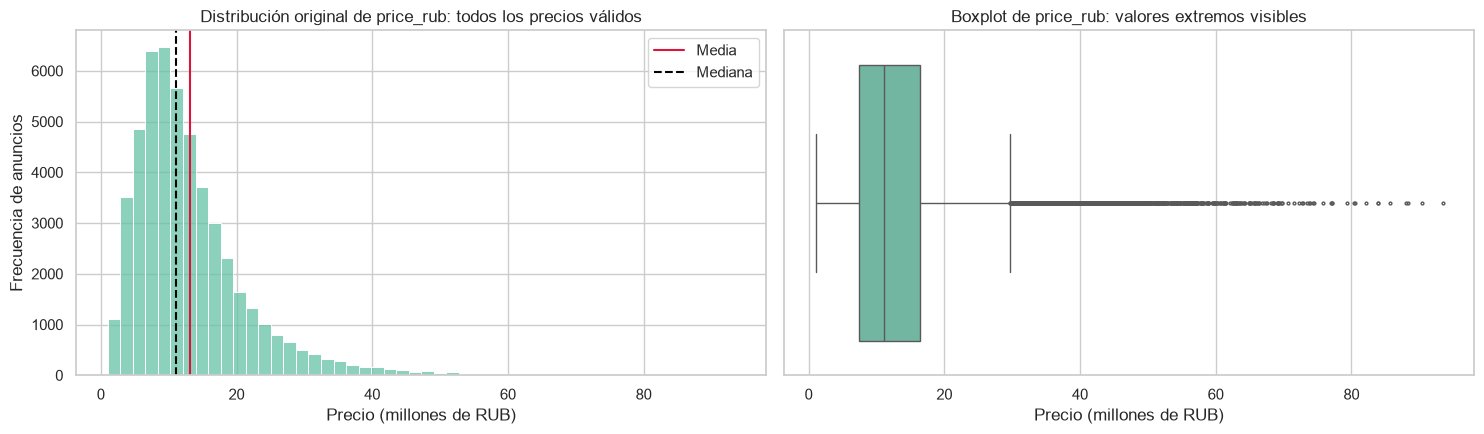

,anuncios,porcentaje_total
price_rub,,
Hasta 10 M RUB,21525,43.05
10 a 20 M RUB,20781,41.56
20 a 30 M RUB,5295,10.59
Más de 30 M RUB,2399,4.80


In [7]:
# Distribución original: conservar el DataFrame completo y su orden cronológico.
precio_valido = datos_univariados["price_rub"].notna() & np.isfinite(datos_univariados["price_rub"])
precios = datos_univariados.loc[precio_valido, "price_rub"]
if precios.empty:
    raise ValueError("No hay precios finitos disponibles para describir price_rub.")
mediana_precio = precios.median()
resumen_distribucion_precio = pd.Series({
    "registros_totales": len(datos_univariados),
    "precios_validos": precios.size,
    "precios_faltantes": datos_univariados["price_rub"].isna().sum(),
    "precios_no_finitos_no_nulos": (datos_univariados["price_rub"].notna() & ~precio_valido).sum(),
    "media_RUB": precios.mean(), "mediana_RUB": mediana_precio,
    "desv_estandar_RUB": precios.std(), "minimo_RUB": precios.min(),
    "maximo_RUB": precios.max(), "asimetria": precios.skew(),
}, name="valor")
display(resumen_distribucion_precio.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(precios / 1_000_000, bins=50, stat="count", ax=axes[0])
axes[0].axvline(precios.mean() / 1_000_000, color="crimson", label="Media")
axes[0].axvline(mediana_precio / 1_000_000, color="black", linestyle="--", label="Mediana")
axes[0].set(title="Distribución original de price_rub: todos los precios válidos",
            xlabel="Precio (millones de RUB)", ylabel="Frecuencia de anuncios")
axes[0].legend()
sns.boxplot(x=precios / 1_000_000, whis=1.5, showfliers=True, fliersize=2, ax=axes[1])
axes[1].set(title="Boxplot de price_rub: valores extremos visibles",
            xlabel="Precio (millones de RUB)")
fig.tight_layout()
plt.show()

rangos_precio = pd.cut(precios, bins=[-np.inf, 10e6, 20e6, 30e6, np.inf],
                      labels=["Hasta 10 M RUB", "10 a 20 M RUB", "20 a 30 M RUB", "Más de 30 M RUB"])
concentracion_precio = rangos_precio.value_counts(sort=False).to_frame("anuncios")
concentracion_precio["porcentaje_total"] = concentracion_precio["anuncios"] / len(datos_univariados) * 100
display(concentracion_precio)

<a id="diagnostico-outliers-precio"></a>

#### 3.3.1. Análisis exploratorio condicionado a los precios atípicos

In [9]:
n_outliers_diagnostico = len(outliers_precio)
numericas_outliers = [c for c in numericas_uni if c != "price_rub"]
# Estadísticos descriptivos de las demás variables, sin umbrales ni etiquetas nuevas.
diagnostico_distribuciones_outliers = outliers_precio[numericas_outliers].describe().T.rename(columns={
    "count": "n_validos", "mean": "media", "std": "desv_estandar", "min": "minimo",
    "25%": "Q1", "50%": "mediana", "75%": "Q3", "max": "maximo",
})
diagnostico_distribuciones_outliers["faltantes"] = outliers_precio[numericas_outliers].isna().sum()
diagnostico_distribuciones_outliers["asimetria"] = outliers_precio[numericas_outliers].skew()
display(diagnostico_distribuciones_outliers)

frecuencias_condicionadas_outliers = {}
for variable in categoricas_uni + binarias_uni:
    tabla = outliers_precio[variable].value_counts(dropna=False).rename_axis(variable).to_frame("anuncios")
    tabla["porcentaje_subconjunto"] = tabla["anuncios"] / (n_outliers_diagnostico or np.nan) * 100
    frecuencias_condicionadas_outliers[variable] = tabla
    print(f"Distribución de {variable} entre los anuncios con precio atípico")
    with pd.option_context("display.max_rows", None):
        display(tabla)

resumen_distritos_outliers = outliers_precio.groupby("district", dropna=False, observed=True).agg(
    anuncios=("id", "size"), precio_mediano_RUB=("price_rub", "median"),
    precio_min_RUB=("price_rub", "min"), precio_max_RUB=("price_rub", "max"),
    precio_desv_RUB=("price_rub", "std"),
    superficie_mediana_m2=("total_area", "median"), superficie_desv_m2=("total_area", "std"),
    distancia_centro_mediana_km=("to_center_km", "median"),
    habitaciones_mediana=("rooms", "median"),
)
resumen_distritos_outliers["porcentaje_subconjunto"] = resumen_distritos_outliers["anuncios"] / (n_outliers_diagnostico or np.nan) * 100
resumen_distritos_outliers = resumen_distritos_outliers.sort_values("anuncios", ascending=False, kind="stable")
print("Todos los distritos presentes en outliers_precio; porcentaje respecto del subconjunto completo.")
with pd.option_context("display.max_rows", None):
    display(resumen_distritos_outliers)

# Una etiqueta auxiliar para representar posibles distritos faltantes solo en los gráficos.
vista_distritos_outliers = outliers_precio.assign(
    distrito_grafico=outliers_precio["district"].astype("object").where(outliers_precio["district"].notna(), "(Sin distrito)"),
    precio_millones_RUB=outliers_precio["price_rub"] / 1e6,
)
orden_distritos_outliers = vista_distritos_outliers["distrito_grafico"].value_counts().index.tolist()
conteos_distritos_outliers = vista_distritos_outliers["distrito_grafico"].value_counts()
composicion_distritos_outliers = {}
for variable in ["rooms", "building_type", "renovation", "has_balcony"]:
    categorias_vista = vista_distritos_outliers[variable].astype("object").where(
        vista_distritos_outliers[variable].notna(), "(Sin dato)"
    ).astype(str)
    composicion = pd.crosstab(vista_distritos_outliers["distrito_grafico"], categorias_vista).reindex(orden_distritos_outliers)
    composicion_distritos_outliers[variable] = composicion.div(composicion.sum(axis=1), axis=0) * 100
    print(f"Composición de {variable} por distrito (% dentro de cada distrito del subconjunto)")
    with pd.option_context("display.max_rows", None):
        display(composicion_distritos_outliers[variable])

Distribución de district entre los anuncios con precio atípico
Distribución de okrug entre los anuncios con precio atípico
Distribución de building_type entre los anuncios con precio atípico
Distribución de renovation entre los anuncios con precio atípico
Distribución de metro_station entre los anuncios con precio atípico
Distribución de metro_line entre los anuncios con precio atípico
Distribución de metro_distance_type entre los anuncios con precio atípico
Distribución de seller_type entre los anuncios con precio atípico
Distribución de has_balcony entre los anuncios con precio atípico
Todos los distritos presentes en outliers_precio; porcentaje respecto del subconjunto completo.
Composición de rooms por distrito (% dentro de cada distrito del subconjunto)
Composición de building_type por distrito (% dentro de cada distrito del subconjunto)
Composición de renovation por distrito (% dentro de cada distrito del subconjunto)
Composición de has_balcony por distrito (% dentro de cada dist

,n_validos,media,desv_estandar,minimo,Q1,mediana,Q3,maximo,faltantes,asimetria
total_area,"2,459.00",81.86,17.66,32.40,68.70,80.50,93.75,134.30,0,0.31
living_area,"2,459.00",51.15,11.59,20.30,42.75,50.00,58.60,86.80,0,0.41
kitchen_area,"2,459.00",12.51,3.04,6.00,10.30,12.50,14.60,22.90,0,0.11
ceiling_height,"2,459.00",2.83,0.25,2.50,2.70,2.80,3.00,3.50,0,0.93
lat,"2,459.00",55.75,0.04,55.59,55.73,55.75,55.77,55.89,0,-0.73
lon,"2,459.00",37.59,0.06,37.36,37.56,37.59,37.62,37.82,0,-0.71
to_center_km,"2,459.00",4.77,3.57,0.12,2.42,3.60,5.71,19.49,0,1.51
metro_to_center_km,"2,459.00",4.36,3.70,0.33,1.77,2.83,5.65,20.02,0,1.51
metro_lat,"2,459.00",55.75,0.04,55.60,55.74,55.75,55.77,55.86,0,-1.12
metro_lon,"2,459.00",37.59,0.06,37.36,37.57,37.60,37.63,37.81,0,-0.67


,anuncios,porcentaje_subconjunto
district,,
Tverskoy,256,10.41
Khamovniki,255,10.37
Arbat,248,10.09
Presnensky,218,8.87
Yakimanka,199,8.09
Zamoskvorechye,152,6.18
Meshchansky,136,5.53
Dorogomilovo,113,4.60
Basmanny,102,4.15


,anuncios,porcentaje_subconjunto
okrug,,
CAO,1724,70.11
ZAO,264,10.74
YuZAO,209,8.50
SZAO,95,3.86
SAO,91,3.70
VAO,29,1.18
SVAO,25,1.02
YuAO,22,0.89


,anuncios,porcentaje_subconjunto
building_type,,
monolith,591,24.03
modern_panel,485,19.72
brick,485,19.72
panel,378,15.37
stalin,340,13.83
khrushchev,180,7.32


...

,anuncios,precio_mediano_RUB,precio_min_RUB,precio_max_RUB,precio_desv_RUB,superficie_mediana_m2,superficie_desv_m2,distancia_centro_mediana_km,habitaciones_mediana,porcentaje_subconjunto
district,,,,,,,,,,
Tverskoy,256,"39,375,000.00",29780000,88296000,"9,921,462.89",72.35,15.44,2.26,2.00,10.41
Khamovniki,255,"40,011,000.00",29792000,87970000,"11,219,022.20",74.00,16.14,3.71,3.00,10.37
Arbat,248,"39,387,500.00",29819000,93437000,"11,127,650.94",73.40,16.90,2.06,2.00,10.09
Presnensky,218,"38,983,500.00",29749000,85618000,"10,402,473.86",71.85,15.23,3.10,2.00,8.87
Yakimanka,199,"37,839,000.00",29770000,77193000,"9,097,189.67",72.00,15.65,3.01,2.00,8.09
Zamoskvorechye,152,"36,275,500.00",29752000,67519000,"9,017,287.36",76.80,14.48,2.29,3.00,6.18
Meshchansky,136,"36,054,500.00",29775000,82096000,"8,942,870.22",78.45,15.95,3.12,3.00,5.53
Dorogomilovo,113,"34,315,000.00",29895000,63435000,"6,995,771.65",83.60,16.03,4.45,3.00,4.60
Basmanny,102,"34,197,500.00",29860000,59736000,"6,443,351.46",82.15,16.02,3.85,3.00,4.15


rooms,1,2,3,4,5
distrito_grafico,,,,,
Tverskoy,11.72,43.36,27.34,13.28,4.30
Khamovniki,8.63,40.78,31.37,12.55,6.67
Arbat,11.29,41.94,29.03,12.90,4.84
Presnensky,12.39,40.37,33.94,10.09,3.21
Yakimanka,12.06,42.71,25.63,15.08,4.52
Zamoskvorechye,7.89,36.84,34.21,17.76,3.29
Meshchansky,7.35,35.29,33.09,13.97,10.29
Dorogomilovo,1.77,39.82,33.63,15.04,9.73
Basmanny,5.88,27.45,36.27,18.63,11.76


building_type,brick,khrushchev,modern_panel,monolith,panel,stalin
distrito_grafico,,,,,,
Tverskoy,19.53,9.77,19.53,21.09,19.53,10.55
Khamovniki,18.43,10.59,18.82,21.57,19.61,10.98
Arbat,20.56,10.89,17.34,18.55,22.18,10.48
Presnensky,15.14,10.55,23.85,22.94,14.22,13.30
Yakimanka,22.61,4.52,23.12,23.62,17.09,9.05
Zamoskvorechye,23.03,7.89,19.08,29.61,12.50,7.89
Meshchansky,20.59,6.62,18.38,21.32,20.59,12.50
Dorogomilovo,16.81,5.31,21.24,25.66,15.93,15.04
Basmanny,13.73,6.86,25.49,24.51,7.84,21.57


renovation,cosmetic,designer,euro,no_renovation
distrito_grafico,,,,
Tverskoy,35.16,14.84,34.77,15.23
Khamovniki,38.04,14.51,32.94,14.51
Arbat,35.89,12.50,33.06,18.55
Presnensky,38.53,13.30,38.07,10.09
Yakimanka,42.21,9.05,33.67,15.08
Zamoskvorechye,30.26,15.13,40.79,13.82
Meshchansky,27.94,25.00,38.24,8.82
Dorogomilovo,28.32,19.47,44.25,7.96
Basmanny,26.47,23.53,38.24,11.76


has_balcony,False,True
distrito_grafico,,
Tverskoy,20.70,79.30
Khamovniki,16.47,83.53
Arbat,27.42,72.58
Presnensky,31.19,68.81
Yakimanka,26.13,73.87
Zamoskvorechye,19.08,80.92
Meshchansky,23.53,76.47
Dorogomilovo,27.43,72.57
Basmanny,23.53,76.47


In [10]:
reglas_calidad_outliers = {}
for variable in ["total_area", "living_area", "kitchen_area", "ceiling_height", "price_rub", "price_per_sqm"]:
    reglas_calidad_outliers[f"{variable} <= 0"] = outliers_precio[variable].le(0)
for variable in ["rooms", "floor", "total_floors", "metro_distance_min", "to_center_km", "metro_to_center_km"]:
    reglas_calidad_outliers[f"{variable} < 0"] = outliers_precio[variable].lt(0)
for variable in ["rooms", "floor", "total_floors", "n_listings_secondary", "n_listings_newbuild", *anios_uni]:
    reglas_calidad_outliers[f"{variable} no entero"] = outliers_precio[variable].mod(1).ne(0) & outliers_precio[variable].notna()
reglas_calidad_outliers.update({
    "living_area + kitchen_area > total_area": (
        outliers_precio["living_area"] + outliers_precio["kitchen_area"]
        > outliers_precio["total_area"] + 1e-9
    ),
    "floor > total_floors": outliers_precio["floor"].gt(outliers_precio["total_floors"]),
    "building_year > anio de publicacion": outliers_precio["building_year"].gt(outliers_precio["date_posted_dt"].dt.year),
    "metro_year_opened > anio de publicacion": outliers_precio["metro_year_opened"].gt(outliers_precio["date_posted_dt"].dt.year),
    "latitud fuera de [-90, 90]": ~outliers_precio["lat"].between(-90, 90) & outliers_precio["lat"].notna(),
    "longitud fuera de [-180, 180]": ~outliers_precio["lon"].between(-180, 180) & outliers_precio["lon"].notna(),
})

for variable, inferior, superior in [("metro_lat", -90, 90), ("metro_lon", -180, 180)]:
    reglas_calidad_outliers[f"{variable} fuera de [{inferior}, {superior}]"] = (
        ~outliers_precio[variable].between(inferior, superior) & outliers_precio[variable].notna()
    )
for variable in outliers_precio.columns:
    reglas_calidad_outliers[f"{variable}: faltante"] = outliers_precio[variable].isna()
for variable in numericas_outliers:
    reglas_calidad_outliers[f"{variable}: no finito no nulo"] = (
        outliers_precio[variable].notna() & ~np.isfinite(outliers_precio[variable])
    )
resumen_calidad_outliers = pd.DataFrame([
    {"regla": nombre, "registros": int(mascara.sum()),
     "porcentaje_subconjunto": mascara.sum() / (n_outliers_diagnostico or np.nan) * 100}
    for nombre, mascara in reglas_calidad_outliers.items()
])
inconsistencias_outliers = resumen_calidad_outliers.loc[resumen_calidad_outliers["registros"].gt(0)].copy()
print(f"Reglas revisadas: {len(resumen_calidad_outliers)}; "
      f"sin alertas: {resumen_calidad_outliers['registros'].eq(0).sum()}. "
      f"Denominador: {n_outliers_diagnostico:,} registros con precio atípico.")
display(inconsistencias_outliers)
# Una misma propiedad puede aparecer en varias reglas; no se suman como casos independientes.
mascara_alguna_alerta_outliers = pd.DataFrame(reglas_calidad_outliers).any(axis=1)
resumen_casos_calidad_outliers = pd.Series({
    "registros_subconjunto": n_outliers_diagnostico,
    "con_alguna_alerta": int(mascara_alguna_alerta_outliers.sum()),
    "con_alguna_alerta_pct": mascara_alguna_alerta_outliers.sum() / (n_outliers_diagnostico or np.nan) * 100,
    "filas_duplicadas": int(outliers_precio.duplicated().sum()),
    "id_repetidos": int(outliers_precio["id"].duplicated().sum()),
}, name="valor")
display(resumen_casos_calidad_outliers.to_frame())
faltantes_columnas_outliers = pd.DataFrame({
    "faltantes": outliers_precio.isna().sum(),
    "faltantes_pct_subconjunto": outliers_precio.isna().sum() / (n_outliers_diagnostico or np.nan) * 100,
})
display(faltantes_columnas_outliers.loc[faltantes_columnas_outliers["faltantes"].gt(0)])
faltantes_contexto_outliers = outliers_precio.groupby("year_month", dropna=False)[[
    "secondary_mom_change_pct", "newbuild_mom_change_pct"
]].agg(lambda columna: columna.isna().sum())
display(faltantes_contexto_outliers.loc[faltantes_contexto_outliers.sum(axis=1).gt(0)])
pd.testing.assert_frame_equal(outliers_precio, df_venta_enriquecido.loc[extremos_precio])
pd.testing.assert_frame_equal(datos_univariados, df_venta_enriquecido)
assert df_venta_enriquecido["date_posted_dt"].dropna().is_monotonic_increasing

Reglas revisadas: 93; sin alertas: 89. Denominador: 2,459 registros con precio atípico.


,regla,registros,porcentaje_subconjunto
19,living_area + kitchen_area > total_area,1,0.04
21,building_year > anio de publicacion,46,1.87
57,secondary_mom_change_pct: faltante,9,0.37
58,newbuild_mom_change_pct: faltante,9,0.37


,valor
registros_subconjunto,"2,459.00"
con_alguna_alerta,54.00
con_alguna_alerta_pct,2.20
filas_duplicadas,0.00
id_repetidos,0.00


,faltantes,faltantes_pct_subconjunto
secondary_mom_change_pct,9,0.37
newbuild_mom_change_pct,9,0.37


,secondary_mom_change_pct,newbuild_mom_change_pct
year_month,,
2020-01,9,9


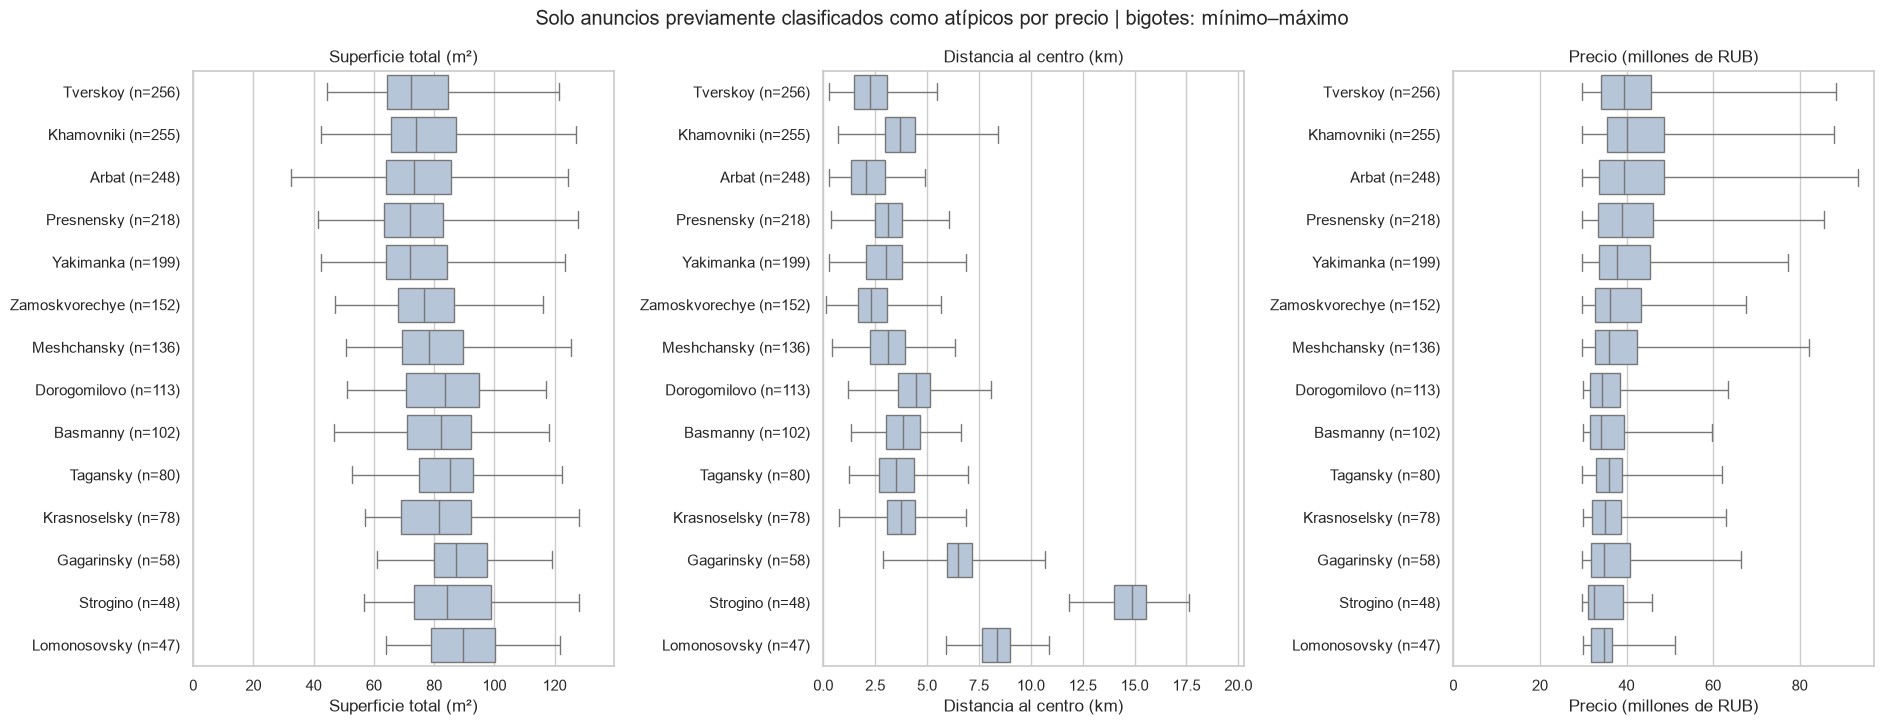

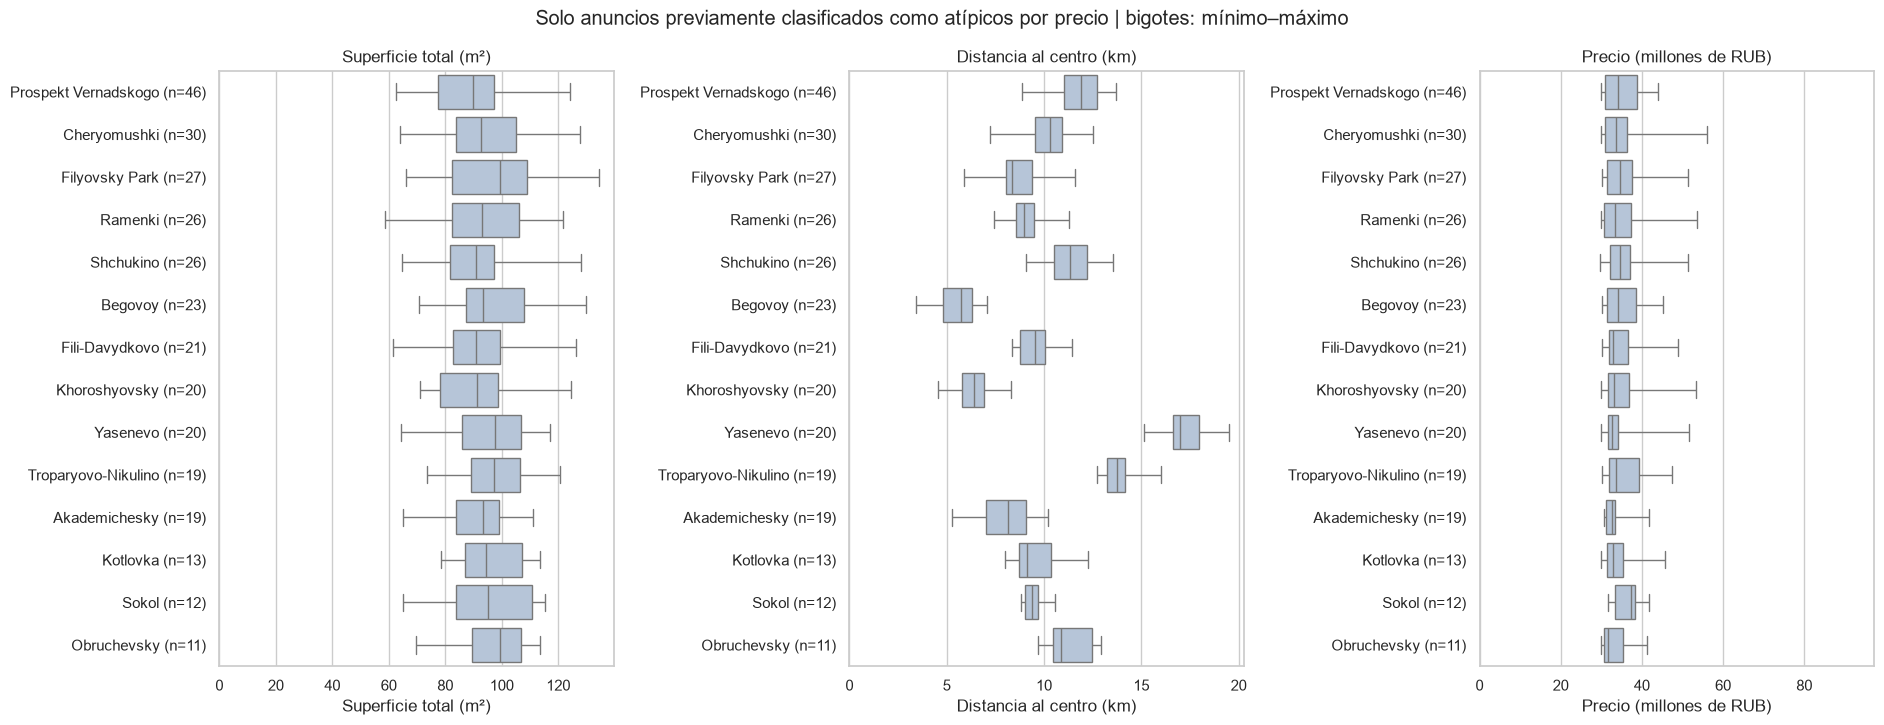

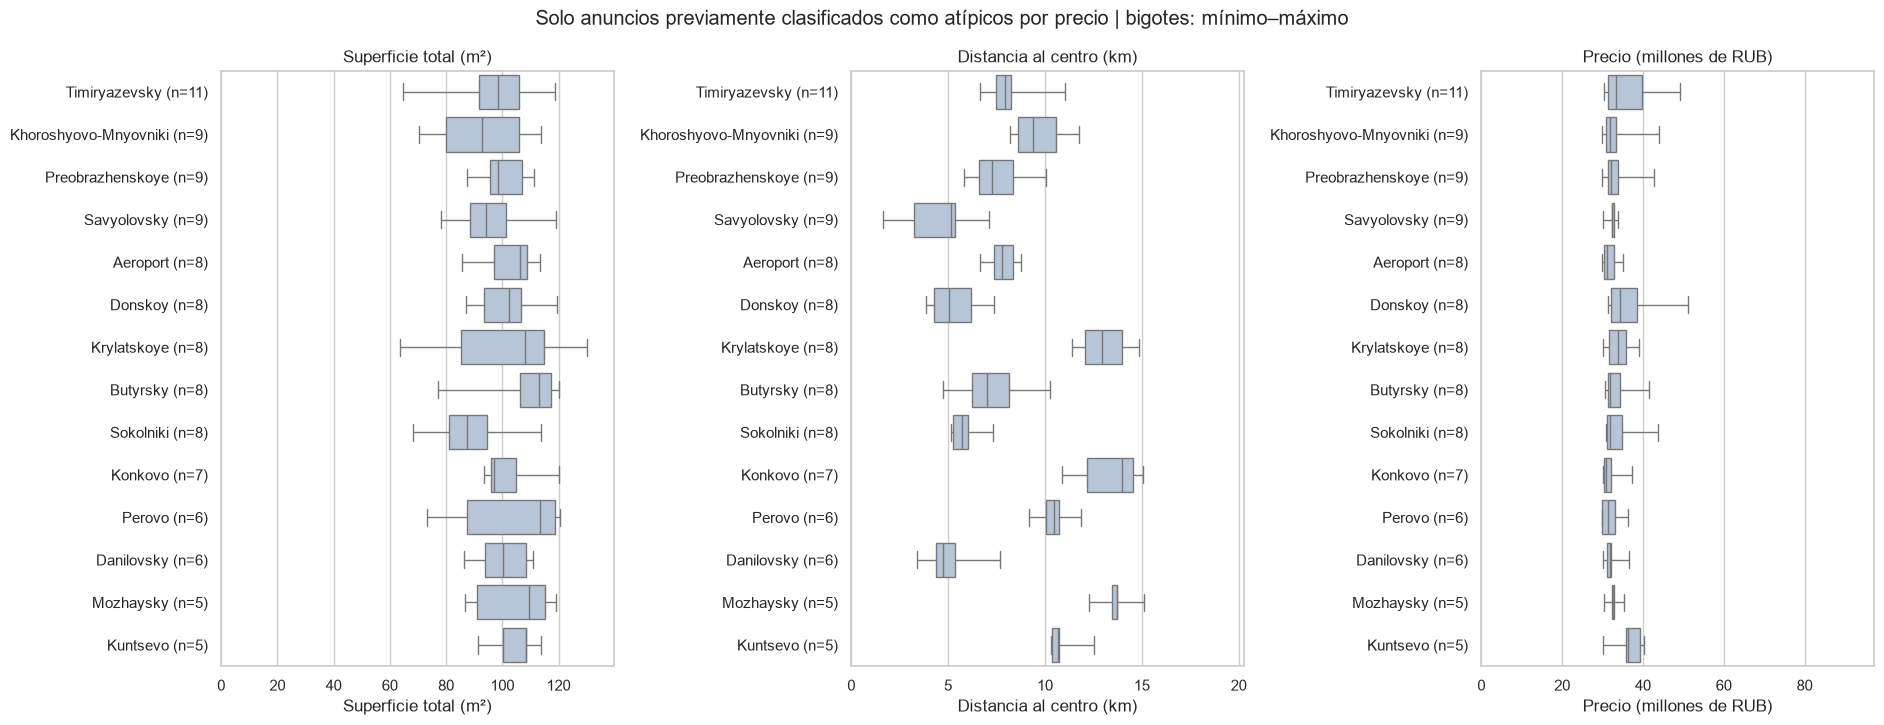

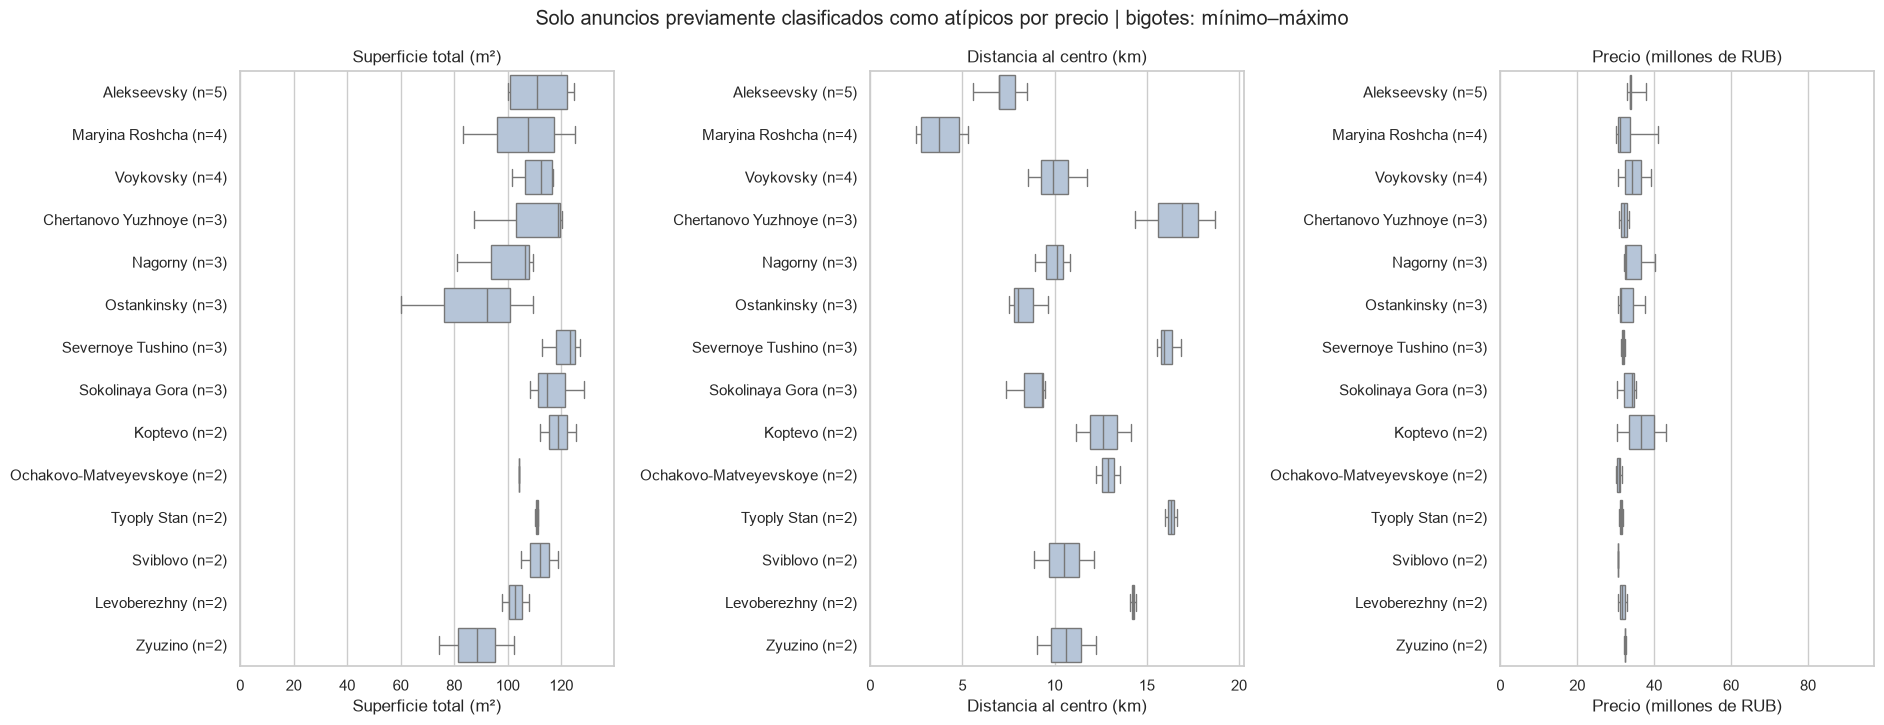

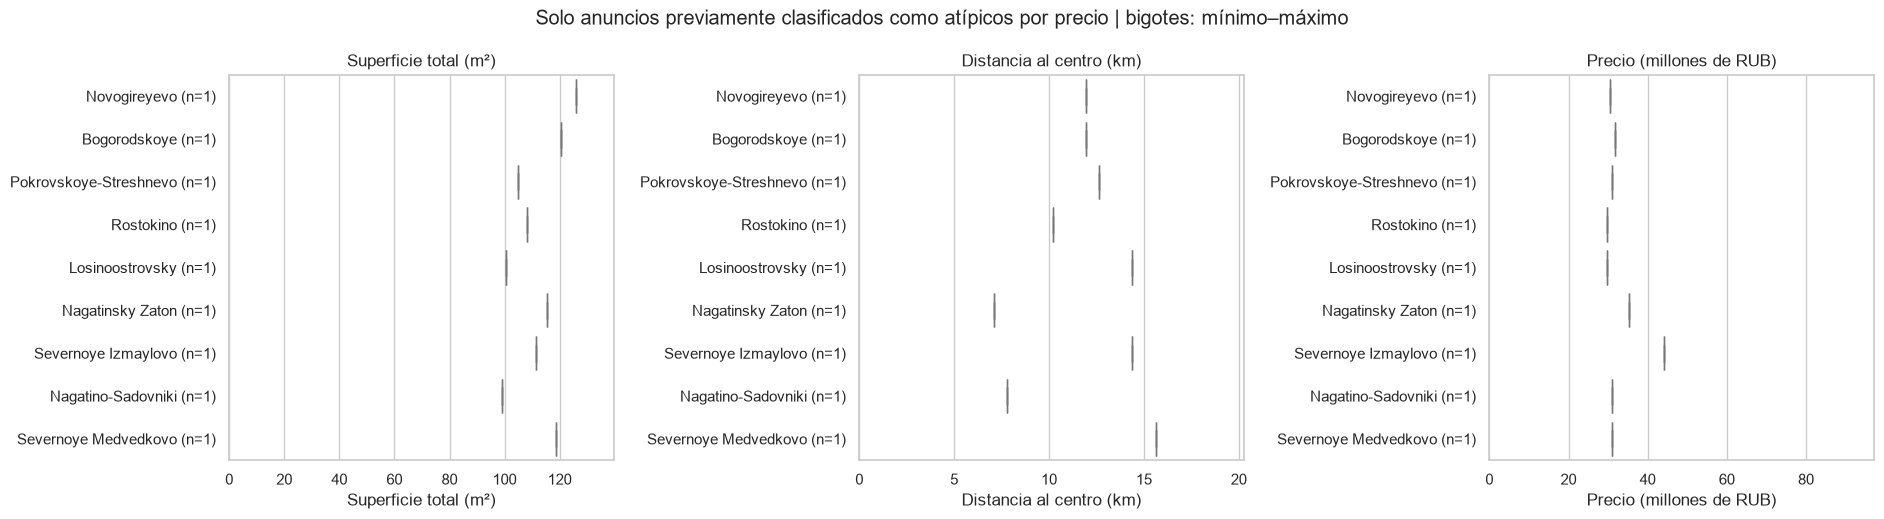

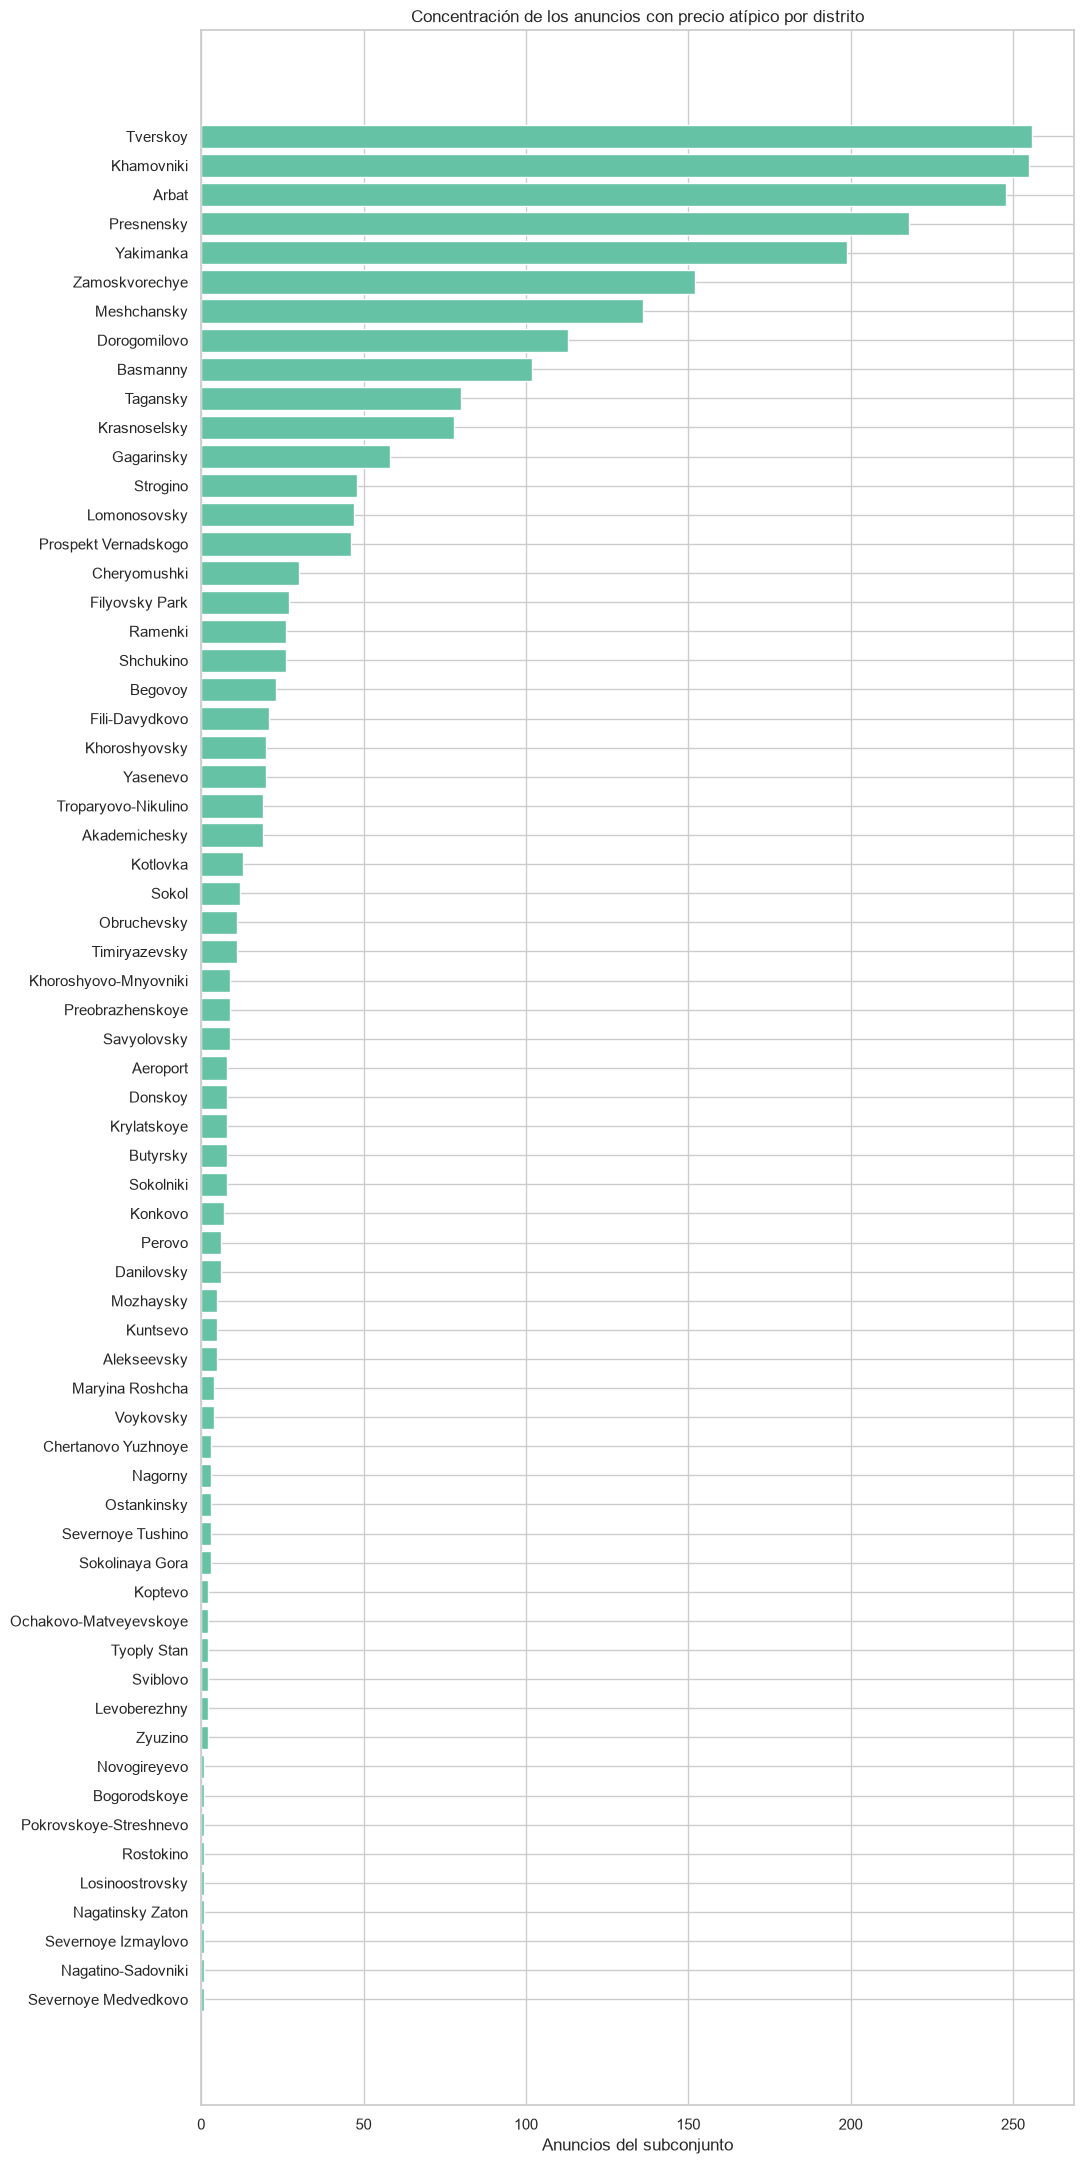

In [11]:
variables_boxplot_outliers = [
    ("total_area", "Superficie total (m²)"),
    ("to_center_km", "Distancia al centro (km)"),
    ("precio_millones_RUB", "Precio (millones de RUB)"),
]
for inicio in range(0, len(orden_distritos_outliers), 14):
    lote_distritos = orden_distritos_outliers[inicio:inicio + 14]
    lote_datos = vista_distritos_outliers.loc[vista_distritos_outliers["distrito_grafico"].isin(lote_distritos)]
    fig, axes = plt.subplots(1, 3, figsize=(19, max(3, .42 * len(lote_distritos) + 1.5)))
    for ax, (variable, etiqueta) in zip(axes, variables_boxplot_outliers):
        sns.boxplot(data=lote_datos, x=variable, y="distrito_grafico", order=lote_distritos,
                    whis=(0, 100), showfliers=False, color="lightsteelblue", ax=ax)
        ax.set_yticks(range(len(lote_distritos)), labels=[
            f"{d} (n={conteos_distritos_outliers.loc[d]:,})" for d in lote_distritos
        ])
        maximo_vista = vista_distritos_outliers[variable].max()
        ax.set(xlim=(0, maximo_vista * 1.04 if pd.notna(maximo_vista) and maximo_vista > 0 else 1),
               xlabel=etiqueta, ylabel="", title=etiqueta)
    fig.suptitle("Solo anuncios previamente clasificados como atípicos por precio | bigotes: mínimo–máximo")
    fig.tight_layout()
    plt.show()

if orden_distritos_outliers:
    fig, ax = plt.subplots(figsize=(11, max(3, .32 * len(orden_distritos_outliers) + 1)))
    ax.barh(orden_distritos_outliers, conteos_distritos_outliers.reindex(orden_distritos_outliers))
    ax.invert_yaxis()
    ax.set(title="Concentración de los anuncios con precio atípico por distrito", xlabel="Anuncios del subconjunto", ylabel="")
    fig.tight_layout()
    plt.show()
pd.testing.assert_frame_equal(outliers_precio, df_venta_enriquecido.loc[extremos_precio])
pd.testing.assert_frame_equal(datos_univariados, df_venta_enriquecido)

In [12]:
from IPython.display import Markdown

if n_outliers_diagnostico:
    lider = resumen_distritos_outliers.iloc[0]
    nombre_lider = resumen_distritos_outliers.index[0]
    top3 = resumen_distritos_outliers.head(3)
    medianas_distritos = resumen_distritos_outliers["precio_mediano_RUB"]
    grupos_pequenos = int(resumen_distritos_outliers["anuncios"].lt(5).sum())
    detalle_top3 = "; ".join(
        f"{distrito}: {int(fila.anuncios):,} anuncios ({fila.porcentaje_subconjunto:.2f} %)"
        for distrito, fila in top3.iterrows()
    )
    contraste_distritos = ""
    if "Strogino" in resumen_distritos_outliers.index:
        comparador = resumen_distritos_outliers.loc["Strogino"]
        contraste_distritos = (
            f"Por ejemplo, {nombre_lider} (n={int(lider.anuncios):,}) tiene una superficie mediana de "
            f"{lider.superficie_mediana_m2:.2f} m², distancia mediana al centro de "
            f"{lider.distancia_centro_mediana_km:.2f} km y precio mediano de "
            f"{lider.precio_mediano_RUB/1e6:.2f} M RUB. Strogino (n={int(comparador.anuncios):,}) "
            f"presenta {comparador.superficie_mediana_m2:.2f} m², "
            f"{comparador.distancia_centro_mediana_km:.2f} km y "
            f"{comparador.precio_mediano_RUB/1e6:.2f} M RUB, respectivamente. "
            f"La desviación estándar del precio es {lider.precio_desv_RUB/1e6:.2f} frente a "
            f"{comparador.precio_desv_RUB/1e6:.2f} M RUB. En estos dos distritos, los precios "
            "atípicos corresponden a perfiles distintos: el distrito más cercano al centro tiene "
            "menor superficie mediana y mayor nivel y dispersión del precio. Es una asociación "
            "descriptiva dentro de la selección original, sin aislar el efecto de la ubicación. "
        )
    display(Markdown(
        f"**Concentración por distrito:** {len(resumen_distritos_outliers)} distritos están representados. "
        f"Los tres con más anuncios reúnen el {top3['porcentaje_subconjunto'].sum():.2f} % del subconjunto: "
        f"{detalle_top3}. Esta concentración describe dónde se ubican los precios atípicos observados; "
        "no mide la probabilidad de que un anuncio de cada distrito sea atípico, porque no se usa como denominador su oferta total.\n\n"
        f"**Características y dispersión:** en el subconjunto completo, la superficie total mediana es "
        f"{outliers_precio['total_area'].median():.2f} m² y la distancia mediana al centro es "
        f"{outliers_precio['to_center_km'].median():.2f} km. Las medianas distritales del precio van de "
        f"{medianas_distritos.min()/1e6:.2f} a {medianas_distritos.max()/1e6:.2f} M RUB. "
        f"{contraste_distritos}"
        "Los boxplots permiten contrastar el nivel y la amplitud de superficies, distancias y precios; "
        "las tablas de composición muestran cómo varían habitaciones, tipo de edificio, renovación y balcón. "
        f"Hay {grupos_pequenos} distritos con menos de cinco anuncios: sus resúmenes son especialmente sensibles "
        "a casos individuales. Una desviación estándar no está definida cuando solo hay un anuncio.\n\n"
        "**Alcance:** las diferencias son descriptivas y están condicionadas a la selección original por precio. "
        "La localización y las características observadas pueden acompañar los precios elevados, pero estas "
        "comparaciones no aíslan sus contribuciones ni establecen causalidad. Las alertas físicas y los faltantes "
        "se informan por separado; no cambian la pertenencia al subconjunto. No se aplica una segunda detección de atípicos."
    ))
else:
    display(Markdown("El subconjunto previamente identificado está vacío; no hay distribuciones por distrito que interpretar."))


**Concentración por distrito:** 65 distritos están representados. Los tres con más anuncios reúnen el 30.87 % del subconjunto: Tverskoy: 256 anuncios (10.41 %); Khamovniki: 255 anuncios (10.37 %); Arbat: 248 anuncios (10.09 %). Esta concentración describe dónde se ubican los precios atípicos observados; no mide la probabilidad de que un anuncio de cada distrito sea atípico, porque no se usa como denominador su oferta total.

**Características y dispersión:** en el subconjunto completo, la superficie total mediana es 80.50 m² y la distancia mediana al centro es 3.60 km. Las medianas distritales del precio van de 29.76 a 44.03 M RUB. Por ejemplo, Tverskoy (n=256) tiene una superficie mediana de 72.35 m², distancia mediana al centro de 2.26 km y precio mediano de 39.38 M RUB. Strogino (n=48) presenta 84.30 m², 14.87 km y 32.44 M RUB, respectivamente. La desviación estándar del precio es 9.92 frente a 4.83 M RUB. En estos dos distritos, los precios atípicos corresponden a perfiles distintos: el distrito más cercano al centro tiene menor superficie mediana y mayor nivel y dispersión del precio. Es una asociación descriptiva dentro de la selección original, sin aislar el efecto de la ubicación. Los boxplots permiten contrastar el nivel y la amplitud de superficies, distancias y precios; las tablas de composición muestran cómo varían habitaciones, tipo de edificio, renovación y balcón. Hay 22 distritos con menos de cinco anuncios: sus resúmenes son especialmente sensibles a casos individuales. Una desviación estándar no está definida cuando solo hay un anuncio.

**Alcance:** las diferencias son descriptivas y están condicionadas a la selección original por precio. La localización y las características observadas pueden acompañar los precios elevados, pero estas comparaciones no aíslan sus contribuciones ni establecen causalidad. Las alertas físicas y los faltantes se informan por separado; no cambian la pertenencia al subconjunto. No se aplica una segunda detección de atípicos.

<a id="caracteristicas-predictoras"></a>

### 3.4. Análisis de las características predictora

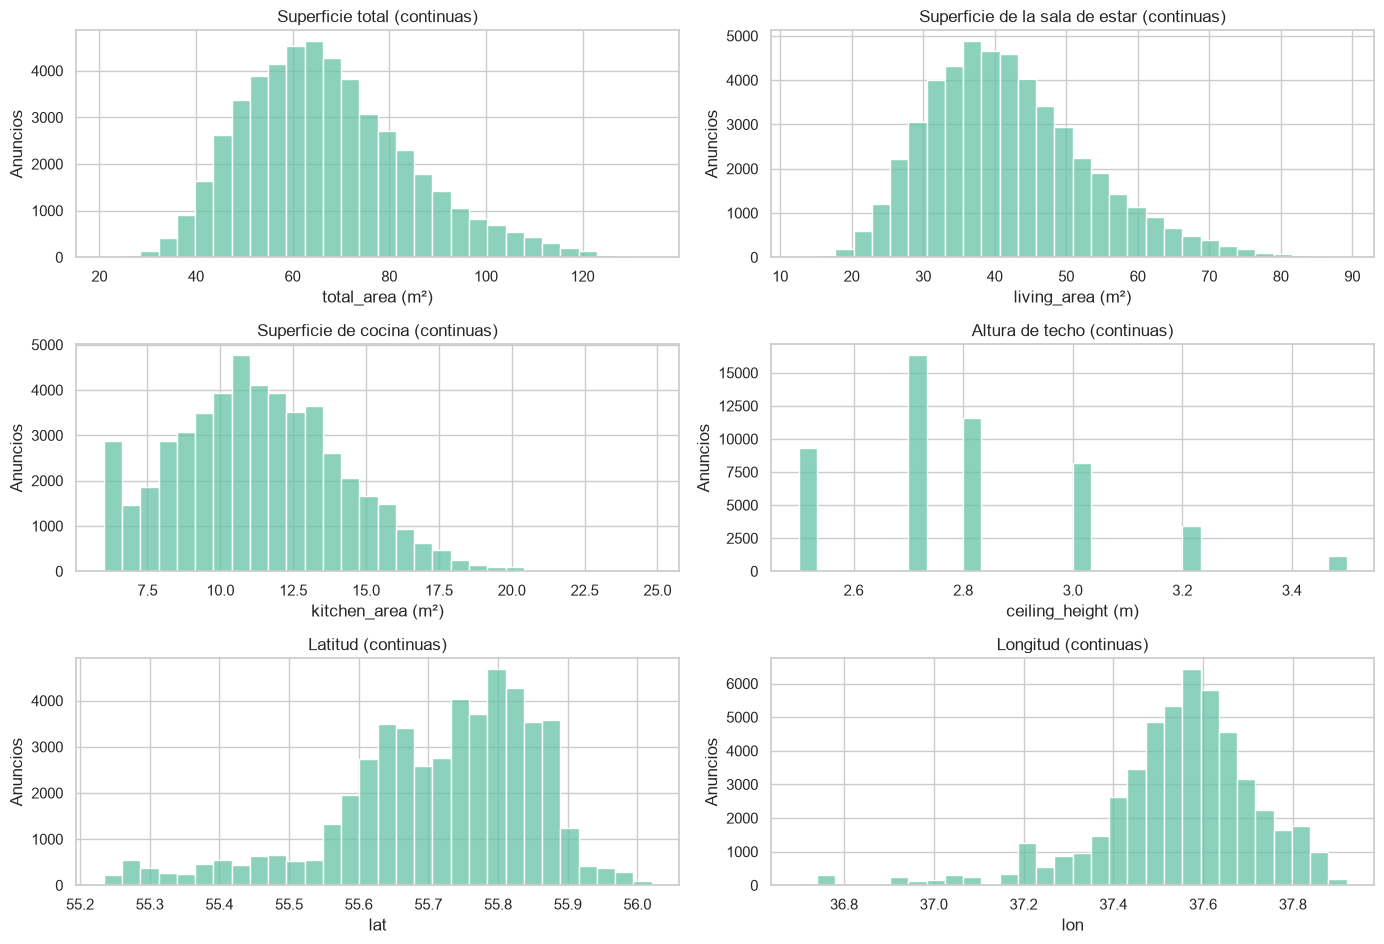

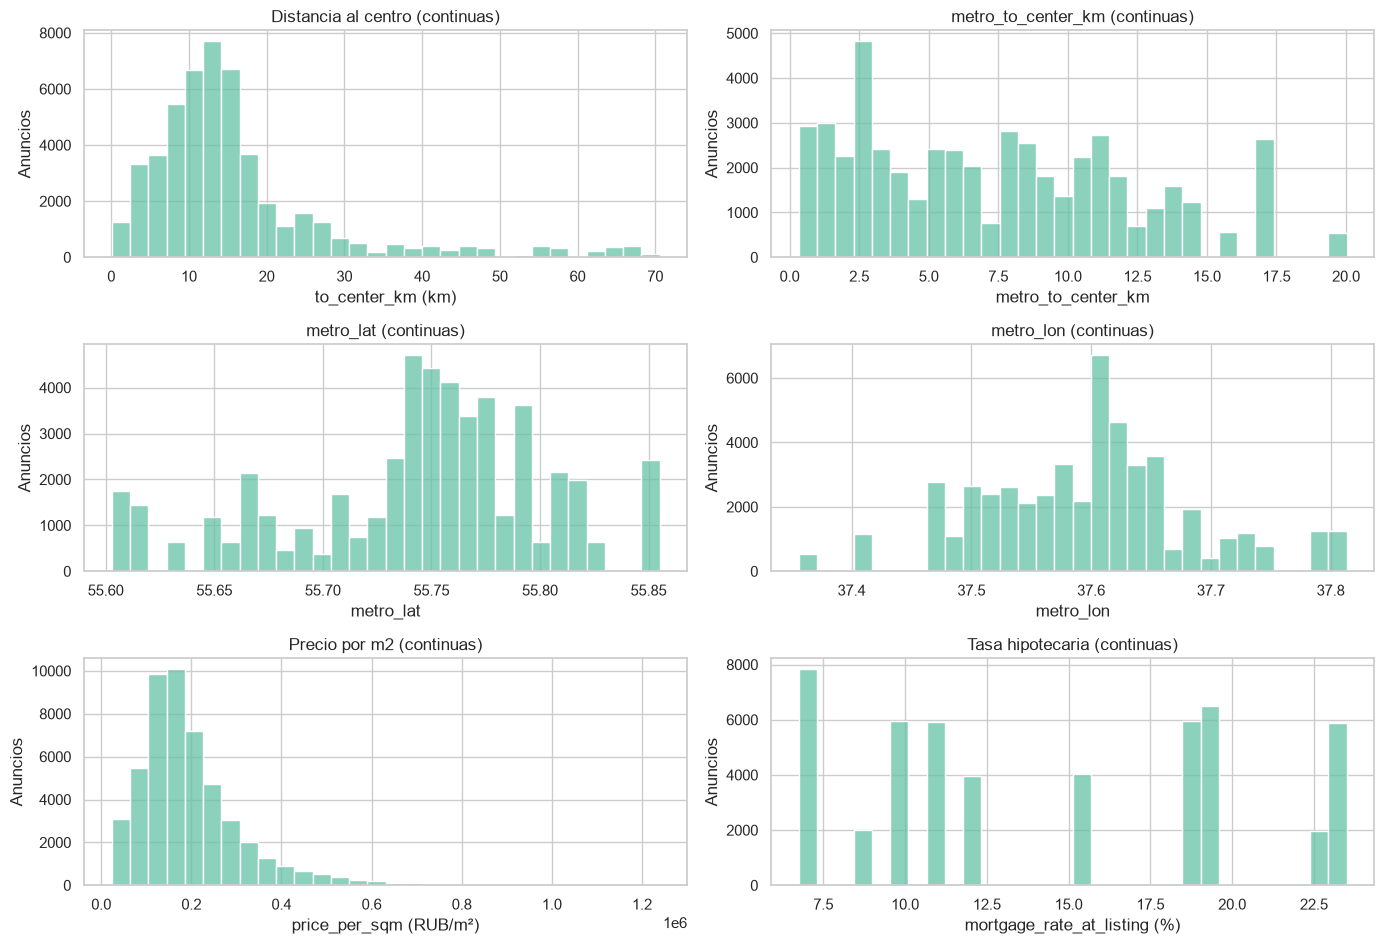

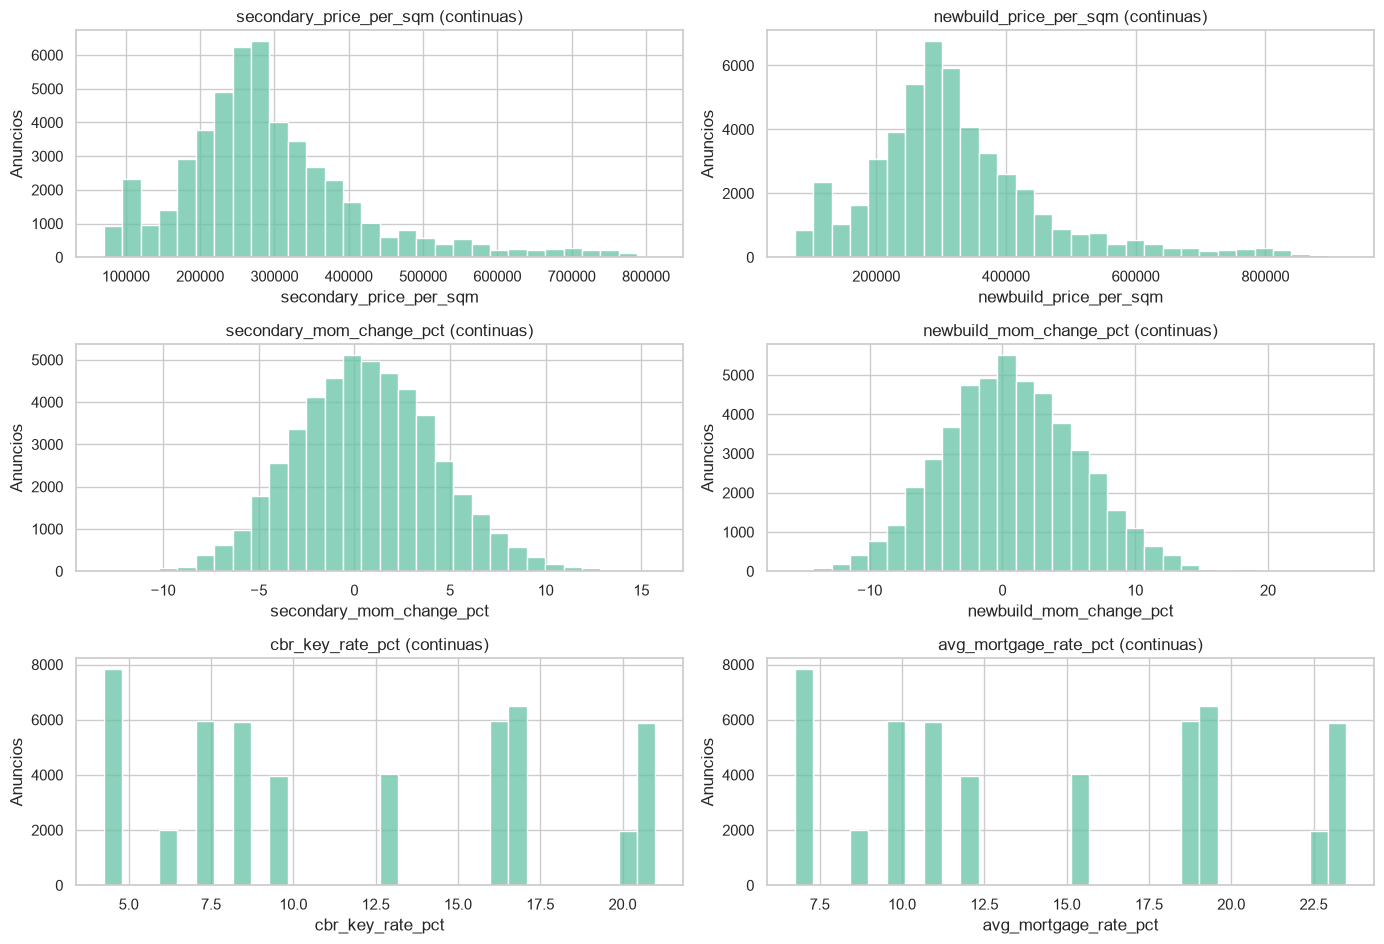

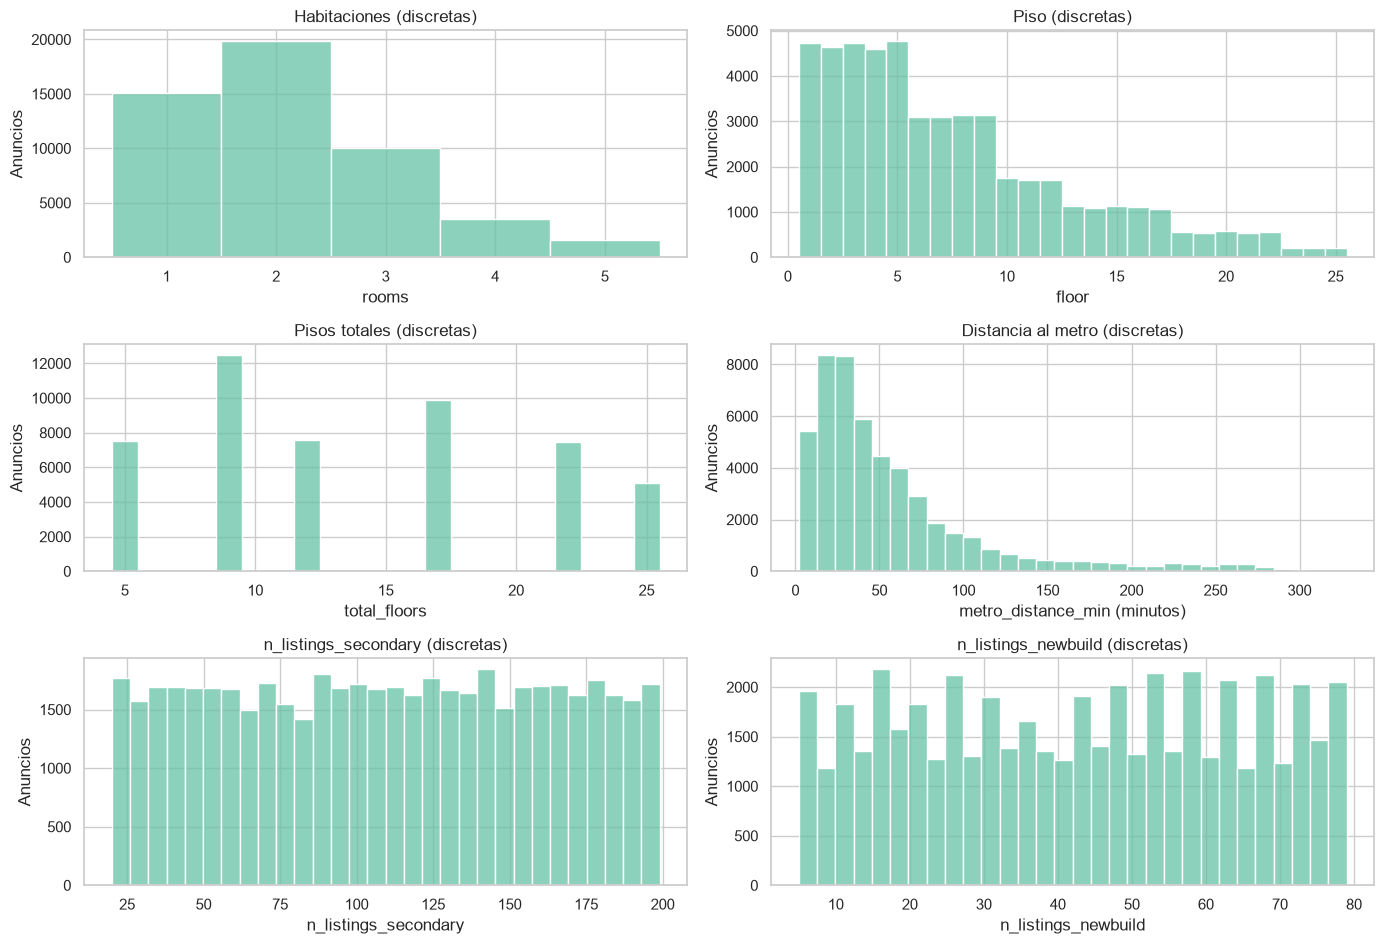

In [13]:
for naturaleza, variables in [("Continuas", continuas_uni), ("Discretas", discretas_uni)]:
    # Lotes pequenos para mantener legibles las escalas y etiquetas.
    for inicio in range(0, len(variables), 6):
        lote = variables[inicio:inicio + 6]
        fig, axes = plt.subplots(int(np.ceil(len(lote) / 2)), 2,
                                 figsize=(14, 3.2 * int(np.ceil(len(lote) / 2))), squeeze=False)
        for ax, variable in zip(axes.flat, lote):
            serie = datos_univariados[variable].dropna()
            discreta = naturaleza == "Discretas" and serie.nunique() <= 30
            sns.histplot(serie, discrete=discreta, bins="auto" if discreta else 30, ax=ax)
            titulo = CONFIG["labels"].get(variable, variable)
            unidad = CONFIG["units"].get(variable, "")
            ax.set(title=f"{titulo} ({naturaleza.lower()})",
                   xlabel=f"{variable} ({unidad})" if unidad else variable, ylabel="Anuncios")
        for ax in list(axes.flat)[len(lote):]:
            ax.set_visible(False)
        fig.tight_layout()
        plt.show()

district
Otras 119 categorias: 91.6% del total; incluidas en la tabla.
okrug
building_type
renovation
metro_station
Otras 94 categorias: 83.5% del total; incluidas en la tabla.
metro_line
metro_distance_type
seller_type
has_balcony


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,Otras (119 categorias),45783,91.57
1,Begovoy,434,0.87
2,Yasenevo,430,0.86
3,Mikhaylovo-Yartsevskoye,427,0.85
4,Voronovskoye,422,0.84
5,Timiryazevsky,421,0.84
6,Orekhovo-Borisovo Yuzhnoye,419,0.84
7,Akademichesky,418,0.84
8,Lomonosovsky,416,0.83
9,Tsaritsyno,415,0.83


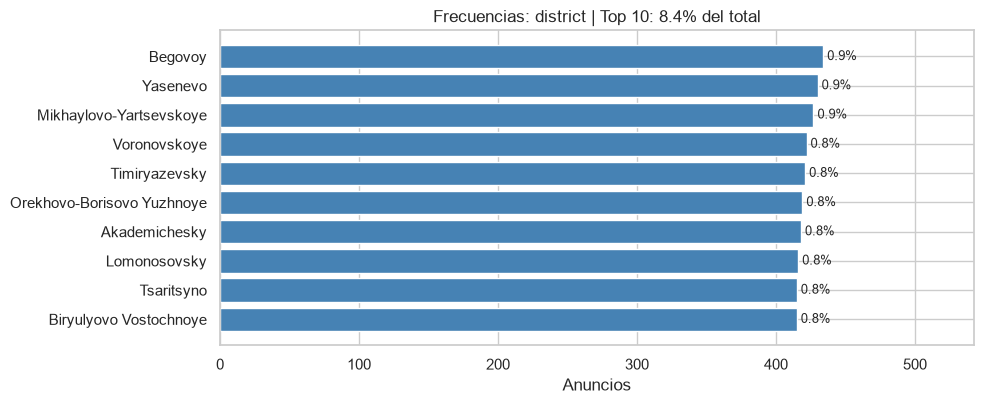

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,SVAO,6662,13.32
1,YuAO,6218,12.44
2,VAO,6091,12.18
3,SAO,5856,11.71
4,YuZAO,4758,9.52
5,ZAO,4617,9.23
6,NAO,4167,8.33
7,TAO,3950,7.90
8,CAO,3899,7.80
9,SZAO,3421,6.84


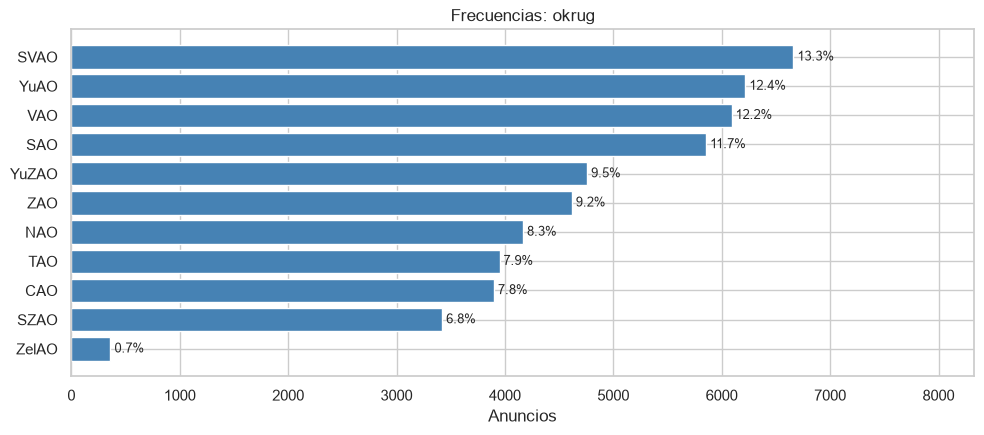

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,panel,10143,20.29
1,monolith,9997,19.99
2,modern_panel,9981,19.96
3,brick,8836,17.67
4,khrushchev,7528,15.06
5,stalin,3515,7.03


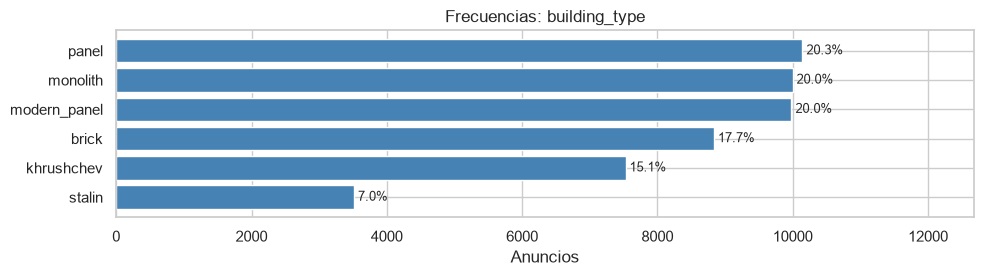

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,cosmetic,20057,40.11
1,euro,14969,29.94
2,no_renovation,10029,20.06
3,designer,4945,9.89


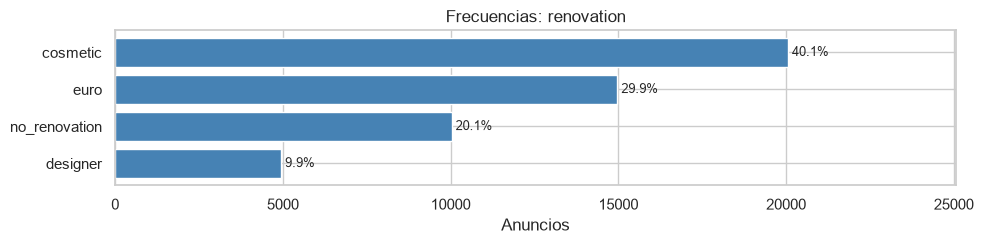

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,Otras (94 categorias),41745,83.49
1,Rechnoy Vokzal,953,1.91
2,Sviblovo,926,1.85
3,Yasenevo,914,1.83
4,Tyoply Stan,872,1.74
5,Ulitsa Akademika Yangelya,845,1.69
6,Novye Cheryomushki,784,1.57
7,Shchukinskaya,743,1.49
8,Perovo,743,1.49
9,Timiryazevskaya,740,1.48


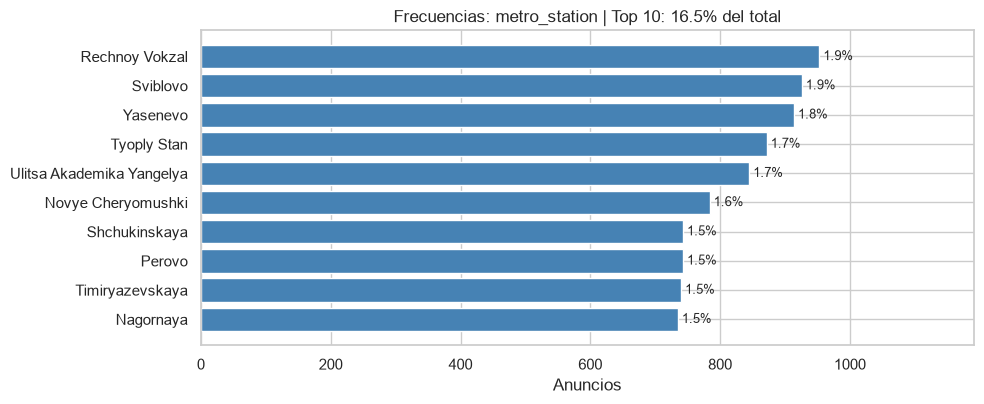

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,Kaluzhsko-Rizhskaya,7165,14.33
1,Serpukhovsko-Timiryazevskaya,6745,13.49
2,Sokolnicheskaya,6408,12.82
3,Arbatsko-Pokrovskaya,5770,11.54
4,Zamoskvoretskaya,5014,10.03
5,Koltsevaya,4169,8.34
6,Filyovskaya,4081,8.16
7,Tagansko-Krasnopresnenskaya,3423,6.85
8,Lyublinsko-Dmitrovskaya,3006,6.01
9,Kalininskaya,2375,4.75


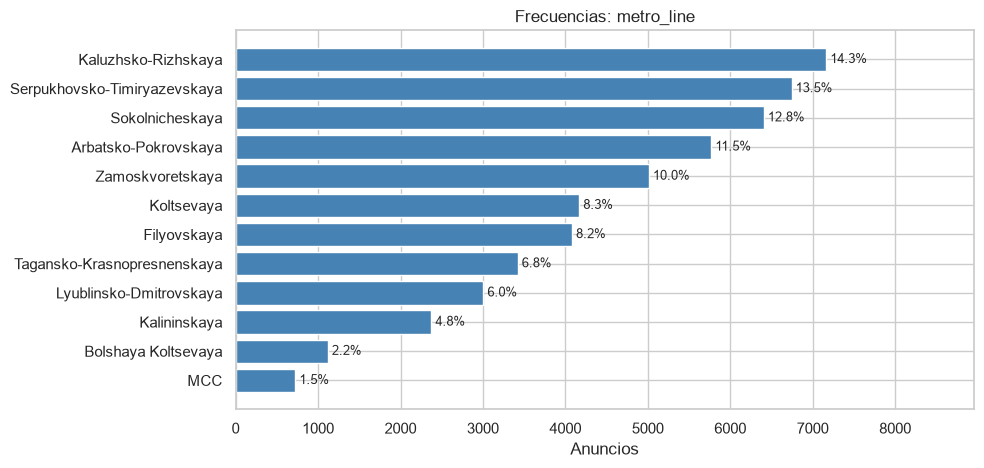

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,transport,39771,79.54
1,walk,10229,20.46


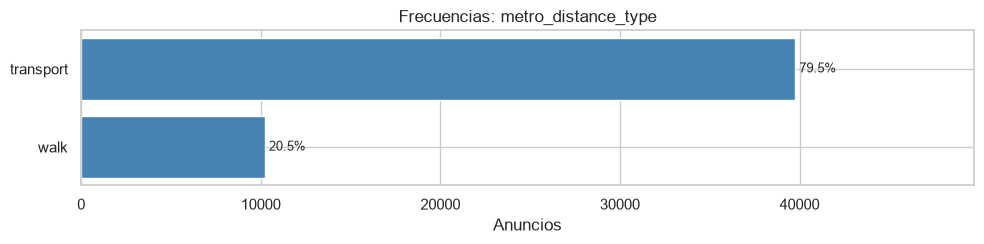

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,agency,32701,65.40
1,owner,17299,34.60


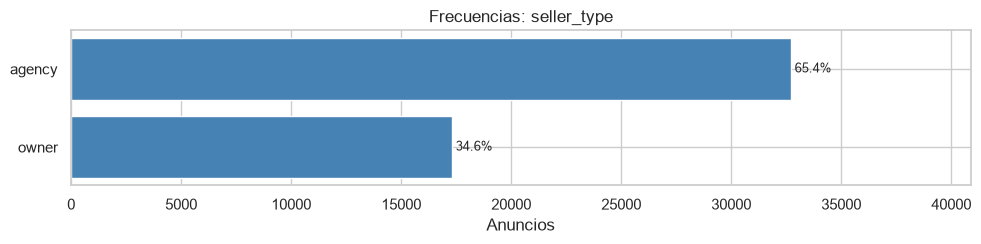

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,True,37490,74.98
1,False,12510,25.02


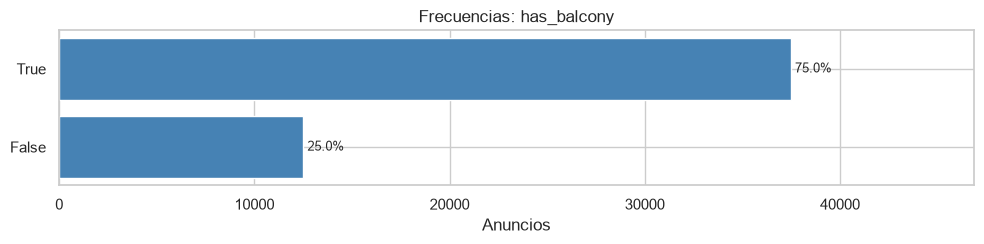

In [14]:
for variable in categoricas_uni + binarias_uni:
    vista = frecuencias_visuales[variable]
    print(variable)
    display(vista.reset_index(drop=True))
    tabla_completa = tablas_frecuencia[variable]
    grafico = tabla_completa.head(10) if len(tabla_completa) > 15 else tabla_completa
    fig, ax = plt.subplots(figsize=(10, max(2.6, .32 * len(grafico) + 1)))
    ax.barh(grafico["categoria"], grafico["frecuencia_absoluta"], color="steelblue")
    ax.invert_yaxis()
    titulo = f"Frecuencias: {variable}"
    if len(tabla_completa) > 15:
        cobertura = grafico["frecuencia_relativa_pct"].sum()
        titulo += f" | Top 10: {cobertura:.1f}% del total"
        print(f"Otras {len(tabla_completa) - 10} categorias: {100 - cobertura:.1f}% del total; incluidas en la tabla.")
    ax.set(title=titulo, xlabel="Anuncios", ylabel="")
    ax.set_xlim(0, grafico["frecuencia_absoluta"].max() * 1.25)
    for posicion, (_, fila) in enumerate(grafico.iterrows()):
        ax.text(fila["frecuencia_absoluta"], posicion,
                f" {fila['frecuencia_relativa_pct']:.1f}%", va="center", fontsize=9)
    fig.tight_layout()
    plt.show()


Publicaciones: 2020-01-01 a 2026-04-29; fechas faltantes: 0
El ultimo mes puede estar incompleto: interpretar su conteo junto al rango observado.


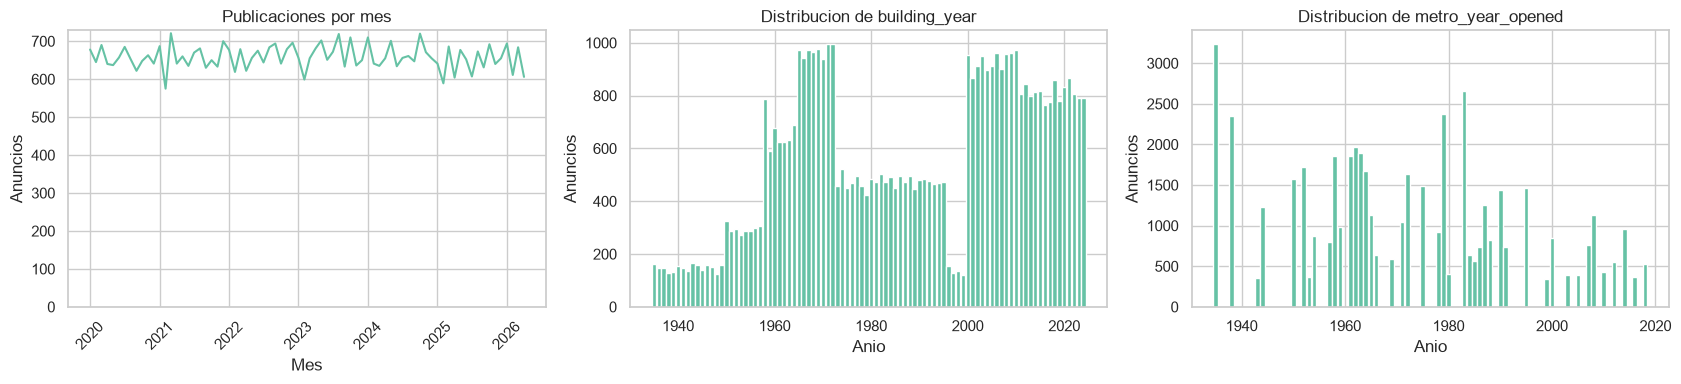

In [15]:
# La fecha y su mes derivado se estudian una sola vez y en orden cronologico.
fechas_uni = datos_univariados["date_posted_dt"]
conteos_mensuales_uni = fechas_uni.dropna().dt.to_period("M").value_counts().sort_index()
if not conteos_mensuales_uni.empty:
    calendario_uni = pd.period_range(conteos_mensuales_uni.index.min(),
                                    conteos_mensuales_uni.index.max(), freq="M")
    conteos_mensuales_uni = conteos_mensuales_uni.reindex(calendario_uni, fill_value=0)
print(f"Publicaciones: {fechas_uni.min().date()} a {fechas_uni.max().date()}; "
      f"fechas faltantes: {fechas_uni.isna().sum():,}")
print("El ultimo mes puede estar incompleto: interpretar su conteo junto al rango observado.")
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(conteos_mensuales_uni.index.to_timestamp(), conteos_mensuales_uni.values)
axes[0].set(title="Publicaciones por mes", xlabel="Mes", ylabel="Anuncios")
axes[0].set_ylim(bottom=0)
axes[0].tick_params(axis="x", rotation=45)
for ax, variable in zip(axes[1:], anios_uni):
    conteos_anios = datos_univariados[variable].value_counts().sort_index()
    ax.bar(conteos_anios.index, conteos_anios.values, width=.9)
    ax.set(title=f"Distribucion de {variable}", xlabel="Anio", ylabel="Anuncios")
fig.tight_layout()
plt.show()

<a id="calidad-univariada"></a>

### 3.5. Valores atípicos y COSAS RARAS

Se usa `|asimetría| > 2` como señal exploratoria de asimetría extrema y `|asimetría| > 1` como señal de asimetría elevada. Los límites de 1,5 × IQR identifican extremos estadísticos, **no errores**; se informan sin recortar las observaciones.
Las reglas físicas y temporales son comprobaciones distintas: por ejemplo, una suma de superficies superior a la superficie total o una construcción posterior a la publicación requieren revisar la fuente. Este diagnóstico solo señala posibles problemas: no corrige, imputa ni elimina observaciones.

In [16]:
q1_uni = datos_univariados[numericas_uni].quantile(.25)
q3_uni = datos_univariados[numericas_uni].quantile(.75)
iqr_uni = q3_uni - q1_uni
limites_inferiores_uni = q1_uni - 1.5 * iqr_uni
limites_superiores_uni = q3_uni + 1.5 * iqr_uni
extremos_uni = (datos_univariados[numericas_uni].lt(limites_inferiores_uni)
                | datos_univariados[numericas_uni].gt(limites_superiores_uni))
diagnostico_distribuciones = pd.DataFrame({
    "asimetria": datos_univariados[numericas_uni].skew(),
    "extremos_IQR": extremos_uni.sum(),
    "extremos_pct_validos": extremos_uni.sum() / datos_univariados[numericas_uni].count() * 100,
    "IQR": iqr_uni,
})
diagnostico_distribuciones["asimetria_extrema"] = diagnostico_distribuciones["asimetria"].abs().gt(2)
atencion_distribuciones = diagnostico_distribuciones.loc[
    diagnostico_distribuciones["asimetria"].abs().gt(1)
    | diagnostico_distribuciones["extremos_IQR"].gt(0)
].sort_values("extremos_pct_validos", ascending=False)
display(atencion_distribuciones)

reglas_calidad = {}
for variable in ["total_area", "living_area", "kitchen_area", "ceiling_height", "price_rub", "price_per_sqm"]:
    reglas_calidad[f"{variable} <= 0"] = datos_univariados[variable].le(0)
for variable in ["rooms", "floor", "total_floors", "metro_distance_min", "to_center_km", "metro_to_center_km"]:
    reglas_calidad[f"{variable} < 0"] = datos_univariados[variable].lt(0)
for variable in ["rooms", "floor", "total_floors", "n_listings_secondary", "n_listings_newbuild", *anios_uni]:
    reglas_calidad[f"{variable} no entero"] = datos_univariados[variable].mod(1).ne(0) & datos_univariados[variable].notna()
reglas_calidad.update({
    "living_area + kitchen_area > total_area": (
        datos_univariados["living_area"] + datos_univariados["kitchen_area"]
        > datos_univariados["total_area"] + 1e-9
    ),
    "floor > total_floors": datos_univariados["floor"].gt(datos_univariados["total_floors"]),
    "building_year > anio de publicacion": datos_univariados["building_year"].gt(fechas_uni.dt.year),
    "metro_year_opened > anio de publicacion": datos_univariados["metro_year_opened"].gt(fechas_uni.dt.year),
    "latitud fuera de [-90, 90]": ~datos_univariados["lat"].between(-90, 90) & datos_univariados["lat"].notna(),
    "longitud fuera de [-180, 180]": ~datos_univariados["lon"].between(-180, 180) & datos_univariados["lon"].notna(),
})
resumen_reglas_calidad = pd.DataFrame([
    {"regla": nombre, "registros": int(mascara.sum()), "porcentaje_total": mascara.mean() * 100}
    for nombre, mascara in reglas_calidad.items()
])
print(f"Reglas revisadas: {len(resumen_reglas_calidad)}; "
      f"sin alertas: {resumen_reglas_calidad['registros'].eq(0).sum()}")
display(resumen_reglas_calidad.loc[resumen_reglas_calidad["registros"].gt(0)])

# Mostrar solo tres ejemplos por tipo de inconsistencia; las mascaras conservan todos.
for regla, columnas in [
    ("living_area + kitchen_area > total_area", ["id", "living_area", "kitchen_area", "total_area"]),
    ("building_year > anio de publicacion", ["id", "building_year", "date_posted_dt"]),
]:
    if reglas_calidad[regla].any():
        print(regla)
        display(datos_univariados.loc[reglas_calidad[regla], columnas].head(3))

faltantes_contexto_uni = datos_univariados.groupby("year_month")[[
    "secondary_mom_change_pct", "newbuild_mom_change_pct"
]].agg(lambda columna: columna.isna().sum())
display(faltantes_contexto_uni.loc[faltantes_contexto_uni.sum(axis=1).gt(0)])
print("Este diagnostico no modifica datos ni elimina observaciones.")

Reglas revisadas: 25; sin alertas: 23
living_area + kitchen_area > total_area
building_year > anio de publicacion
Este diagnostico no modifica datos ni elimina observaciones.


,asimetria,extremos_IQR,extremos_pct_validos,IQR,asimetria_extrema
to_center_km,2.11,4672,9.34,9.03,True
metro_distance_min,2.04,3893,7.79,49.00,True
metro_lat,-0.58,3201,6.40,0.06,False
newbuild_price_per_sqm,1.23,2876,5.75,"136,900.00",False
secondary_price_per_sqm,1.22,2840,5.68,"124,600.00",False
price_per_sqm,1.69,2696,5.39,"116,500.00",False
price_rub,2.00,2459,4.92,"8,905,500.00",False
lon,-1.23,1906,3.81,0.18,False
metro_lon,0.11,1813,3.63,0.11,False
floor,1.01,1703,3.41,7.00,False


,regla,registros,porcentaje_total
19,living_area + kitchen_area > total_area,247,0.49
21,building_year > anio de publicacion,1271,2.54


,id,living_area,kitchen_area,total_area
15157,S015158,17.00,11.30,26.10
37556,S037557,32.30,15.10,46.90
14534,S014535,27.90,12.70,40.40


,id,building_year,date_posted_dt
6769,S006770,2022,2020-01-01
47579,S047580,2023,2020-01-01
43200,S043201,2022,2020-01-02


,secondary_mom_change_pct,newbuild_mom_change_pct
year_month,,
2020-01,678,678


<a id="sintesis-univariada"></a>

### 3.6. Síntesis del análisis univariado

- **Muestra analizada:** 50,000 anuncios y 40 columnas, ordenados por fecha de publicación ascendente. Se conservan los 247 registros (0.49 %) con `living_area + kitchen_area > total_area`; esta regla señala posibles inconsistencias y no elimina datos.
- **Precio:** media de 13.12 M RUB, mediana de 11.09 M RUB y asimetría positiva de 2.00. El 84.61 % cuesta hasta 20 M RUB; el máximo es 93.44 M RUB. Los precios altos pueden influir sobre futuros ajustes OLS.
- **Extremos estadísticos:** 2,459 precios (4.92 %) superan el límite superior de 1,5 × IQR (29.75 M RUB), sin extremos inferiores. Se conservan todos los anuncios.
- **Predictoras y alertas pendientes:** `to_center_km` y `metro_distance_min` tienen asimetrías de 2.11 y 2.04. Hay 1,271 anuncios (2.54 %) con construcción posterior al año de publicación; esta condición solo se señala. `price_per_sqm` deriva del objetivo y la superficie y requiere atención antes de modelar.
- **Faltantes y variabilidad:** se conservan 678 faltantes (1.36 %) en cada una de las columnas `secondary_mom_change_pct` y `newbuild_mom_change_pct`, todos en enero de 2020, al inicio de la serie. Su origen es temporal y no necesariamente aleatorio; los estadísticos de estas columnas usan 49,322 valores observados. No se aplicaron imputaciones. No se detectaron columnas constantes, valores dominantes de al menos el 95 % de los observados, filas duplicadas ni IDs repetidos. El CSV conserva las mismas observaciones, columnas, faltantes y orden cronológico.

<a id="bivariado"></a>

## 4. Análisis bivariado

<a id="fugas-bivariado"></a>

### 4.1. Clasificación y precauciones de las variables

La clasificación conserva la del univariado: **25 numéricas** (17 continuas, 6 discretas y 2 años como atributos temporales), **8 categóricas** y **1 binaria booleana**. Las categorías con dos niveles siguen siendo nominales (`seller_type` y `metro_distance_type`); `has_balcony` representa presencia/ausencia.

| Naturaleza | Variables explicativas |
| --- | --- |
| Continuas (17) | `total_area`, `living_area`, `kitchen_area`, `ceiling_height`, `lat`, `lon`, `to_center_km`, `metro_to_center_km`, `metro_lat`, `metro_lon`, `mortgage_rate_at_listing`, `secondary_price_per_sqm`, `newbuild_price_per_sqm`, `secondary_mom_change_pct`, `newbuild_mom_change_pct`, `cbr_key_rate_pct`, `avg_mortgage_rate_pct` |
| Discretas (6) | `rooms`, `floor`, `total_floors`, `metro_distance_min`, `n_listings_secondary`, `n_listings_newbuild` |
| Años/cohortes (2) | `building_year`, `metro_year_opened` |
| Categóricas (8) | `district`, `okrug`, `building_type`, `renovation`, `metro_station`, `metro_line`, `metro_distance_type`, `seller_type` |
| Binaria (1) | `has_balcony` |


In [17]:
from IPython.display import Markdown
objetivo = "price_rub"
datos_bivariados = df_venta_enriquecido.copy(deep=True)
pd.testing.assert_frame_equal(datos_bivariados, df_venta_enriquecido)
assert datos_bivariados["date_posted_dt"].dropna().is_monotonic_increasing
exclusiones_bivariadas = {
    "id": "Identificador", "complex_id": "Identificador",
    "price_per_sqm": "Derivada del objetivo",
    "_merge_district_prices": "Indicador técnico", "_merge_metro_stations": "Indicador técnico",
    "date_posted": "Fecha de publicación: apartado 6",
    "date_posted_dt": "Fecha de publicación: apartado 6", "year_month": "Mes de publicación: apartado 6",
}
continuas_bivariadas = [c for c in continuas_uni if c != "price_per_sqm"]
discretas_bivariadas = discretas_uni.copy()
anios_bivariados = anios_uni.copy()
numericas = continuas_bivariadas + discretas_bivariadas + anios_bivariados
categoricas = categoricas_uni.copy()
binarias = binarias_uni.copy()
assert (len(continuas_bivariadas), len(discretas_bivariadas), len(anios_bivariados), len(categoricas), len(binarias)) == (17, 6, 2, 8, 1)
numericas_detectadas = {c for c in datos_bivariados.select_dtypes(include="number")
                       if c != objetivo and c not in exclusiones_bivariadas}
assert set(numericas) == numericas_detectadas
assert set(datos_bivariados.select_dtypes(include="bool")) == set(binarias)
assert not ({objetivo, "price_per_sqm"} & set(numericas + categoricas + binarias))
precio_bivariado = datos_bivariados[objetivo].where(np.isfinite(datos_bivariados[objetivo]))
registros_graficos_bivariados = []
resumen_grupos = {}
resumen_binarias = {}
interpretaciones_bivariadas = []

def pares_bivariados(variable):
    pares = datos_bivariados[[variable, objetivo]]
    return pares.loc[np.isfinite(pares).all(axis=1)].copy()

def resumen_distribucion_grupos(vista):
    tabla = vista.groupby("grupo", observed=True, sort=False)[objetivo].agg(
        n="count", precio_medio="mean", precio_mediano="median", desv_estandar="std",
        Q1=lambda s: s.quantile(.25), Q3=lambda s: s.quantile(.75), minimo="min", maximo="max")
    return tabla

def interpretar_numerica(variable, fila):
    r=fila["Pearson_r"]; rho=fila["Spearman_rho"]
    if pd.isna(r): return f"{variable}: asociación lineal no estimable por cantidad o variación insuficientes."
    fuerza="fuerte" if abs(r)>=.7 else "moderada" if abs(r)>=.3 else "débil"
    direccion="positiva" if r>0 else "negativa" if r<0 else "nula"
    brecha="La diferencia entre Pearson y Spearman sugiere revisar curvatura o influencia de la dispersión" if abs(rho-r)>=.1 else "La proximidad de Pearson y Spearman no demuestra linealidad"
    return (f"`{variable}`: asociación {direccion} {fuerza} (Pearson={r:.3f}, Spearman={rho:.3f}, R²={fila['R2']:.3f}; n={int(fila['n']):,}). "
            f"{brecha}.")

<a id="numericas-bivariado"></a>

### 4.2. Características numéricas y precio

,variable,n,pares_omitidos,Pearson_r,Spearman_rho,R2,pendiente_RUB_por_unidad,intercepto_RUB
0,total_area,50000,0,0.40,0.42,0.16,"196,948.72","-83,212.32"
1,living_area,50000,0,0.38,0.41,0.15,"293,992.19","809,316.63"
2,kitchen_area,50000,0,0.19,0.19,0.04,"577,571.03","6,628,237.42"
3,ceiling_height,50000,0,0.07,0.06,0.00,"2,724,005.51","5,529,018.74"
4,lat,50000,0,0.27,0.26,0.07,"15,806,705.24","-867,511,136.66"
5,lon,50000,0,0.22,0.22,0.05,"10,639,119.94","-386,308,652.99"
6,to_center_km,50000,0,-0.53,-0.68,0.28,"-358,576.80","18,977,072.88"
7,metro_to_center_km,50000,0,-0.11,-0.03,0.01,"-186,528.92","14,496,389.64"
8,metro_lat,50000,0,0.04,0.05,0.00,"5,899,609.87","-315,745,948.30"
9,metro_lon,50000,0,-0.05,-0.05,0.00,"-4,818,870.60","194,298,929.29"


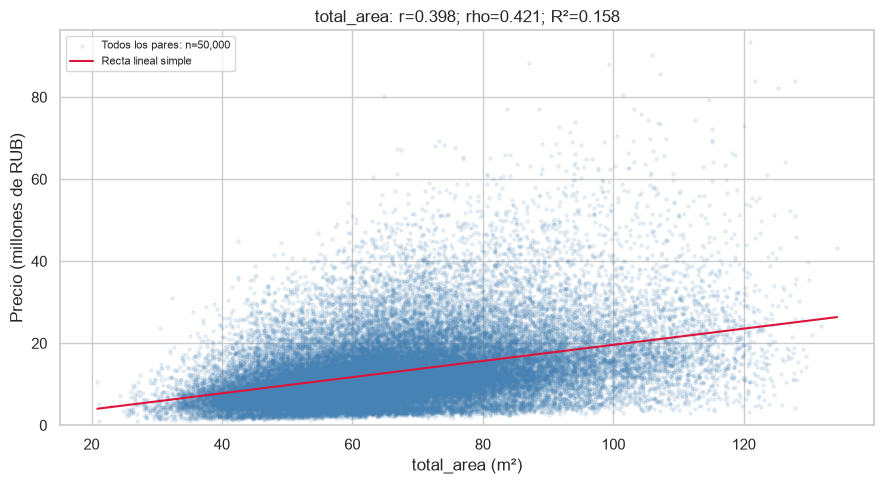

`total_area`: asociación positiva moderada (Pearson=0.398, Spearman=0.421, R²=0.158; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

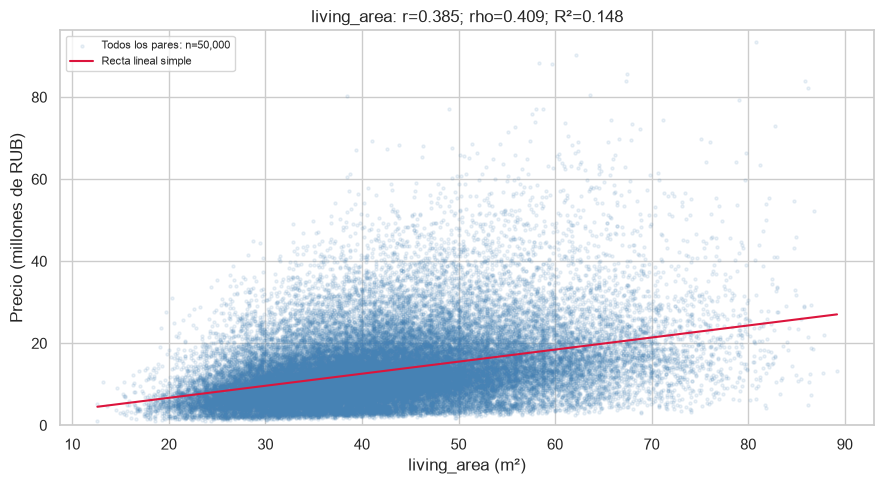

`living_area`: asociación positiva moderada (Pearson=0.385, Spearman=0.409, R²=0.148; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

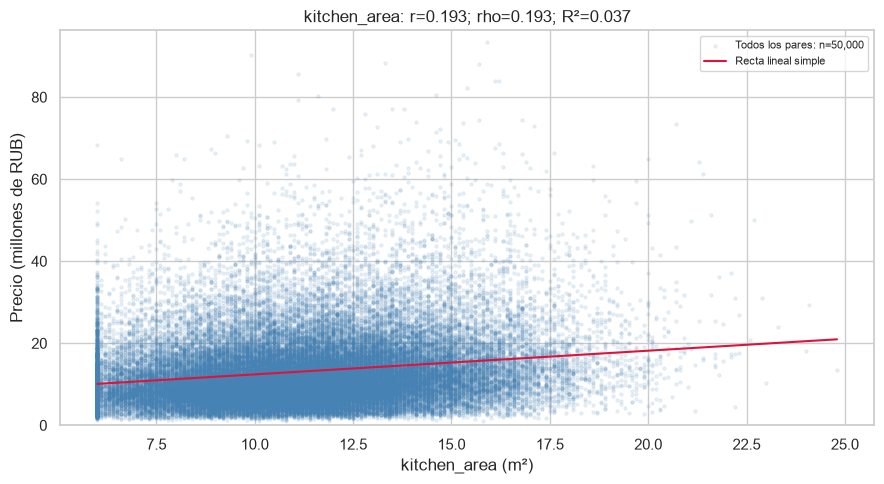

`kitchen_area`: asociación positiva débil (Pearson=0.193, Spearman=0.193, R²=0.037; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

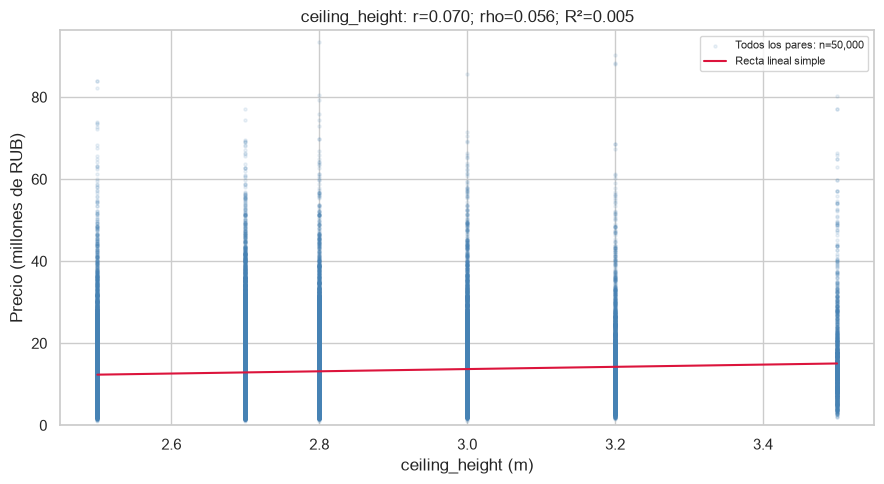

`ceiling_height`: asociación positiva débil (Pearson=0.070, Spearman=0.056, R²=0.005; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

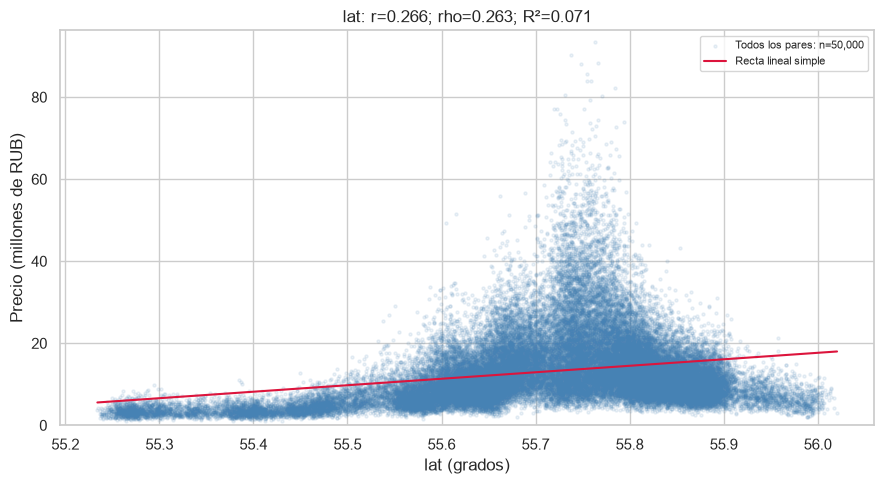

`lat`: asociación positiva débil (Pearson=0.266, Spearman=0.263, R²=0.071; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

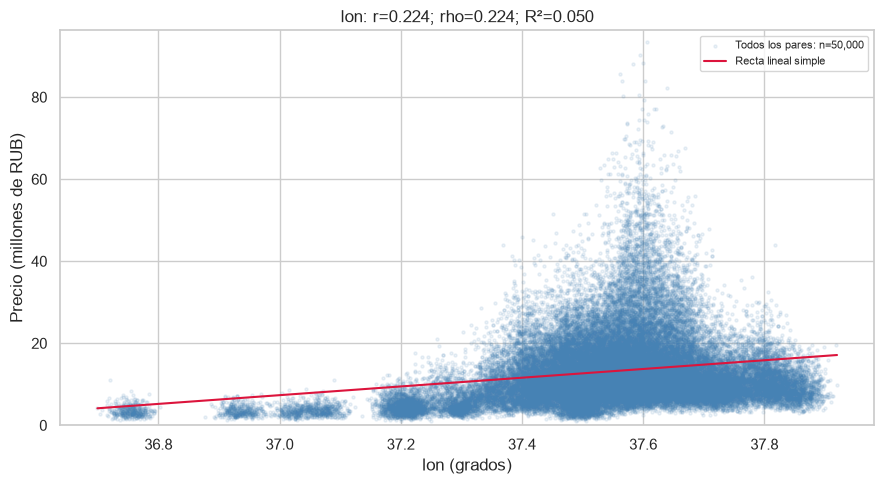

`lon`: asociación positiva débil (Pearson=0.224, Spearman=0.224, R²=0.050; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

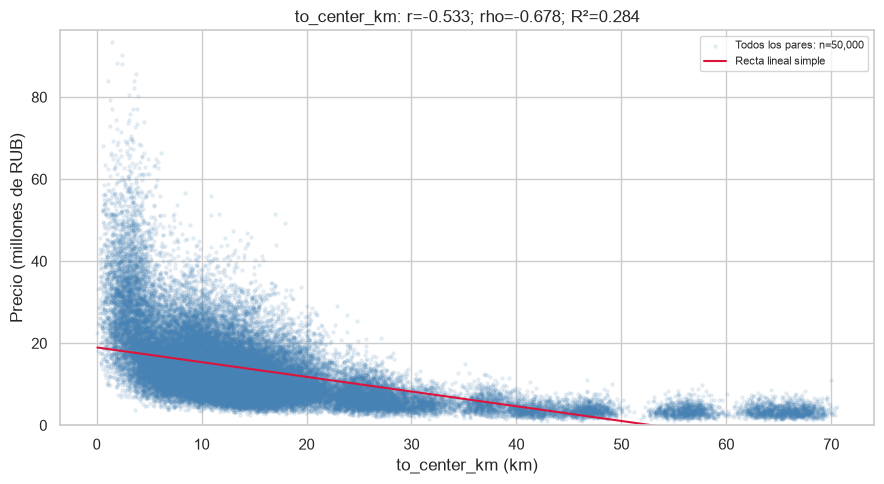

`to_center_km`: asociación negativa moderada (Pearson=-0.533, Spearman=-0.678, R²=0.284; n=50,000). La diferencia entre Pearson y Spearman sugiere revisar curvatura o influencia de la dispersión.

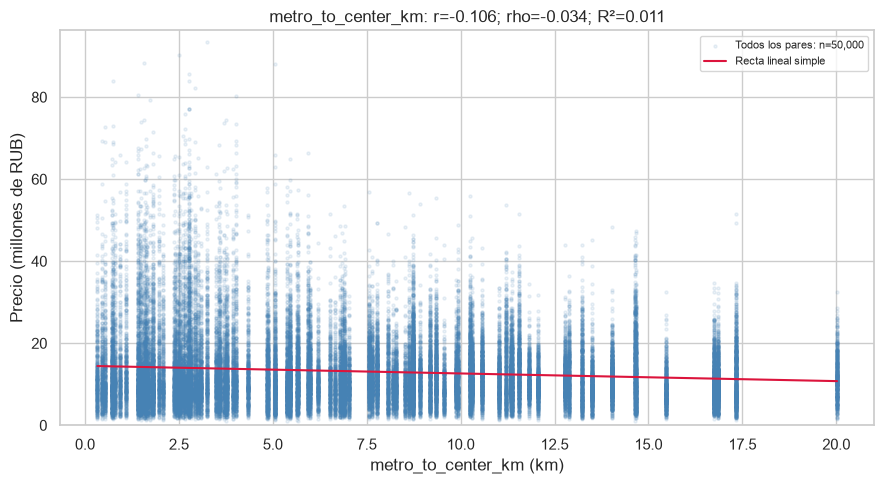

`metro_to_center_km`: asociación negativa débil (Pearson=-0.106, Spearman=-0.034, R²=0.011; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

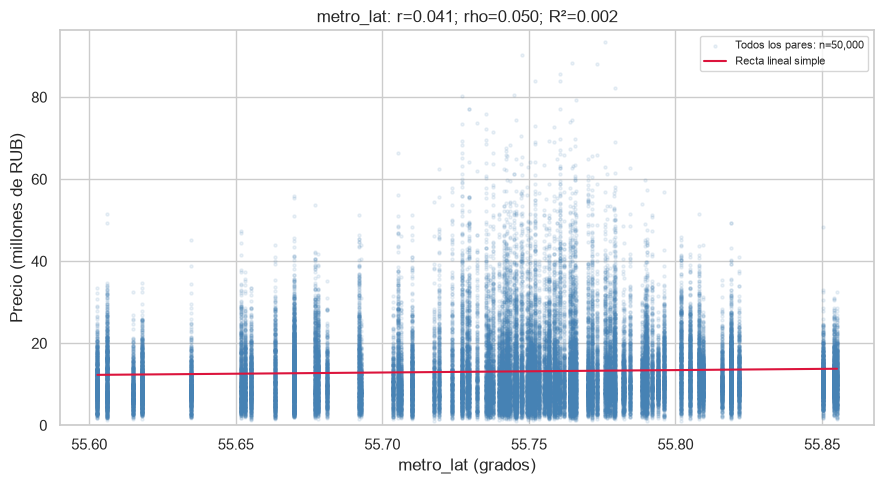

`metro_lat`: asociación positiva débil (Pearson=0.041, Spearman=0.050, R²=0.002; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

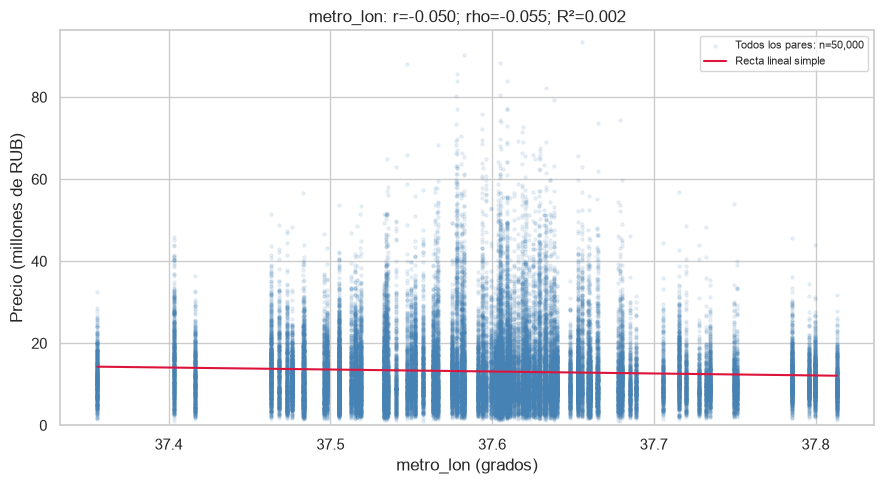

`metro_lon`: asociación negativa débil (Pearson=-0.050, Spearman=-0.055, R²=0.002; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

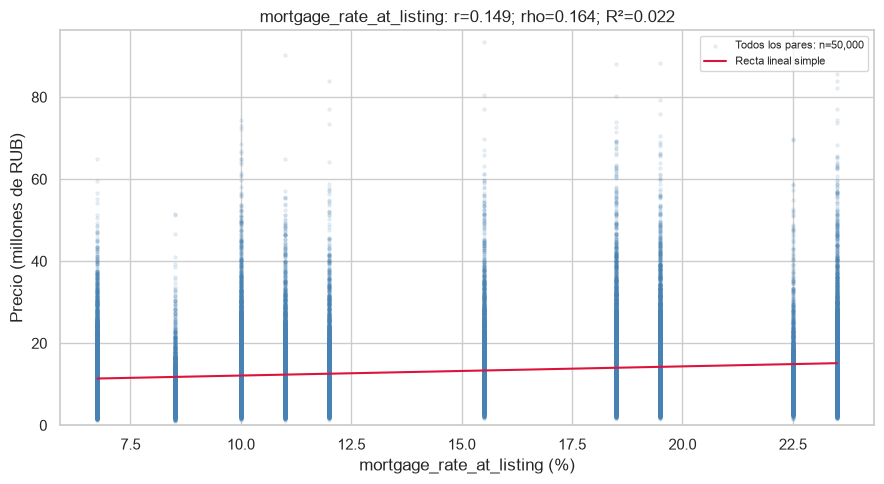

`mortgage_rate_at_listing`: asociación positiva débil (Pearson=0.149, Spearman=0.164, R²=0.022; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

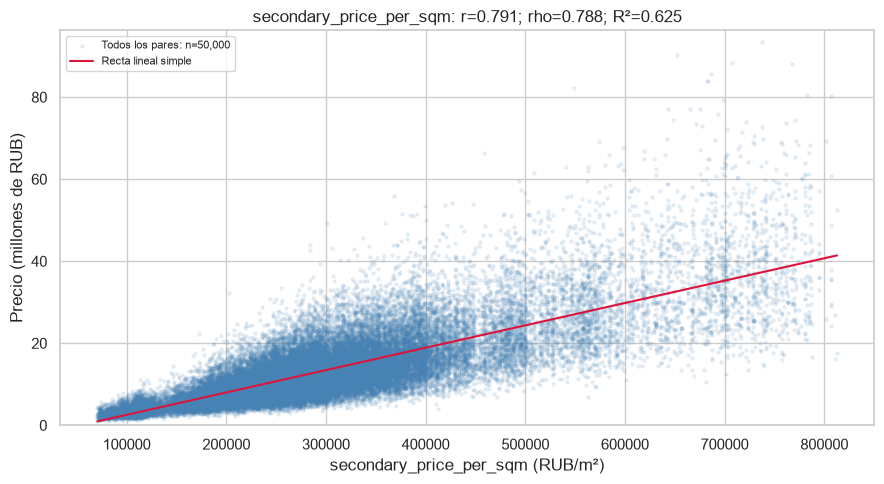

`secondary_price_per_sqm`: asociación positiva fuerte (Pearson=0.791, Spearman=0.788, R²=0.625; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

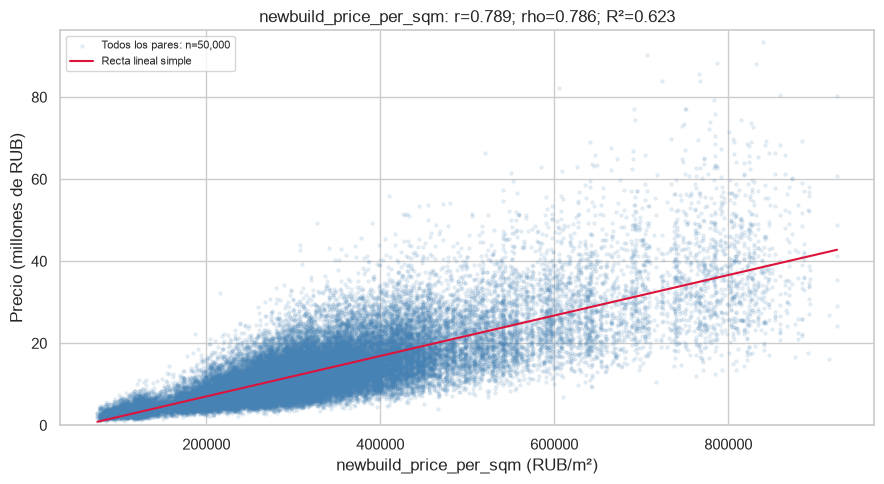

`newbuild_price_per_sqm`: asociación positiva fuerte (Pearson=0.789, Spearman=0.786, R²=0.623; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

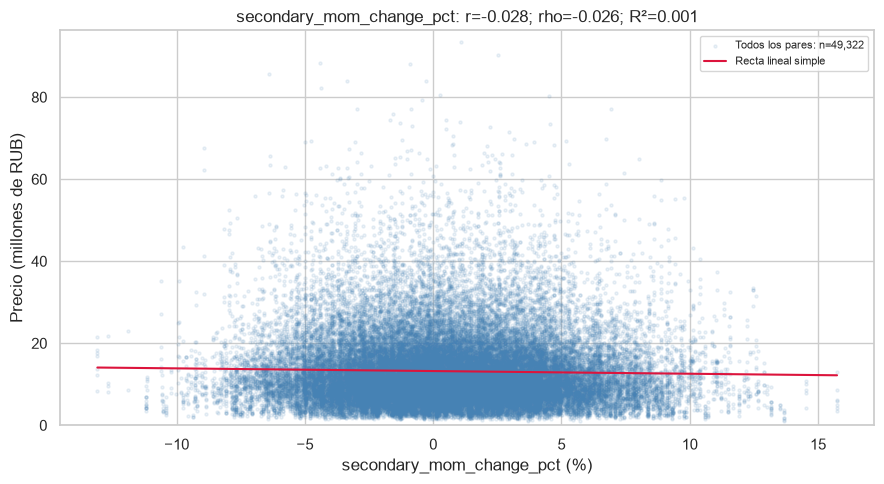

`secondary_mom_change_pct`: asociación negativa débil (Pearson=-0.028, Spearman=-0.026, R²=0.001; n=49,322). La proximidad de Pearson y Spearman no demuestra linealidad.

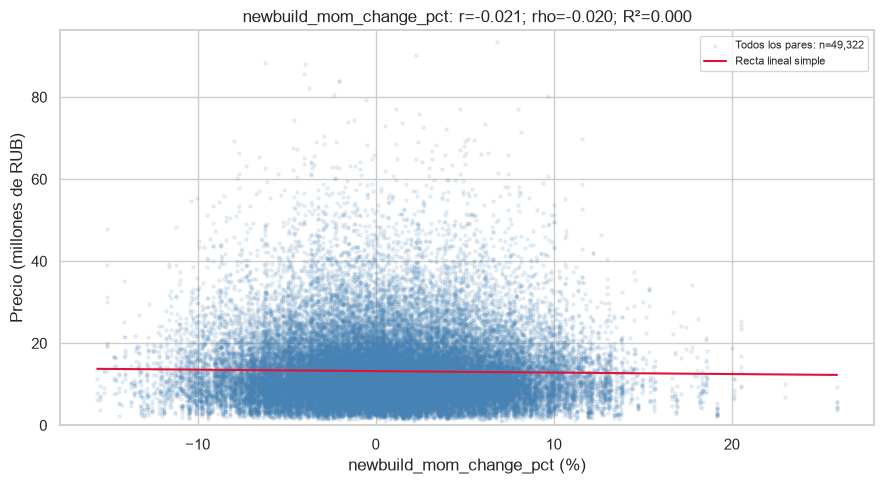

`newbuild_mom_change_pct`: asociación negativa débil (Pearson=-0.021, Spearman=-0.020, R²=0.000; n=49,322). La proximidad de Pearson y Spearman no demuestra linealidad.

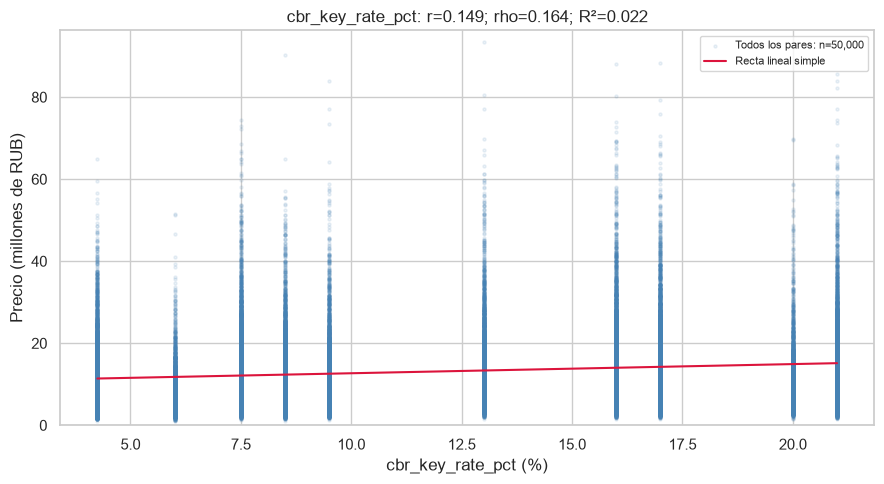

`cbr_key_rate_pct`: asociación positiva débil (Pearson=0.149, Spearman=0.164, R²=0.022; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

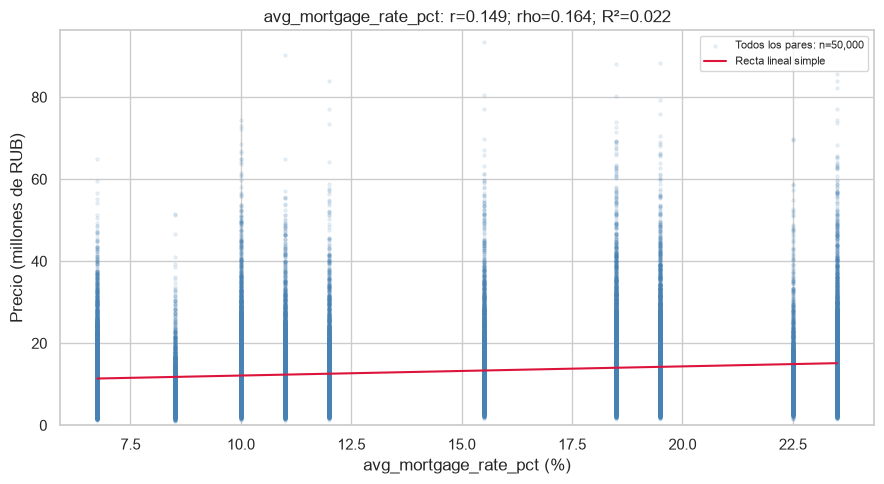

`avg_mortgage_rate_pct`: asociación positiva débil (Pearson=0.149, Spearman=0.164, R²=0.022; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

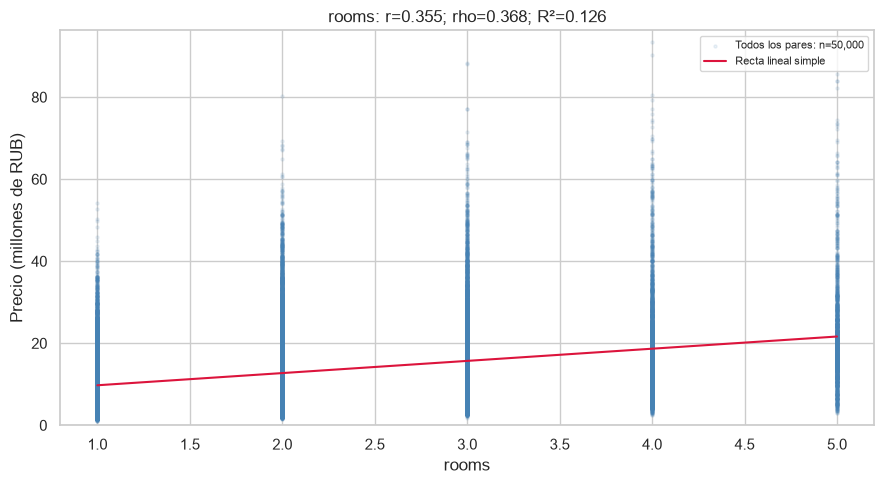

`rooms`: asociación positiva moderada (Pearson=0.355, Spearman=0.368, R²=0.126; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

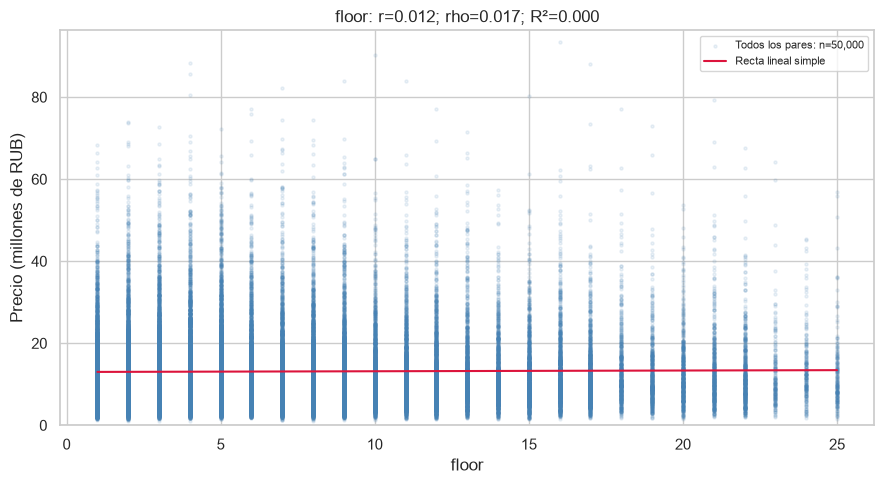

`floor`: asociación positiva débil (Pearson=0.012, Spearman=0.017, R²=0.000; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

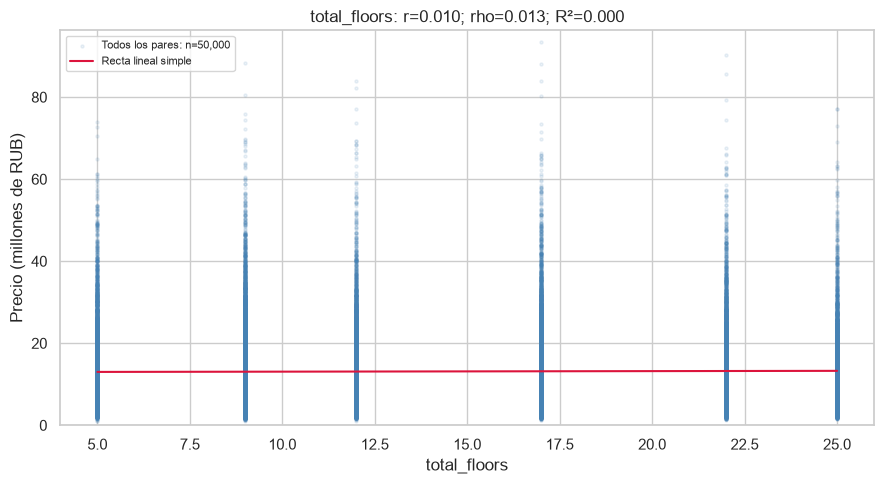

`total_floors`: asociación positiva débil (Pearson=0.010, Spearman=0.013, R²=0.000; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

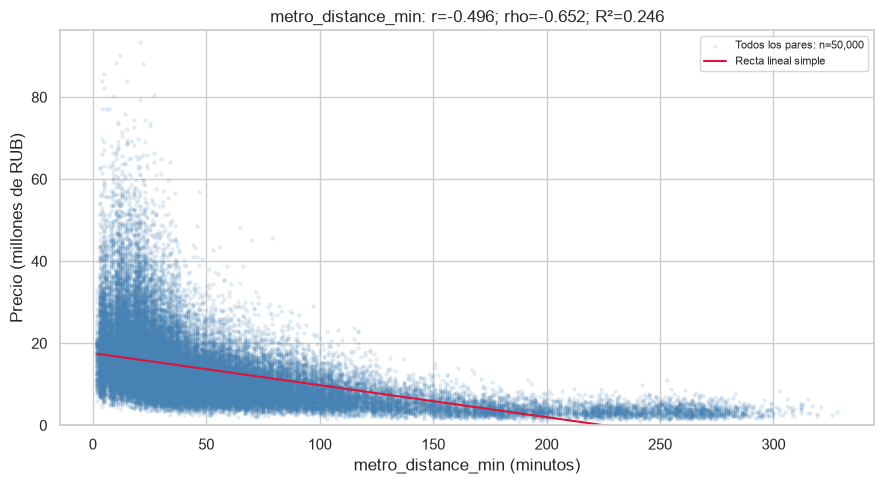

`metro_distance_min`: asociación negativa moderada (Pearson=-0.496, Spearman=-0.652, R²=0.246; n=50,000). La diferencia entre Pearson y Spearman sugiere revisar curvatura o influencia de la dispersión.

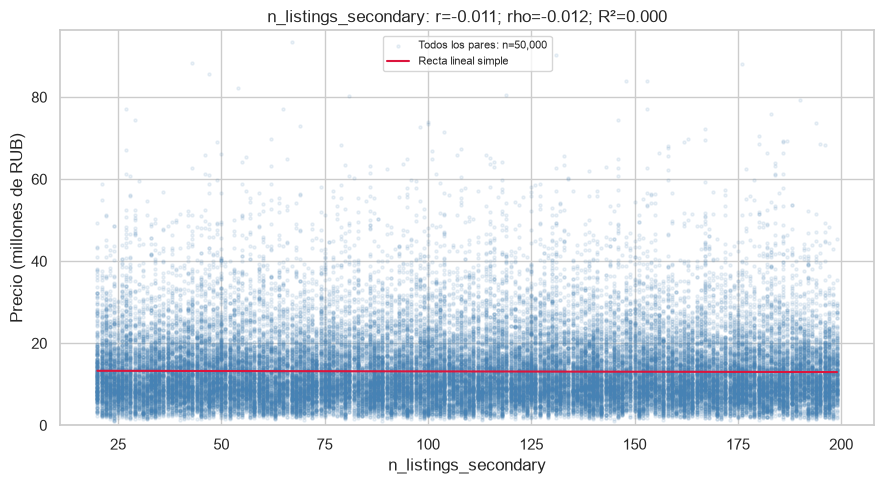

`n_listings_secondary`: asociación negativa débil (Pearson=-0.011, Spearman=-0.012, R²=0.000; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

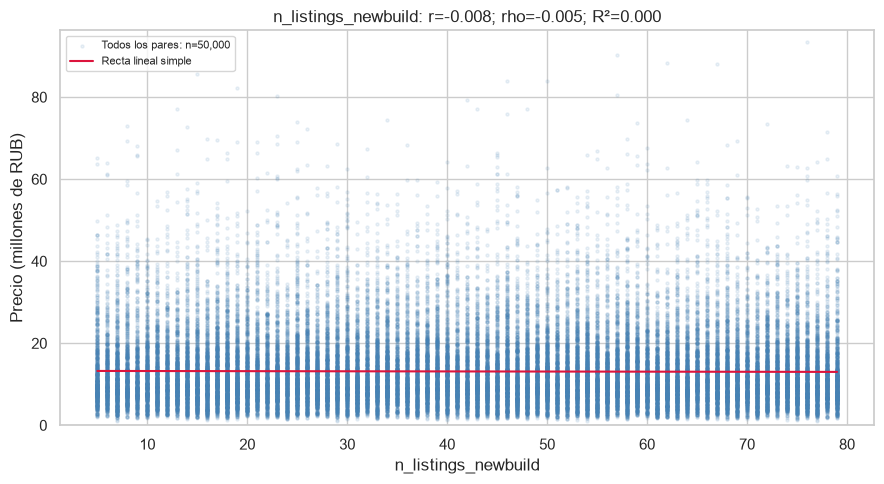

`n_listings_newbuild`: asociación negativa débil (Pearson=-0.008, Spearman=-0.005, R²=0.000; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

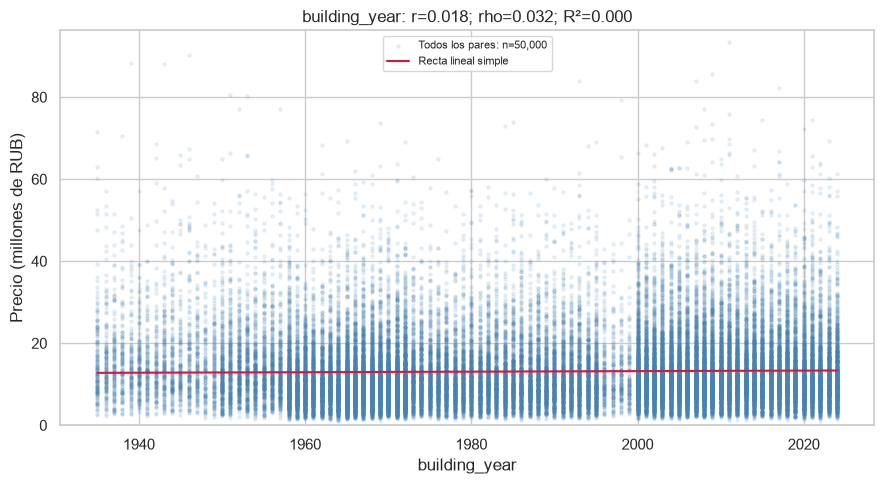

`building_year`: asociación positiva débil (Pearson=0.018, Spearman=0.032, R²=0.000; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

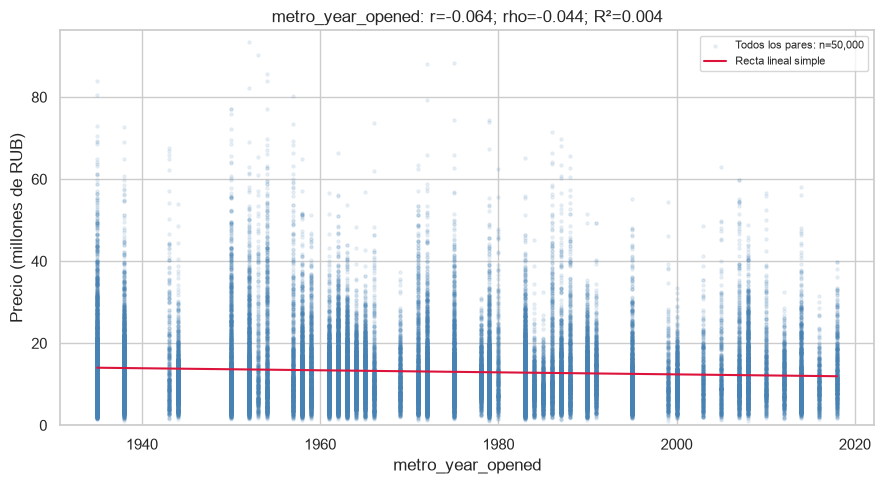

`metro_year_opened`: asociación negativa débil (Pearson=-0.064, Spearman=-0.044, R²=0.004; n=50,000). La proximidad de Pearson y Spearman no demuestra linealidad.

In [18]:
resultados_regresiones = []
for variable in numericas:
    pares=pares_bivariados(variable)
    fila={"variable":variable,"n":len(pares),"pares_omitidos":len(datos_bivariados)-len(pares),
          "Pearson_r":np.nan,"Spearman_rho":np.nan,"R2":np.nan,
          "pendiente_RUB_por_unidad":np.nan,"intercepto_RUB":np.nan}
    if len(pares)>=3 and pares[variable].nunique()>1 and pares[objetivo].nunique()>1:
        ajuste=linregress(pares[variable],pares[objetivo])
        fila.update(Pearson_r=ajuste.rvalue,Spearman_rho=pares[variable].corr(pares[objetivo],method="spearman"),
                    R2=ajuste.rvalue**2,pendiente_RUB_por_unidad=ajuste.slope,intercepto_RUB=ajuste.intercept)
    resultados_regresiones.append(fila)
resultados_regresiones=pd.DataFrame(resultados_regresiones)
display(resultados_regresiones)

for variable in numericas:
    pares=pares_bivariados(variable)
    fila=resultados_regresiones.set_index("variable").loc[variable]
    if pares.empty:
        display(Markdown(f"`{variable}`: sin pares válidos para representar.")); continue
    unidad=CONFIG["units"].get(variable, "")
    if variable in ["secondary_price_per_sqm","newbuild_price_per_sqm"]:unidad="RUB/m²"
    if variable.endswith("_pct"):unidad="%"
    if variable in ["metro_lat","metro_lon","lat","lon"]:unidad="grados"
    if variable=="metro_to_center_km":unidad="km"
    fig,ax=plt.subplots(figsize=(9,5))
    ax.scatter(pares[variable],pares[objetivo]/1e6,s=5,alpha=.1,color="steelblue",rasterized=True,
                    label=f"Todos los pares: n={len(pares):,}")
    if pd.notna(fila["Pearson_r"]):
        x=np.array([pares[variable].min(),pares[variable].max()])
        ax.plot(x,(fila["intercepto_RUB"]+fila["pendiente_RUB_por_unidad"]*x)/1e6,
                     color="crimson",label="Recta lineal simple")
    ax.set(title=f"{variable}: r={fila['Pearson_r']:.3f}; rho={fila['Spearman_rho']:.3f}; R²={fila['R2']:.3f}",
                xlabel=f"{variable} ({unidad})" if unidad else variable,ylabel="Precio (millones de RUB)",
                ylim=(0,precio_bivariado.max()/1e6*1.03))
    ax.legend(fontsize=8)
    fig.tight_layout();plt.show()
    texto=interpretar_numerica(variable,fila)
    interpretaciones_bivariadas.append({"variable":variable,"interpretacion":texto})
    display(Markdown(texto))
    registros_graficos_bivariados.append({"variable":variable,"tipo":"dispersión","n":len(pares)})

<a id="categoricas-bivariado"></a>

### 4.3. Características categóricas y precio

In [19]:
def vista_categorica(variable):
    return pd.DataFrame({"grupo":datos_bivariados[variable].astype("object").where(
        datos_bivariados[variable].notna(),"Sin dato").astype(str),objetivo:precio_bivariado})

def analizar_categorica(variable, destino):
    vista=vista_categorica(variable)
    tabla=resumen_distribucion_grupos(vista)
    tabla["anuncios"]=vista.groupby("grupo",observed=True).size()
    tabla["precios_no_validos"]=tabla["anuncios"]-tabla["n"]
    tabla=tabla.sort_values("precio_mediano",kind="stable",na_position="last")
    destino[variable]=tabla
    assert tabla["anuncios"].sum()==len(datos_bivariados)
    assert tabla["n"].sum()==precio_bivariado.count()
    display(Markdown(f"**{variable}: {len(tabla)} categorías, todas representadas**"))
    with pd.option_context("display.max_rows",None):display(tabla)
    comparables=tabla.loc[tabla["n"].gt(0)]
    if not comparables.empty:
        baja=comparables.iloc[0];alta=comparables.iloc[-1]
        dispersion=comparables["desv_estandar"].dropna()
        texto=(f"`{variable}`: menor mediana en **{comparables.index[0]}** ({baja.precio_mediano/1e6:.2f} M RUB; n={int(baja.n):,}) "
               f"y mayor en **{comparables.index[-1]}** ({alta.precio_mediano/1e6:.2f} M RUB; n={int(alta.n):,}). "
               f"La desviación estándar va de {dispersion.min()/1e6:.2f} a {dispersion.max()/1e6:.2f} M RUB; "
               f"la mayor dispersión corresponde a {dispersion.idxmax() if not dispersion.empty else 'ningún grupo estimable'}. "
               "Las diferencias de nivel y dispersión describen grupos sin ajustar por superficie, localización u otras características; "
               "los tamaños pequeños limitan la estabilidad de sus resúmenes.")
        display(Markdown(texto));interpretaciones_bivariadas.append({"variable":variable,"interpretacion":texto})

for variable in categoricas:analizar_categorica(variable,resumen_grupos)

**district: 129 categorías, todas representadas**

,n,precio_medio,precio_mediano,desv_estandar,Q1,Q3,minimo,maximo,anuncios,precios_no_validos
grupo,,,,,,,,,,
Kievsky,400,"3,552,115.00","3,324,500.00","1,255,016.35","2,654,000.00","4,222,000.00",1317000,11106000,400,0
Klyonovskoye,413,"3,514,225.18","3,333,000.00","1,225,504.45","2,682,000.00","4,195,000.00",1073000,8376000,413,0
Novofyodorovskoye,391,"3,611,759.59","3,392,000.00","1,240,487.06","2,748,000.00","4,295,000.00",1319000,7524000,391,0
Rogovskoye,351,"3,592,227.92","3,420,000.00","1,273,071.49","2,672,500.00","4,327,000.00",1388000,8657000,351,0
Shchapovskoye,386,"3,765,401.55","3,462,000.00","1,351,842.71","2,784,250.00","4,635,750.00",1027000,10564000,386,0
Mikhaylovo-Yartsevskoye,427,"3,718,857.14","3,472,000.00","1,302,767.09","2,833,000.00","4,424,000.00",1019000,10098000,427,0
Voronovskoye,422,"3,730,954.98","3,513,500.00","1,341,916.47","2,757,000.00","4,470,500.00",1335000,9824000,422,0
Pervomayskoye,362,"3,905,657.46","3,685,000.00","1,331,854.99","2,943,000.00","4,637,750.00",1704000,10956000,362,0
Krasnopakhorskoye,407,"4,082,540.54","3,873,000.00","1,359,982.90","3,057,000.00","4,784,000.00",1637000,9151000,407,0


`district`: menor mediana en **Kievsky** (3.32 M RUB; n=400) y mayor en **Khamovniki** (34.97 M RUB; n=391). La desviación estándar va de 1.23 a 13.40 M RUB; la mayor dispersión corresponde a Khamovniki. Las diferencias de nivel y dispersión describen grupos sin ajustar por superficie, localización u otras características; los tamaños pequeños limitan la estabilidad de sus resúmenes.

**okrug: 11 categorías, todas representadas**

,n,precio_medio,precio_mediano,desv_estandar,Q1,Q3,minimo,maximo,anuncios,precios_no_validos
grupo,,,,,,,,,,
TAO,3950,"3,847,054.43","3,609,000.00","1,396,767.51","2,832,000.00","4,637,000.00",1019000,11106000,3950,0
ZelAO,361,"5,995,886.43","5,710,000.00","2,150,805.27","4,471,000.00","7,354,000.00",1939000,15004000,361,0
NAO,4167,"6,764,978.16","6,237,000.00","2,668,632.18","4,858,500.00","8,141,000.00",1516000,24530000,4167,0
YuAO,6218,"11,229,262.14","10,190,500.00","4,843,973.54","7,747,000.00","13,661,750.00",2796000,51166000,6218,0
SVAO,6662,"11,221,738.67","10,318,500.00","4,574,636.51","7,975,250.00","13,468,750.00",2491000,41569000,6662,0
VAO,6091,"11,679,616.65","10,745,000.00","4,828,903.70","8,196,000.00","14,123,500.00",2917000,44035000,6091,0
SAO,5856,"13,056,900.96","11,789,500.00","6,037,275.69","8,636,500.00","16,225,250.00",2823000,53339000,5856,0
SZAO,3421,"14,942,219.23","13,857,000.00","6,192,758.26","10,543,000.00","17,996,000.00",3348000,51385000,3421,0
ZAO,4617,"16,087,483.21","14,495,000.00","7,580,154.90","10,538,000.00","19,983,000.00",2991000,63435000,4617,0


...

,n,precio_medio,precio_mediano,desv_estandar,Q1,Q3,minimo,maximo,anuncios,precios_no_validos
grupo,,,,,,,,,,
transport,39771,"11,477,058.64","9,897,000.00","7,191,804.62","6,776,000.00","14,226,000.00",1019000,93437000,39771,0
walk,10229,"19,521,651.87","17,029,000.00","10,292,742.90","12,413,000.00","23,810,000.00",3627000,90327000,10229,0


`metro_distance_type`: menor mediana en **transport** (9.90 M RUB; n=39,771) y mayor en **walk** (17.03 M RUB; n=10,229). La desviación estándar va de 7.19 a 10.29 M RUB; la mayor dispersión corresponde a walk. Las diferencias de nivel y dispersión describen grupos sin ajustar por superficie, localización u otras características; los tamaños pequeños limitan la estabilidad de sus resúmenes.

**seller_type: 2 categorías, todas representadas**

,n,precio_medio,precio_mediano,desv_estandar,Q1,Q3,minimo,maximo,anuncios,precios_no_validos
grupo,,,,,,,,,,
owner,17299,"13,126,536.27","11,028,000.00","8,642,005.69","7,490,000.00","16,271,000.00",1122000,83857000,17299,0
agency,32701,"13,120,856.40","11,112,000.00","8,522,690.04","7,478,000.00","16,435,000.00",1019000,93437000,32701,0


`seller_type`: menor mediana en **owner** (11.03 M RUB; n=17,299) y mayor en **agency** (11.11 M RUB; n=32,701). La desviación estándar va de 8.52 a 8.64 M RUB; la mayor dispersión corresponde a owner. Las diferencias de nivel y dispersión describen grupos sin ajustar por superficie, localización u otras características; los tamaños pequeños limitan la estabilidad de sus resúmenes.

<a id="jerarquia-okrug-district"></a>

#### 4.3.1. Relación jerárquica entre `okrug` y `district`

Total de valores únicos observados: 11 okrugs y 129 distritos.
Faltantes: okrug=0; district=0.
No se detectaron inconsistencias: cada distrito pertenece a un único okrug dentro del dataset.


,distritos_unicos,propiedades_registradas
okrug,,
SVAO,17,6662
VAO,16,6091
YuAO,16,6218
SAO,15,5856
YuZAO,12,4758
ZAO,12,4617
NAO,11,4167
CAO,10,3899
TAO,10,3950


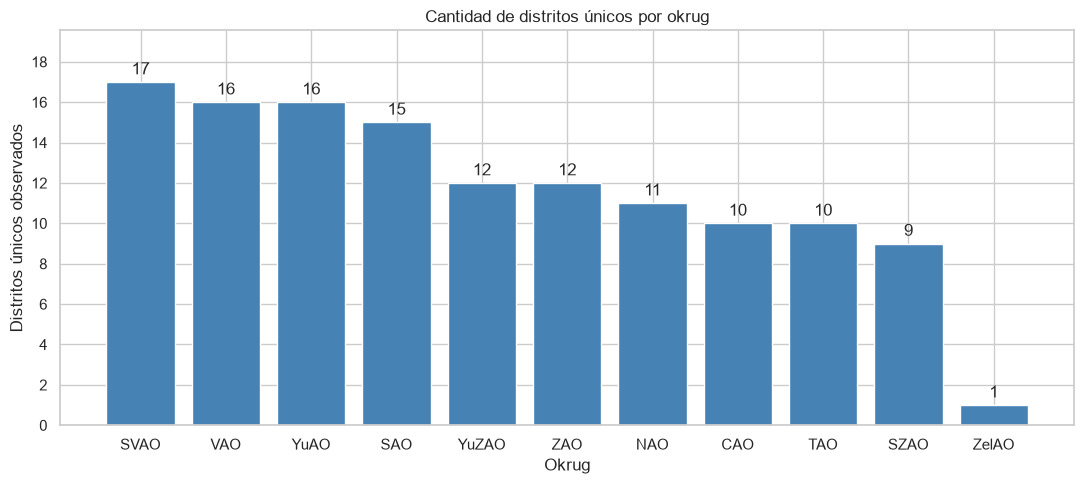

**Conclusión:** los 129 distritos observados se distribuyen entre 11 okrugs. Cada distrito está asociado a un solo okrug, mientras que un okrug puede agrupar varios distritos: la relación observada es de uno a muchos de `okrug` a `district`. `district` aporta un nivel geográfico más detallado dentro de `okrug`. Esta conclusión corresponde a las asociaciones presentes en el dataset.

In [20]:
from IPython.display import Markdown

n_okrugs_jerarquia = df_venta_enriquecido["okrug"].nunique(dropna=True)
n_distritos_jerarquia = df_venta_enriquecido["district"].nunique(dropna=True)
faltantes_jerarquia = df_venta_enriquecido[["okrug", "district"]].isna().sum()
print(f"Total de valores únicos observados: {n_okrugs_jerarquia} okrugs y {n_distritos_jerarquia} distritos.")
print(f"Faltantes: okrug={faltantes_jerarquia['okrug']:,}; district={faltantes_jerarquia['district']:,}.")

resumen_okrug_district = df_venta_enriquecido.groupby("okrug", dropna=False, observed=True).agg(
    distritos_unicos=("district", "nunique"),
    propiedades_registradas=("district", "size"),
).sort_values("distritos_unicos", ascending=False, kind="stable")
display(resumen_okrug_district)
assert resumen_okrug_district["propiedades_registradas"].sum() == len(df_venta_enriquecido)

fig, ax = plt.subplots(figsize=(11, 5))
etiquetas_okrug_jerarquia = [str(x) if pd.notna(x) else "(Okrug faltante)" for x in resumen_okrug_district.index]
barras_okrug_jerarquia = ax.bar(etiquetas_okrug_jerarquia, resumen_okrug_district["distritos_unicos"], color="steelblue")
ax.bar_label(barras_okrug_jerarquia, padding=3, fmt="%d")
ax.set(title="Cantidad de distritos únicos por okrug", xlabel="Okrug", ylabel="Distritos únicos observados")
ax.set_ylim(0, max(1, resumen_okrug_district["distritos_unicos"].max()) * 1.15)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

# La deduplicación se realiza únicamente en esta tabla de combinaciones solicitada.
combinaciones_okrug_district = df_venta_enriquecido[["district", "okrug"]].drop_duplicates()
okrugs_por_distrito = combinaciones_okrug_district.groupby("district", dropna=True, observed=True)["okrug"].nunique(dropna=True)
distritos_con_multiples_okrugs = okrugs_por_distrito.loc[okrugs_por_distrito.gt(1)].index
registros_distritos_multiples = df_venta_enriquecido.loc[
    df_venta_enriquecido["district"].isin(distritos_con_multiples_okrugs), ["district", "okrug"]
]
detalle_distritos_multiples = registros_distritos_multiples.groupby(
    ["district", "okrug"], dropna=False, observed=True
).size().rename("registros").reset_index()
resumen_distritos_multiples = registros_distritos_multiples.groupby("district", observed=True).agg(
    okrugs=("okrug", lambda s: ", ".join(sorted(str(x) for x in s.dropna().unique()))),
    registros_totales=("okrug", "size"),
)

if len(distritos_con_multiples_okrugs):
    print(f"Se detectaron {len(distritos_con_multiples_okrugs)} distritos asociados a múltiples okrugs.")
    display(resumen_distritos_multiples)
    print("Cantidad de registros de cada asociación district–okrug:")
    display(detalle_distritos_multiples)
    display(Markdown(
        "**Conclusión:** la relación no es estrictamente jerárquica para todos los nombres de distrito observados: "
        "las asociaciones múltiples deben revisarse en la fuente antes de asumir una pertenencia única. "
        "La tabla conserva las categorías originales; no se corrigen ni eliminan observaciones."
    ))
else:
    if faltantes_jerarquia.sum() == 0:
        print("No se detectaron inconsistencias: cada distrito pertenece a un único okrug dentro del dataset.")
        display(Markdown(
            f"**Conclusión:** los {n_distritos_jerarquia} distritos observados se distribuyen entre "
            f"{n_okrugs_jerarquia} okrugs. Cada distrito está asociado a un solo okrug, mientras que un okrug "
            "puede agrupar varios distritos: la relación observada es de uno a muchos de `okrug` a `district`. "
            "`district` aporta un nivel geográfico más detallado dentro de `okrug`. "
            "Esta conclusión corresponde a las asociaciones presentes en el dataset."
        ))
    else:
        print("Ningún distrito observado aparece asociado a más de un okrug observado; existen asociaciones faltantes.")
        display(Markdown(
            "**Conclusión:** las asociaciones completas son compatibles con distritos anidados en okrugs, "
            "pero los faltantes impiden verificar la pertenencia de todas las observaciones. "
            "No se imputan ni modifican esas asociaciones."
        ))

<a id="binarias-bivariado"></a>

### 4.4. Características binarias y precio

`has_balcony` es la única columna booleana del integrado. Las variables nominales con dos categorías se estudian en 4.3. Se comparan ausencia (`False`) y presencia (`True`) mediante mediana, cuartiles, media, desviación estándar y cantidades. La diferencia porcentual usa la mediana del grupo sin balcón como denominador. La comparación es descriptiva y no atribuye un efecto causal al balcón.

In [21]:
diferencias_binarias=[]
for variable in binarias:
    analizar_categorica(variable,resumen_binarias)
    tabla=resumen_binarias[variable]
    if {"False","True"}.issubset(tabla.index):
        sin=tabla.loc["False","precio_mediano"];con=tabla.loc["True","precio_mediano"]
        diferencia=con-sin
        porcentaje=(con/sin-1)*100 if pd.notna(sin) and sin!=0 else np.nan
        diferencias_binarias.append({"variable":variable,"mediana_sin_RUB":sin,"mediana_con_RUB":con,
                                    "diferencia_RUB_con_menos_sin":diferencia,"diferencia_pct_sobre_sin":porcentaje})
        display(Markdown(f"**{variable}:** diferencia de medianas con − sin = {diferencia:,.0f} RUB ({porcentaje:.2f} % respecto del grupo sin la característica). No es una estimación causal."))
display(pd.DataFrame(diferencias_binarias))

**has_balcony: 2 categorías, todas representadas**

,n,precio_medio,precio_mediano,desv_estandar,Q1,Q3,minimo,maximo,anuncios,precios_no_validos
grupo,,,,,,,,,,
False,12510,"12,845,497.36","10,878,500.00","8,284,439.45","7,308,250.00","16,077,000.00",1122000,82096000,12510,0
True,37490,"13,215,361.54","11,152,500.00","8,653,504.25","7,533,000.00","16,499,500.00",1019000,93437000,37490,0


`has_balcony`: menor mediana en **False** (10.88 M RUB; n=12,510) y mayor en **True** (11.15 M RUB; n=37,490). La desviación estándar va de 8.28 a 8.65 M RUB; la mayor dispersión corresponde a True. Las diferencias de nivel y dispersión describen grupos sin ajustar por superficie, localización u otras características; los tamaños pequeños limitan la estabilidad de sus resúmenes.

**has_balcony:** diferencia de medianas con − sin = 274,000 RUB (2.52 % respecto del grupo sin la característica). No es una estimación causal.

,variable,mediana_sin_RUB,mediana_con_RUB,diferencia_RUB_con_menos_sin,diferencia_pct_sobre_sin
0,has_balcony,"10,878,500.00","11,152,500.00","274,000.00",2.52


<a id="correlacion"></a>

## 4. Matriz de correlación y multicolinealidad

[Volver al índice](#indice)

Se utiliza directamente `df_venta_enriquecido`, integrado y ordenado cronológicamente, con todos sus anuncios y extremos. Se incluyen el objetivo `price_rub`, las variables numéricas continuas, discretas y de años, y la binaria `has_balcony`. Las binarias se representan como 0/1 solo en la tabla auxiliar del diagnóstico. Se excluyen identificadores, columnas técnicas y `price_per_sqm`, derivada directamente del precio. Las categorías nominales no se incorporan a Pearson ni al VIF sin una codificación adecuada; este apartado se limita a numéricas y binarias.


### 4.1. Correlación de Pearson y observaciones válidas


Cantidad de observaciones finitas por par:
No hay correlaciones no calculables ni columnas constantes entre las incluidas.


,n_validos,faltantes_originales,no_finitos_no_nulos,valores_distintos_validos,constante
lat,50000,0,0,30403,False
lon,50000,0,0,33092,False
total_area,50000,0,0,1029,False
living_area,50000,0,0,702,False
kitchen_area,50000,0,0,170,False
rooms,50000,0,0,5,False
floor,50000,0,0,25,False
total_floors,50000,0,0,6,False
building_year,50000,0,0,90,False
ceiling_height,50000,0,0,6,False


,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,ceiling_height,has_balcony,metro_distance_min,to_center_km,price_rub,mortgage_rate_at_listing,secondary_price_per_sqm,newbuild_price_per_sqm,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,cbr_key_rate_pct,avg_mortgage_rate_pct,metro_lat,metro_lon,metro_year_opened,metro_to_center_km
lat,1.0000,0.4577,0.0000,0.0023,-0.0012,-0.0027,0.0058,0.0027,-0.0014,0.0036,-0.0033,-0.6229,-0.7013,0.2658,0.0011,0.3569,0.3560,-0.0022,0.0003,0.0039,-0.0038,0.0011,0.0011,0.4098,0.0417,-0.0718,-0.0863
lon,0.4577,1.0000,-0.0003,0.0010,0.0037,-0.0004,0.0069,0.0027,-0.0029,0.0032,-0.0003,-0.6488,-0.7102,0.2240,0.0096,0.2715,0.2711,0.0023,0.0006,0.0074,-0.0192,0.0096,0.0096,0.0643,0.3557,-0.0425,-0.0456
total_area,0.0000,-0.0003,1.0000,0.9636,0.4727,0.8883,-0.0009,-0.0031,-0.0028,0.0009,-0.0024,-0.0045,-0.0011,0.3981,-0.0026,0.0026,0.0026,-0.0016,-0.0021,0.0027,-0.0041,-0.0026,-0.0026,0.0036,0.0011,-0.0050,0.0010
living_area,0.0023,0.0010,0.9636,1.0000,0.4550,0.8566,-0.0027,-0.0031,-0.0018,0.0019,-0.0035,-0.0065,-0.0035,0.3848,-0.0013,0.0042,0.0041,-0.0011,-0.0026,0.0046,-0.0026,-0.0013,-0.0013,0.0057,0.0005,-0.0063,0.0003
kitchen_area,-0.0012,0.0037,0.4727,0.4550,1.0000,0.5321,-0.0061,0.0007,0.0019,-0.0061,-0.0010,-0.0102,-0.0033,0.1926,0.0017,0.0013,0.0013,0.0035,0.0016,-0.0009,-0.0034,0.0017,0.0017,-0.0014,-0.0041,-0.0024,0.0047
rooms,-0.0027,-0.0004,0.8883,0.8566,0.5321,1.0000,-0.0016,-0.0045,-0.0011,0.0004,-0.0003,-0.0035,0.0006,0.3549,0.0024,0.0031,0.0031,-0.0021,-0.0032,0.0004,-0.0020,0.0024,0.0024,0.0011,-0.0015,-0.0038,0.0013
floor,0.0058,0.0069,-0.0009,-0.0027,-0.0061,-0.0016,1.0000,0.5882,-0.0006,-0.0002,0.0092,-0.0054,-0.0079,0.0116,0.0015,0.0040,0.0044,0.0069,0.0074,-0.0024,0.0020,0.0015,0.0015,0.0015,0.0027,0.0026,-0.0006
total_floors,0.0027,0.0027,-0.0031,-0.0031,0.0007,-0.0045,0.5882,1.0000,-0.0050,0.0002,0.0064,-0.0024,-0.0036,0.0100,0.0008,0.0052,0.0050,0.0059,0.0054,-0.0030,0.0108,0.0008,0.0008,0.0059,0.0001,-0.0037,-0.0011
building_year,-0.0014,-0.0029,-0.0028,-0.0018,0.0019,-0.0011,-0.0006,-0.0050,1.0000,-0.2675,-0.0038,0.0018,0.0057,0.0177,-0.0046,-0.0091,-0.0090,-0.0107,-0.0049,0.0004,0.0003,-0.0046,-0.0046,0.0059,-0.0010,0.0001,0.0022
ceiling_height,0.0036,0.0032,0.0009,0.0019,-0.0061,0.0004,-0.0002,0.0002,-0.2675,1.0000,-0.0023,-0.0059,-0.0082,0.0702,-0.0005,0.0065,0.0066,-0.0047,-0.0043,0.0054,0.0103,-0.0005,-0.0005,-0.0050,-0.0017,0.0026,-0.0018


,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,ceiling_height,has_balcony,metro_distance_min,to_center_km,price_rub,mortgage_rate_at_listing,secondary_price_per_sqm,newbuild_price_per_sqm,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,cbr_key_rate_pct,avg_mortgage_rate_pct,metro_lat,metro_lon,metro_year_opened,metro_to_center_km
lat,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
lon,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
total_area,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
living_area,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
kitchen_area,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
rooms,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
floor,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
total_floors,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
building_year,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000
ceiling_height,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,49322,49322,50000,50000,50000,50000,50000,50000,50000,50000


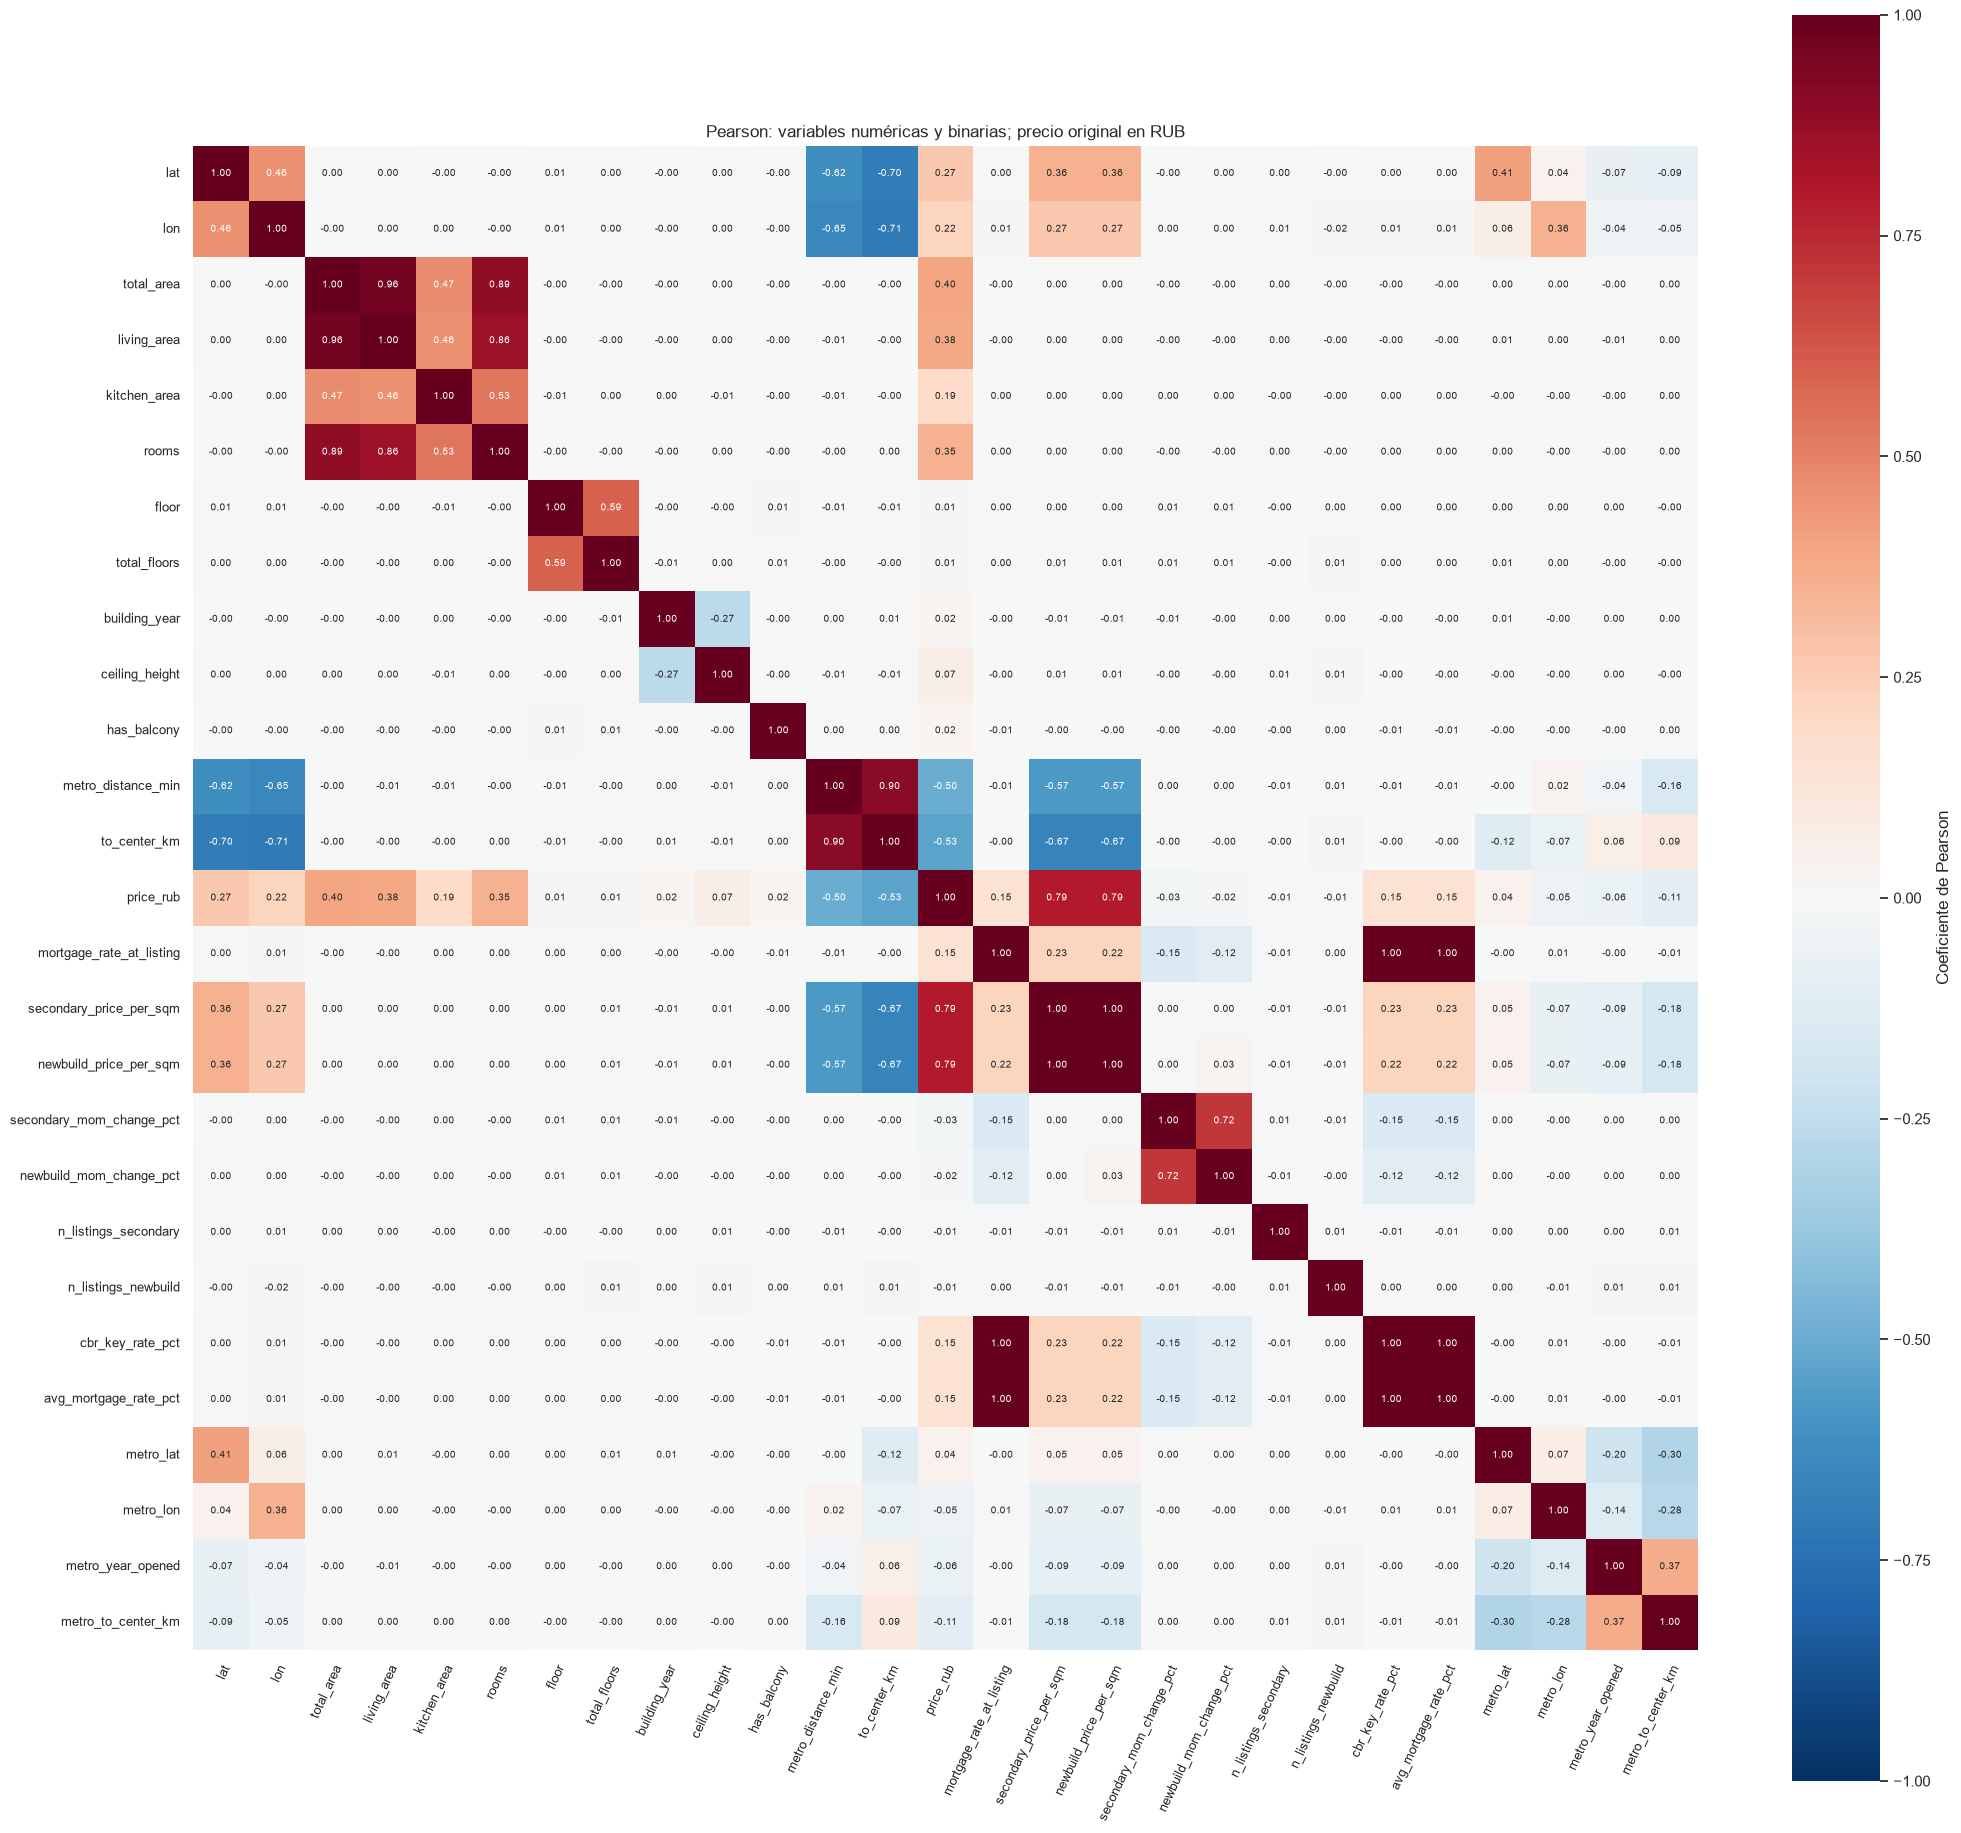

In [23]:
from IPython.display import Markdown

exclusiones_correlacion = {"id", "complex_id", "price_per_sqm", "_merge_district_prices", "_merge_metro_stations"}
variables_correlacion = [c for c in df_venta_enriquecido.select_dtypes(include=["number", "bool"])
                        if c not in exclusiones_correlacion]
assert "price_rub" in variables_correlacion and "price_per_sqm" not in variables_correlacion
binarias_correlacion = df_venta_enriquecido[variables_correlacion].select_dtypes(include="bool").columns.tolist()
datos_correlacion = df_venta_enriquecido[variables_correlacion].astype(float).copy()
for variable in binarias_correlacion:
    assert set(datos_correlacion[variable].dropna().unique()).issubset({0.0, 1.0})
# Solo la tabla auxiliar de cálculo convierte no finitos en faltantes.
datos_correlacion = datos_correlacion.where(np.isfinite(datos_correlacion))
diagnostico_variables_correlacion = pd.DataFrame({
    "n_validos": datos_correlacion.count(),
    "faltantes_originales": df_venta_enriquecido[variables_correlacion].isna().sum(),
    "no_finitos_no_nulos": (df_venta_enriquecido[variables_correlacion].notna()
                           & ~np.isfinite(df_venta_enriquecido[variables_correlacion])).sum(),
    "valores_distintos_validos": datos_correlacion.nunique(),
})
diagnostico_variables_correlacion["constante"] = diagnostico_variables_correlacion["valores_distintos_validos"].eq(1)
display(diagnostico_variables_correlacion)
matriz_correlacion = datos_correlacion.corr(method="pearson", min_periods=2)
indicadores_validos_correlacion = datos_correlacion.notna().astype("int64")
conteos_pares = indicadores_validos_correlacion.T.dot(indicadores_validos_correlacion)
for variable in variables_correlacion:
    if datos_correlacion[variable].count() >= 2 and datos_correlacion[variable].nunique() > 1:
        assert np.isclose(matriz_correlacion.loc[variable, variable], 1.0)
correlaciones_no_calculables = pd.DataFrame([
    {"variable_1": a, "variable_2": b, "n_pares": int(conteos_pares.loc[a,b])}
    for i,a in enumerate(variables_correlacion) for b in variables_correlacion[i:]
    if pd.isna(matriz_correlacion.loc[a,b])
], columns=["variable_1", "variable_2", "n_pares"])
display(matriz_correlacion.style.format("{:.4f}"))
print("Cantidad de observaciones finitas por par:")
display(conteos_pares)
if correlaciones_no_calculables.empty:
    print("No hay correlaciones no calculables ni columnas constantes entre las incluidas.")
else:
    print("Correlaciones no calculables: revisar n y variación dentro de cada par.")
    display(correlaciones_no_calculables)
fig,ax=plt.subplots(figsize=(21,19))
sns.heatmap(matriz_correlacion, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, annot_kws={"size":7}, ax=ax,
            cbar_kws={"label":"Coeficiente de Pearson"})
ax.set(title="Pearson: variables numéricas y binarias; precio original en RUB", xlabel="", ylabel="")
ax.tick_params(axis="x", labelrotation=65, labelsize=9)
ax.tick_params(axis="y", labelrotation=0, labelsize=9)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
fig.tight_layout()
plt.show()

### 5.2. Correlaciones elevadas entre predictores


In [24]:
predictores_vif = [c for c in variables_correlacion if c != "price_rub"]
columnas_join = set(district_sales_columns + metro_added_columns)
def origen_correlacion(variable):
    if variable in district_sales_columns: return "Integración distrital mensual"
    if variable in metro_added_columns: return "Integración de estaciones de metro"
    return "Anuncio original"
pares_altos=[]
for i,a in enumerate(predictores_vif):
    for b in predictores_vif[i+1:]:
        r=matriz_correlacion.loc[a,b]
        if pd.notna(r) and abs(r)>=.80:
            pares_altos.append({"variable_1":a,"variable_2":b,"Pearson_r":r,"abs_r":abs(r),
                                "n_pares":int(conteos_pares.loc[a,b]),
                                "origen_1":origen_correlacion(a),"origen_2":origen_correlacion(b),
                                "ambas_del_join":a in columnas_join and b in columnas_join,
                                "cercana_a_perfecta":1-abs(r)<=1e-8})
pares_correlacion_alta=pd.DataFrame(pares_altos, columns=[
    "variable_1","variable_2","Pearson_r","abs_r","n_pares","origen_1","origen_2","ambas_del_join","cercana_a_perfecta"
]).sort_values("abs_r",ascending=False,kind="stable")
display(pares_correlacion_alta.style.format({"Pearson_r":"{:.6f}","abs_r":"{:.6f}"}))

,variable_1,variable_2,Pearson_r,abs_r,n_pares,origen_1,origen_2,ambas_del_join,cercana_a_perfecta
4,mortgage_rate_at_listing,cbr_key_rate_pct,1.000000,1.000000,50000,Anuncio original,Integración distrital mensual,False,True
5,mortgage_rate_at_listing,avg_mortgage_rate_pct,1.000000,1.000000,50000,Anuncio original,Integración distrital mensual,False,True
7,cbr_key_rate_pct,avg_mortgage_rate_pct,1.000000,1.000000,50000,Integración distrital mensual,Integración distrital mensual,True,True
6,secondary_price_per_sqm,newbuild_price_per_sqm,0.997952,0.997952,50000,Integración distrital mensual,Integración distrital mensual,True,False
0,total_area,living_area,0.963629,0.963629,50000,Anuncio original,Anuncio original,False,False
3,metro_distance_min,to_center_km,0.901629,0.901629,50000,Anuncio original,Anuncio original,False,False
1,total_area,rooms,0.888344,0.888344,50000,Anuncio original,Anuncio original,False,False
2,living_area,rooms,0.856639,0.856639,50000,Anuncio original,Anuncio original,False,False


### 5.3. Factor de inflación de la varianza (VIF)

In [25]:
muestra_comun_vif = datos_correlacion[predictores_vif].dropna().copy()
n_vif = len(muestra_comun_vif)
resumen_muestra_vif = pd.Series({"registros_integrado":len(df_venta_enriquecido),
    "registros_comunes_vif":n_vif,"omitidos_solo_del_vif":len(df_venta_enriquecido)-n_vif,
    "predictores_considerados":len(predictores_vif)},name="valor")
display(resumen_muestra_vif.to_frame())
if n_vif < 3:
    raise ValueError("La muestra común no permite calcular VIF; revisar faltantes sin imputarlos automáticamente.")
constantes_vif = muestra_comun_vif.columns[muestra_comun_vif.nunique().le(1)].tolist()
duplicadas_vif = pd.DataFrame([
    {"variable_1":a,"variable_2":b}
    for i,a in enumerate(predictores_vif) for b in predictores_vif[i+1:]
    if muestra_comun_vif[a].equals(muestra_comun_vif[b])
], columns=["variable_1","variable_2"])
print(f"Constantes en la muestra común: {constantes_vif or 'ninguna'}.")
print("Predictores idénticos en la muestra común:")
display(duplicadas_vif)
variables_no_constantes_vif = [c for c in predictores_vif if c not in constantes_vif]
matriz_vif = muestra_comun_vif[variables_no_constantes_vif]
z_vif = ((matriz_vif-matriz_vif.mean())/matriz_vif.std(ddof=0)).to_numpy()
if z_vif.shape[1]:
    _,singulares_vif,vh_vif=np.linalg.svd(z_vif,full_matrices=False)
    tolerancia_rango_vif=max(z_vif.shape)*np.finfo(float).eps*singulares_vif[0]
    rango_vif=int((singulares_vif>tolerancia_rango_vif).sum())
    espacio_nulo_vif=vh_vif[rango_vif:,:].T
else:
    tolerancia_rango_vif=np.nan;rango_vif=0;espacio_nulo_vif=np.empty((0,0))
cargas_dependencias_vif=pd.DataFrame(espacio_nulo_vif,index=variables_no_constantes_vif,
    columns=[f"relacion_{i+1}" for i in range(espacio_nulo_vif.shape[1])])
# Una carga material del espacio nulo implica participación en alguna dependencia exacta.
involucradas_dependencia_vif = (np.linalg.norm(espacio_nulo_vif,axis=1)>1e-7
                               if espacio_nulo_vif.shape[1] else np.zeros(len(variables_no_constantes_vif),dtype=bool))
variables_dependientes_vif = [v for v,flag in zip(variables_no_constantes_vif,involucradas_dependencia_vif) if flag]
print(f"Rango de los predictores centrados: {rango_vif} de {len(variables_no_constantes_vif)}; "
      f"dependencias lineales: {espacio_nulo_vif.shape[1]}; tolerancia SVD: {tolerancia_rango_vif:.3g}.")
if espacio_nulo_vif.shape[1]:
    print("Cargas de las relaciones nulas entre predictores estandarizados (Z × cargas ≈ 0):")
    display(cargas_dependencias_vif.loc[variables_dependientes_vif])
filas_vif=[]
for variable in predictores_vif:
    if variable in constantes_vif:
        valor=np.nan;estado="No calculable: predictor constante"
    elif variable in variables_dependientes_vif:
        valor=np.inf;estado="Dependencia lineal perfecta"
    else:
        j=variables_no_constantes_vif.index(variable)
        y=z_vif[:,j];otros=np.delete(z_vif,j,axis=1)
        residuo=y-otros@np.linalg.lstsq(otros,y,rcond=None)[0] if otros.shape[1] else y
        fraccion_residual=float(residuo@residuo/(y@y))
        valor=1/fraccion_residual if fraccion_residual>0 else np.inf
        if not np.isfinite(valor):estado="Dependencia perfecta o no resoluble numéricamente"
        elif valor>10:estado="Severa (>10)"
        elif valor>=5:estado="Elevada (5–10)"
        elif np.isclose(valor,1,atol=.05,rtol=0):estado="Prácticamente ausente (cercano a 1)"
        else:estado="Baja o moderada (1–5)"
    filas_vif.append({"predictor":variable,"VIF":valor,"diagnostico":estado,"n_comun":n_vif,
                       "origen":origen_correlacion(variable)})
tabla_vif=pd.DataFrame(filas_vif).sort_values("VIF",ascending=False,kind="stable",na_position="last")
display(tabla_vif)

Constantes en la muestra común: ninguna.
Predictores idénticos en la muestra común:
Rango de los predictores centrados: 24 de 26; dependencias lineales: 2; tolerancia SVD: 4.94e-09.
Cargas de las relaciones nulas entre predictores estandarizados (Z × cargas ≈ 0):


,valor
registros_integrado,50000
registros_comunes_vif,49322
omitidos_solo_del_vif,678
predictores_considerados,26


,variable_1,variable_2
0,mortgage_rate_at_listing,avg_mortgage_rate_pct


,relacion_1,relacion_2
mortgage_rate_at_listing,-0.82,-0.01
cbr_key_rate_pct,0.42,-0.70
avg_mortgage_rate_pct,0.40,0.71


,predictor,VIF,diagnostico,n_comun,origen
13,mortgage_rate_at_listing,inf,Dependencia lineal perfecta,49322,Anuncio original
20,cbr_key_rate_pct,inf,Dependencia lineal perfecta,49322,Integración distrital mensual
21,avg_mortgage_rate_pct,inf,Dependencia lineal perfecta,49322,Integración distrital mensual
14,secondary_price_per_sqm,426.79,Severa (>10),49322,Integración distrital mensual
15,newbuild_price_per_sqm,425.11,Severa (>10),49322,Integración distrital mensual
2,total_area,17.67,Severa (>10),49322,Anuncio original
3,living_area,13.99,Severa (>10),49322,Anuncio original
12,to_center_km,13.84,Severa (>10),49322,Anuncio original
11,metro_distance_min,8.06,Elevada (5–10),49322,Anuncio original
5,rooms,5.14,Elevada (5–10),49322,Anuncio original


### 5.4. Dependencias entre tasas de interés

Se comprueban sobre los valores originales disponibles las identidades `avg_mortgage_rate_pct = cbr_key_rate_pct + 2.5` y `mortgage_rate_at_listing = avg_mortgage_rate_pct`. Se informa igualdad exacta en memoria, además de la desviación máxima absoluta y el tamaño usado. Así se distingue una relación matemática en los datos de una correlación que solo redondea a 1.

In [26]:
tasas_interes = ["cbr_key_rate_pct","avg_mortgage_rate_pct","mortgage_rate_at_listing"]
pares_tasas = datos_correlacion[tasas_interes].dropna()
filas_tasas=[]
for nombre,izquierda,derecha in [
    ("avg_mortgage_rate_pct = cbr_key_rate_pct + 2.5",pares_tasas["avg_mortgage_rate_pct"],pares_tasas["cbr_key_rate_pct"]+2.5),
    ("mortgage_rate_at_listing = avg_mortgage_rate_pct",pares_tasas["mortgage_rate_at_listing"],pares_tasas["avg_mortgage_rate_pct"]),
]:
    diferencia=izquierda-derecha
    filas_tasas.append({"relacion":nombre,"n_validos":len(pares_tasas),
                       "igualdad_exacta":bool(diferencia.eq(0).all()) if len(pares_tasas) else False,
                       "error_maximo_absoluto":diferencia.abs().max()})
verificacion_tasas=pd.DataFrame(filas_tasas)
display(matriz_correlacion.loc[tasas_interes,tasas_interes])
display(verificacion_tasas)
if len(pares_tasas) and verificacion_tasas["igualdad_exacta"].all():
    display(Markdown(
        f"**Resultado actual:** las tres tasas tienen correlación positiva perfecta en {len(pares_tasas):,} anuncios "
        "y las dos igualdades se cumplen exactamente, con error máximo cero. La tasa hipotecaria del anuncio "
        "y la tasa hipotecaria media son idénticas; la tasa de referencia solo difiere en una constante de 2,5 puntos porcentuales. "
        "Con intercepto, estas tres columnas aportan una única dirección de variación y generan dos dependencias lineales. "
        "Sus VIF son infinitos. OLS con las tres tasas y un intercepto no puede identificar coeficientes individuales únicos: "
        "una solución numérica por pseudoinversa no resuelve esa falta de identificación. No se elimina ninguna tasa en esta etapa."
    ))
else:
    display(Markdown("Las identidades comprobadas no se verifican en todos los pares actuales; interpretar la correlación y los errores mostrados sin asumir multicolinealidad perfecta."))

,cbr_key_rate_pct,avg_mortgage_rate_pct,mortgage_rate_at_listing
cbr_key_rate_pct,1.00,1.00,1.00
avg_mortgage_rate_pct,1.00,1.00,1.00
mortgage_rate_at_listing,1.00,1.00,1.00


,relacion,n_validos,igualdad_exacta,error_maximo_absoluto
0,avg_mortgage_rate_pct = cbr_key_rate_pct + 2.5,50000,True,0.00
1,mortgage_rate_at_listing = avg_mortgage_rate_pct,50000,True,0.00


**Resultado actual:** las tres tasas tienen correlación positiva perfecta en 50,000 anuncios y las dos igualdades se cumplen exactamente, con error máximo cero. La tasa hipotecaria del anuncio y la tasa hipotecaria media son idénticas; la tasa de referencia solo difiere en una constante de 2,5 puntos porcentuales. Con intercepto, estas tres columnas aportan una única dirección de variación y generan dos dependencias lineales. Sus VIF son infinitos. OLS con las tres tasas y un intercepto no puede identificar coeficientes individuales únicos: una solución numérica por pseudoinversa no resuelve esa falta de identificación. No se elimina ninguna tasa en esta etapa.

### 5.5. Síntesis del diagnóstico

Las conclusiones siguientes se generan con las matrices, la muestra común y los VIF actuales. Los umbrales son orientativos y no definen una selección final de características.

In [27]:
asociaciones_objetivo = matriz_correlacion["price_rub"].drop("price_rub").dropna()
positivas_objetivo = asociaciones_objetivo.loc[asociaciones_objetivo.gt(0)].nlargest(4)
negativas_objetivo = asociaciones_objetivo.loc[asociaciones_objetivo.lt(0)].nsmallest(3)
def texto_correlaciones(serie):
    return "; ".join(f"`{v}`: {r:.3f}" for v,r in serie.items()) or "ninguna calculable"
vif_finitos = tabla_vif.loc[np.isfinite(tabla_vif["VIF"])]
vif_severos = vif_finitos.loc[vif_finitos.VIF.gt(10)]
vif_elevados = vif_finitos.loc[vif_finitos.VIF.ge(5)&vif_finitos.VIF.le(10)]
vif_moderados = vif_finitos.loc[vif_finitos.VIF.lt(5)]
def texto_vif(tabla):
    return "; ".join(f"`{f.predictor}`: {f.VIF:.2f}" for f in tabla.itertuples()) or "ninguno"
display(Markdown(
    f"**Relación con el precio:** las asociaciones positivas de mayor magnitud son {texto_correlaciones(positivas_objetivo)}; "
    f"las negativas más importantes son {texto_correlaciones(negativas_objetivo)}. Son asociaciones lineales descriptivas, sin interpretación causal.\n\n"
    f"**Redundancia entre predictores:** se detectan {len(pares_correlacion_alta)} pares con |r| ≥ 0,80. "
    "Las superficies y habitaciones comparten información; también las distancias al metro y al centro. "
    "Las referencias distritales de usadas y nuevas están muy próximas entre sí y deben revisarse como posible redundancia, "
    "sin confundir su alta correlación con igualdad matemática. Las tasas se verifican por separado mediante sus identidades exactas.\n\n"
    f"**VIF sobre {n_vif:,} anuncios comunes:** dependencia perfecta en {', '.join('`'+v+'`' for v in variables_dependientes_vif) or 'ninguna variable'}; "
    f"valores finitos severos (>10): {texto_vif(vif_severos)}; elevados (5–10): {texto_vif(vif_elevados)}. "
    f"Los restantes {len(vif_moderados)} VIF finitos son inferiores a 5 y se detallan en la tabla, incluidos los cercanos a 1. "
    "Un VIF alto puede surgir de la combinación de varios predictores incluso si ningún par supera el umbral de Pearson. "
    "Los VIF finitos se interpretan condicionados al conjunto de columnas considerado; la singularidad global de las tasas "
    "sigue impidiendo identificar todos los coeficientes del diseño completo.\n\n"
    "**Implicaciones para OLS:** revisar las tasas, referencias de precios, superficies, habitaciones y demás predictores "
    "señalados por VIF al diseñar la futura selección, sin eliminar variables ahora. Los indicadores económicos y distritales "
    "repiten contexto temporal/territorial entre anuncios; las variables geográficas también pueden compartir información espacial. "
    "La disponibilidad histórica y construcción de referencias contemporáneas requieren auditoría para evitar fuga, independientemente "
    "de su correlación o VIF. Este diagnóstico no valida independencia de anuncios ni estima causalidad. "
    "La muestra común puede cambiar de composición por faltantes: sus resultados no se trasladan automáticamente a otros conjuntos. "
    "No se entrena un modelo predictivo ni se anticipa una selección por Best Subset o Stepwise."
))

**Relación con el precio:** las asociaciones positivas de mayor magnitud son `secondary_price_per_sqm`: 0.791; `newbuild_price_per_sqm`: 0.789; `total_area`: 0.398; `living_area`: 0.385; las negativas más importantes son `to_center_km`: -0.533; `metro_distance_min`: -0.496; `metro_to_center_km`: -0.106. Son asociaciones lineales descriptivas, sin interpretación causal.

**Redundancia entre predictores:** se detectan 8 pares con |r| ≥ 0,80. Las superficies y habitaciones comparten información; también las distancias al metro y al centro. Las referencias distritales de usadas y nuevas están muy próximas entre sí y deben revisarse como posible redundancia, sin confundir su alta correlación con igualdad matemática. Las tasas se verifican por separado mediante sus identidades exactas.

**VIF sobre 49,322 anuncios comunes:** dependencia perfecta en `mortgage_rate_at_listing`, `cbr_key_rate_pct`, `avg_mortgage_rate_pct`; valores finitos severos (>10): `secondary_price_per_sqm`: 426.79; `newbuild_price_per_sqm`: 425.11; `total_area`: 17.67; `living_area`: 13.99; `to_center_km`: 13.84; elevados (5–10): `metro_distance_min`: 8.06; `rooms`: 5.14. Los restantes 16 VIF finitos son inferiores a 5 y se detallan en la tabla, incluidos los cercanos a 1. Un VIF alto puede surgir de la combinación de varios predictores incluso si ningún par supera el umbral de Pearson. Los VIF finitos se interpretan condicionados al conjunto de columnas considerado; la singularidad global de las tasas sigue impidiendo identificar todos los coeficientes del diseño completo.

**Implicaciones para OLS:** revisar las tasas, referencias de precios, superficies, habitaciones y demás predictores señalados por VIF al diseñar la futura selección, sin eliminar variables ahora. Los indicadores económicos y distritales repiten contexto temporal/territorial entre anuncios; las variables geográficas también pueden compartir información espacial. La disponibilidad histórica y construcción de referencias contemporáneas requieren auditoría para evitar fuga, independientemente de su correlación o VIF. Este diagnóstico no valida independencia de anuncios ni estima causalidad. La muestra común puede cambiar de composición por faltantes: sus resultados no se trasladan automáticamente a otros conjuntos. No se entrena un modelo predictivo ni se anticipa una selección por Best Subset o Stepwise.

<a id="analisis-temporal"></a>

## 6. Análisis temporal de `price_rub`: tendencia, estacionalidad y ciclos

Se analiza la mediana mensual del precio nominal publicado, conservando todas las observaciones del integrado. Los agregados corresponden a anuncios de propiedades distintas; no miden la revalorización de una misma vivienda.

<a id="serie-mensual-precio"></a>
<a id="ciclos-precio"></a>

### 6.1. Tendencia y posibles ciclos

La mediana mensual y la tendencia STL robusta (período 12) permiten distinguir el cambio de nivel de las fluctuaciones de corto plazo. Se estima una sola descomposición, sin interpolar meses faltantes. El último año tiene cobertura parcial.

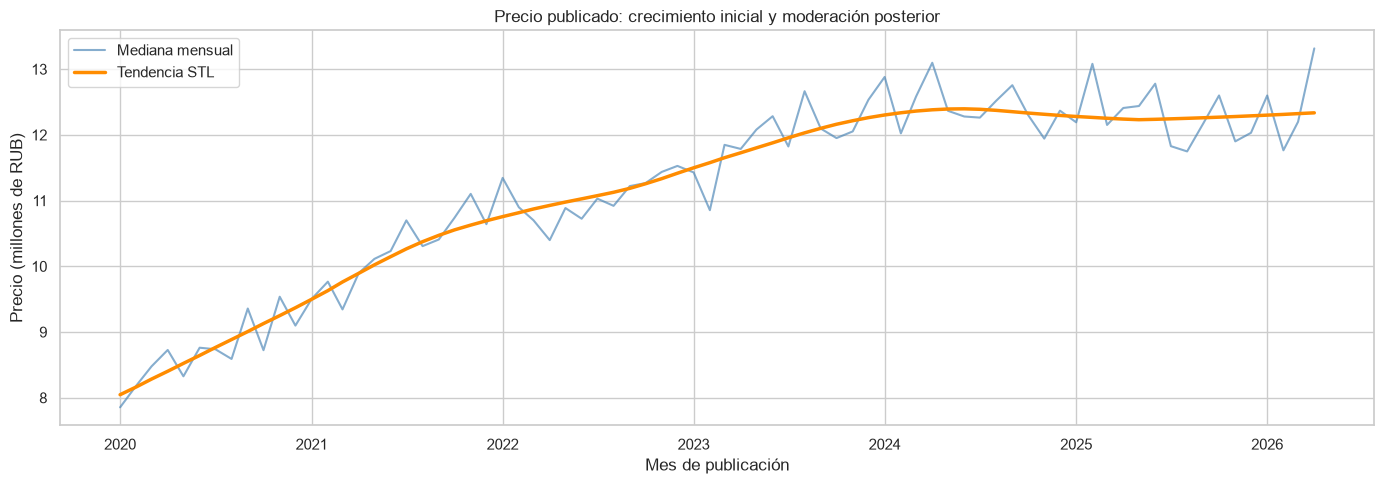

In [ ]:
from statsmodels.tsa.seasonal import STL

datos_temporales = df_venta_enriquecido[["date_posted_dt", "price_rub"]].copy().sort_values(
    "date_posted_dt", ascending=True, na_position="last", kind="stable")
validos_temporales = (datos_temporales["date_posted_dt"].notna()
                     & datos_temporales["price_rub"].notna()
                     & np.isfinite(datos_temporales["price_rub"]))
observaciones_temporales_validas = datos_temporales.loc[validos_temporales]
if observaciones_temporales_validas.empty:
    raise ValueError("No hay fechas y precios válidos para el análisis temporal.")
series_mensuales = (observaciones_temporales_validas.set_index("date_posted_dt")["price_rub"]
                    .resample("MS").median().to_frame("mediana_rub"))
if series_mensuales["mediana_rub"].isna().any() or len(series_mensuales) < 24:
    raise ValueError("STL requiere al menos 24 meses consecutivos con mediana válida; no se interpolan datos.")
stl_precio = STL(series_mensuales["mediana_rub"], period=12, robust=True).fit()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(series_mensuales.index, series_mensuales["mediana_rub"] / 1e6,
        color="steelblue", alpha=.65, label="Mediana mensual")
ax.plot(series_mensuales.index, stl_precio.trend / 1e6,
        color="darkorange", linewidth=2.5, label="Tendencia STL")
ax.set(title="Precio publicado: crecimiento inicial y moderación posterior",
       xlabel="Mes de publicación", ylabel="Precio (millones de RUB)")
ax.legend()
fig.tight_layout()
plt.show()

<a id="estacionalidad-precio"></a>

### 6.2. Estacionalidad

Se comparan únicamente años con doce meses, expresando cada mediana como desvío porcentual respecto de su tendencia STL. Un patrón anual estable requeriría perfiles similares entre años; la periodicidad fijada en STL no constituye por sí sola evidencia de estacionalidad.

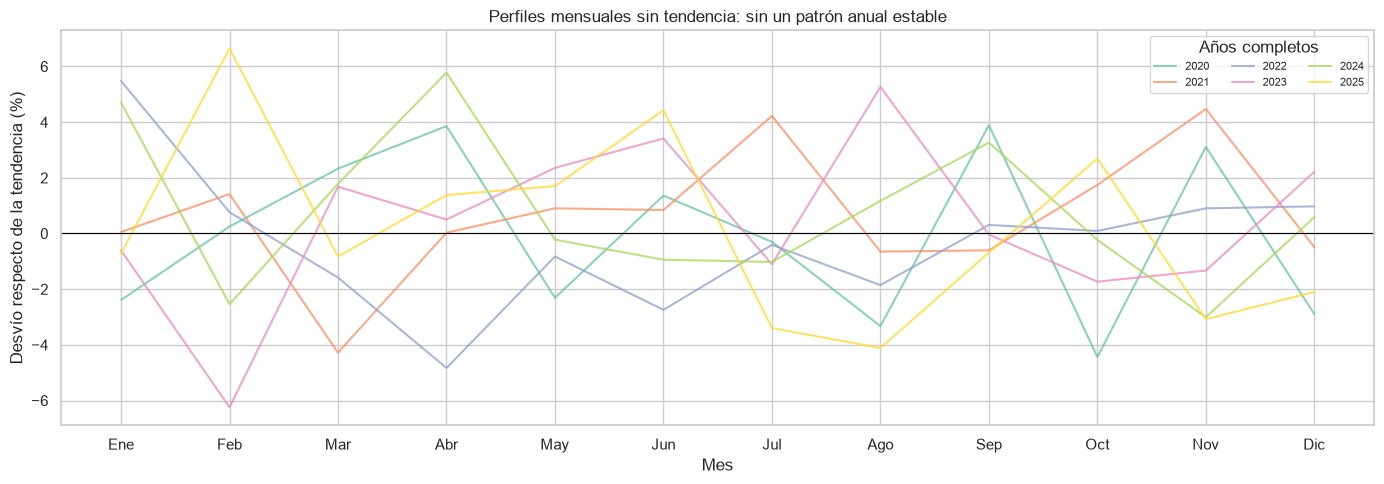

In [ ]:
perfil_estacional_temporal = series_mensuales.assign(
    anio=series_mensuales.index.year, mes=series_mensuales.index.month,
    desvio_tendencia_pct=(series_mensuales["mediana_rub"] / stl_precio.trend - 1) * 100)
anios_completos = [anio for anio, perfil in perfil_estacional_temporal.groupby("anio")
                  if len(perfil) == 12]
fig, ax = plt.subplots(figsize=(14, 5))
for anio in anios_completos:
    perfil = perfil_estacional_temporal.loc[perfil_estacional_temporal["anio"].eq(anio)]
    ax.plot(perfil["mes"], perfil["desvio_tendencia_pct"], linewidth=1.5,
            alpha=.75, label=str(anio))
ax.axhline(0, color="black", linewidth=.8)
ax.set(title="Perfiles mensuales sin tendencia: sin un patrón anual estable",
       xlabel="Mes", ylabel="Desvío respecto de la tendencia (%)",
       xticks=range(1, 13), xticklabels=["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                                               "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.legend(title="Años completos", ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

<a id="conclusiones-temporales"></a>

### 6.3. Resumen interpretativo

**Tendencia:** los precios nominales muestran crecimiento inicial y moderación posterior.  
**Estacionalidad:** los perfiles mensuales cambian entre años; no se identifica un patrón anual estable.  
**Ciclos:** las oscilaciones no forman expansiones y contracciones recurrentes; no se identifican ciclos definidos en el período observado.

<a id="alternativas-outliers"></a>

## 7. Evaluación de alternativas para el tratamiento de outliers de la variable objetivo

Los apartados 7.1-7.4 comparan **escenarios experimentales** de `price_rub` en RUB: original, winsorización y trimming. Se reutilizan los límites de Tukey del apartado 3.3; no se recalculan con las muestras tratadas y no se adopta un tratamiento definitivo. El integrado y su CSV permanecen intactos. Los DataFrames experimentales no reemplazan los utilizados en los apartados anteriores ni se exportan.

La subsección 7.5 desarrolla un experimento independiente cuyos límites se estiman exclusivamente dentro del 80% cronológico inicial.

### 7.1. Preparación y tratamientos independientes

La winsorización reemplaza solo los precios identificados como atípicos por el menor o mayor **precio observado no atípico**, según el extremo superado; no utiliza el límite teórico como sustituto. Trimming excluye únicamente los registros previamente identificados como atípicos, conservando íntegramente los restantes. Las demás variables se mantienen sin modificaciones. Si hubiera precios faltantes o no finitos, no se convertirían automáticamente en outliers: permanecerían en las copias y no entrarían en los estadísticos de distribución. En los datos actuales todos los precios son finitos.

In [37]:
import hashlib
from scipy.stats import gaussian_kde, norm, probplot
from IPython.display import Markdown

# Referencia inmutable para verificar que el experimento no afecta al análisis previo.
referencia_integrado_exp7 = df_venta_enriquecido.copy(deep=True)
huella_csv_antes_exp7 = hashlib.sha256(OUTPUT_PATH.read_bytes()).hexdigest() if OUTPUT_PATH.is_file() else None
limites_fijos_exp7 = pd.Series({"limite_inferior_RUB":limite_inferior_precio,
                              "limite_superior_RUB":limite_superior_precio}, name="valor")
display(limites_fijos_exp7.to_frame())
precio_referencia_exp7 = df_venta_enriquecido["price_rub"]
precio_finito_exp7 = precio_referencia_exp7.notna() & np.isfinite(precio_referencia_exp7)
inferiores_exp7 = outliers_inferiores_precio.reindex(df_venta_enriquecido.index).copy()
superiores_exp7 = outliers_superiores_precio.reindex(df_venta_enriquecido.index).copy()
if inferiores_exp7.isna().any() or superiores_exp7.isna().any():
    raise ValueError("La clasificación previa no cubre el integrado actual; revisar la ejecución de 3.3.")
mascara_outliers_exp7 = inferiores_exp7 | superiores_exp7
pd.testing.assert_series_equal(mascara_outliers_exp7, extremos_precio, check_names=False)
pd.testing.assert_frame_equal(outliers_precio, df_venta_enriquecido.loc[mascara_outliers_exp7])
assert inferiores_exp7.equals(precio_finito_exp7 & precio_referencia_exp7.lt(limite_inferior_precio))
assert superiores_exp7.equals(precio_finito_exp7 & precio_referencia_exp7.gt(limite_superior_precio))
precios_no_atipicos_exp7 = precio_referencia_exp7.loc[precio_finito_exp7 & ~mascara_outliers_exp7]
if precios_no_atipicos_exp7.empty:
    raise ValueError("No hay precios no atípicos observados para definir los reemplazos.")
minimo_observado_no_atipico_exp7 = precios_no_atipicos_exp7.min()
maximo_observado_no_atipico_exp7 = precios_no_atipicos_exp7.max()
display(pd.Series({"menor_precio_no_atipico_RUB":minimo_observado_no_atipico_exp7,
                   "mayor_precio_no_atipico_RUB":maximo_observado_no_atipico_exp7},name="valor").to_frame())

df_winsorizado_exp7 = df_venta_enriquecido.copy(deep=True)
df_winsorizado_exp7.loc[inferiores_exp7,"price_rub"] = minimo_observado_no_atipico_exp7
df_winsorizado_exp7.loc[superiores_exp7,"price_rub"] = maximo_observado_no_atipico_exp7
df_trimming_exp7 = df_venta_enriquecido.loc[~mascara_outliers_exp7].copy(deep=True)
modificados_wins_exp7 = (~precio_referencia_exp7.eq(df_winsorizado_exp7["price_rub"]) &
                        ~(precio_referencia_exp7.isna() & df_winsorizado_exp7["price_rub"].isna()))
n_original_exp7 = len(df_venta_enriquecido)
n_modificados_wins_exp7 = int(modificados_wins_exp7.sum())
n_eliminados_trim_exp7 = n_original_exp7-len(df_trimming_exp7)
resumen_tratamientos_exp7 = pd.DataFrame([
    {"escenario":"Original","registros":n_original_exp7,"modificados":0,"eliminados":0,"conservados_pct":100.,"modificados_pct_total":0.},
    {"escenario":"Winsorización","registros":len(df_winsorizado_exp7),"modificados":n_modificados_wins_exp7,
     "eliminados":0,"conservados_pct":len(df_winsorizado_exp7)/n_original_exp7*100,
     "modificados_pct_total":n_modificados_wins_exp7/n_original_exp7*100},
    {"escenario":"Trimming","registros":len(df_trimming_exp7),"modificados":0,"eliminados":n_eliminados_trim_exp7,
     "conservados_pct":len(df_trimming_exp7)/n_original_exp7*100,"modificados_pct_total":0.},
]).set_index("escenario")
display(resumen_tratamientos_exp7)
# Verificar independencia de tratamientos y conservación de las demás características.
otras_columnas_exp7 = df_venta_enriquecido.columns.drop("price_rub")
pd.testing.assert_frame_equal(df_winsorizado_exp7[otras_columnas_exp7],df_venta_enriquecido[otras_columnas_exp7])
pd.testing.assert_series_equal(df_winsorizado_exp7.loc[~mascara_outliers_exp7,"price_rub"],
                               df_venta_enriquecido.loc[~mascara_outliers_exp7,"price_rub"])
pd.testing.assert_frame_equal(df_trimming_exp7,df_venta_enriquecido.loc[~mascara_outliers_exp7])
assert n_modificados_wins_exp7 == int(mascara_outliers_exp7.sum())

,valor
limite_inferior_RUB,"-5,876,500.00"
limite_superior_RUB,"29,745,500.00"


,valor
menor_precio_no_atipico_RUB,1019000
mayor_precio_no_atipico_RUB,29744000


,registros,modificados,eliminados,conservados_pct,modificados_pct_total
escenario,,,,,
Original,50000,0,0,100.00,0.00
Winsorización,50000,2459,0,100.00,4.92
Trimming,47541,0,2459,95.08,0.00


### 7.2. Estadísticas comparativas y concentración en los extremos

La tabla compara los tres escenarios completos. Los estadísticos de precio se calculan con sus valores finitos; la cantidad de registros cuenta todas las filas de cada escenario. La asimetría y la **curtosis en exceso** usan los estimadores ajustados de pandas: en una normal sus valores de referencia son cero. Se informa por separado la acumulación de precios exactamente en los valores de reemplazo; una KDE suavizada puede disimular esa masa puntual.

In [38]:
escenarios_exp7 = {"Original":df_venta_enriquecido,"Winsorización":df_winsorizado_exp7,"Trimming":df_trimming_exp7}
precios_escenarios_exp7 = {
    nombre:datos.loc[datos["price_rub"].notna() & np.isfinite(datos["price_rub"]),"price_rub"]
    for nombre,datos in escenarios_exp7.items()}
columnas_comparacion_exp7={}
for nombre,precios_escenario in precios_escenarios_exp7.items():
    columnas_comparacion_exp7[nombre] = {
        "Cantidad de registros":len(escenarios_exp7[nombre]),
        "Registros modificados":n_modificados_wins_exp7 if nombre=="Winsorización" else 0,
        "Registros eliminados":n_eliminados_trim_exp7 if nombre=="Trimming" else 0,
        "Media (RUB)":precios_escenario.mean(),"Mediana (RUB)":precios_escenario.median(),
        "Desviación estándar (RUB)":precios_escenario.std(ddof=1),"Mínimo (RUB)":precios_escenario.min(),
        "Máximo (RUB)":precios_escenario.max(),"Asimetría":precios_escenario.skew(),
        "Curtosis (exceso)":precios_escenario.kurt(),
    }
tabla_comparativa_exp7=pd.DataFrame(columnas_comparacion_exp7)
display(tabla_comparativa_exp7.style.format("{:,.4f}").format(
    "{:,.0f}", subset=pd.IndexSlice[["Cantidad de registros", "Registros modificados", "Registros eliminados"], :]))
diagnostico_validez_exp7=pd.DataFrame([
    {"escenario":nombre,"precios_finitos":len(precios_escenarios_exp7[nombre]),
     "precios_faltantes":datos["price_rub"].isna().sum(),
     "precios_no_finitos_no_nulos":(datos["price_rub"].notna() & ~np.isfinite(datos["price_rub"])).sum()}
    for nombre,datos in escenarios_exp7.items()])
display(diagnostico_validez_exp7)
concentracion_extremos_exp7=pd.DataFrame([
    {"escenario":nombre,"en_minimo_reemplazo":int(serie.eq(minimo_observado_no_atipico_exp7).sum()),
     "en_maximo_reemplazo":int(serie.eq(maximo_observado_no_atipico_exp7).sum()),
     "en_maximo_reemplazo_pct":serie.eq(maximo_observado_no_atipico_exp7).sum()/len(escenarios_exp7[nombre])*100}
    for nombre,serie in precios_escenarios_exp7.items()]).set_index("escenario")
display(concentracion_extremos_exp7)

,Original,Winsorización,Trimming
Cantidad de registros,"50,000","50,000","47,541"
Registros modificados,0,"2,459",0
Registros eliminados,0,0,"2,459"
Media (RUB),"13,122,821.5200","12,666,818.9400","11,783,522.6646"
Mediana (RUB),"11,086,000.0000","11,086,000.0000","10,689,000.0000"
Desviación estándar (RUB),"8,564,072.9834","7,044,472.3406","6,027,160.1338"
Mínimo (RUB),"1,019,000.0000","1,019,000.0000","1,019,000.0000"
Máximo (RUB),"93,437,000.0000","29,744,000.0000","29,744,000.0000"
Asimetría,1.9968,0.8783,0.7411
Curtosis (exceso),6.5578,0.0933,0.0423


,escenario,precios_finitos,precios_faltantes,precios_no_finitos_no_nulos
0,Original,50000,0,0
1,Winsorización,50000,0,0
2,Trimming,47541,0,0


,en_minimo_reemplazo,en_maximo_reemplazo,en_maximo_reemplazo_pct
escenario,,,
Original,1,1,0.00
Winsorización,1,2460,4.92
Trimming,1,1,0.00


### 7.3. Histogramas, densidades y gráficos Q-Q

Los tres histogramas utilizan **los mismos intervalos y escalas** y muestran densidad (área igual a uno), para comparar escenarios con cantidades diferentes. Se superponen una KDE gaussiana (ancho de banda de Scott) y una normal de referencia ajustada a la media y desviación estándar muestral de cada escenario. La fila superior cubre todo el rango observado; la inferior es un acercamiento del eje al rango no atípico, identificado expresamente. Los estadísticos, densidades y ajustes normales siempre usan todos los precios finitos de cada escenario, no una muestra ni el rango del acercamiento.

Los Q-Q representan todos los precios ordenados contra cuantiles teóricos de N(0,1). La recta de referencia es `media + desviación × cuantil normal`, expresada en millones de RUB. El eje X es común; el eje Y conserva la unidad monetaria y muestra su escala propia para apreciar las colas de cada escenario. No se transforma el objetivo. La proximidad a la recta se evalúa junto con asimetría, exceso de curtosis y masa en los extremos; no se utilizan pruebas de normalidad como criterio único.

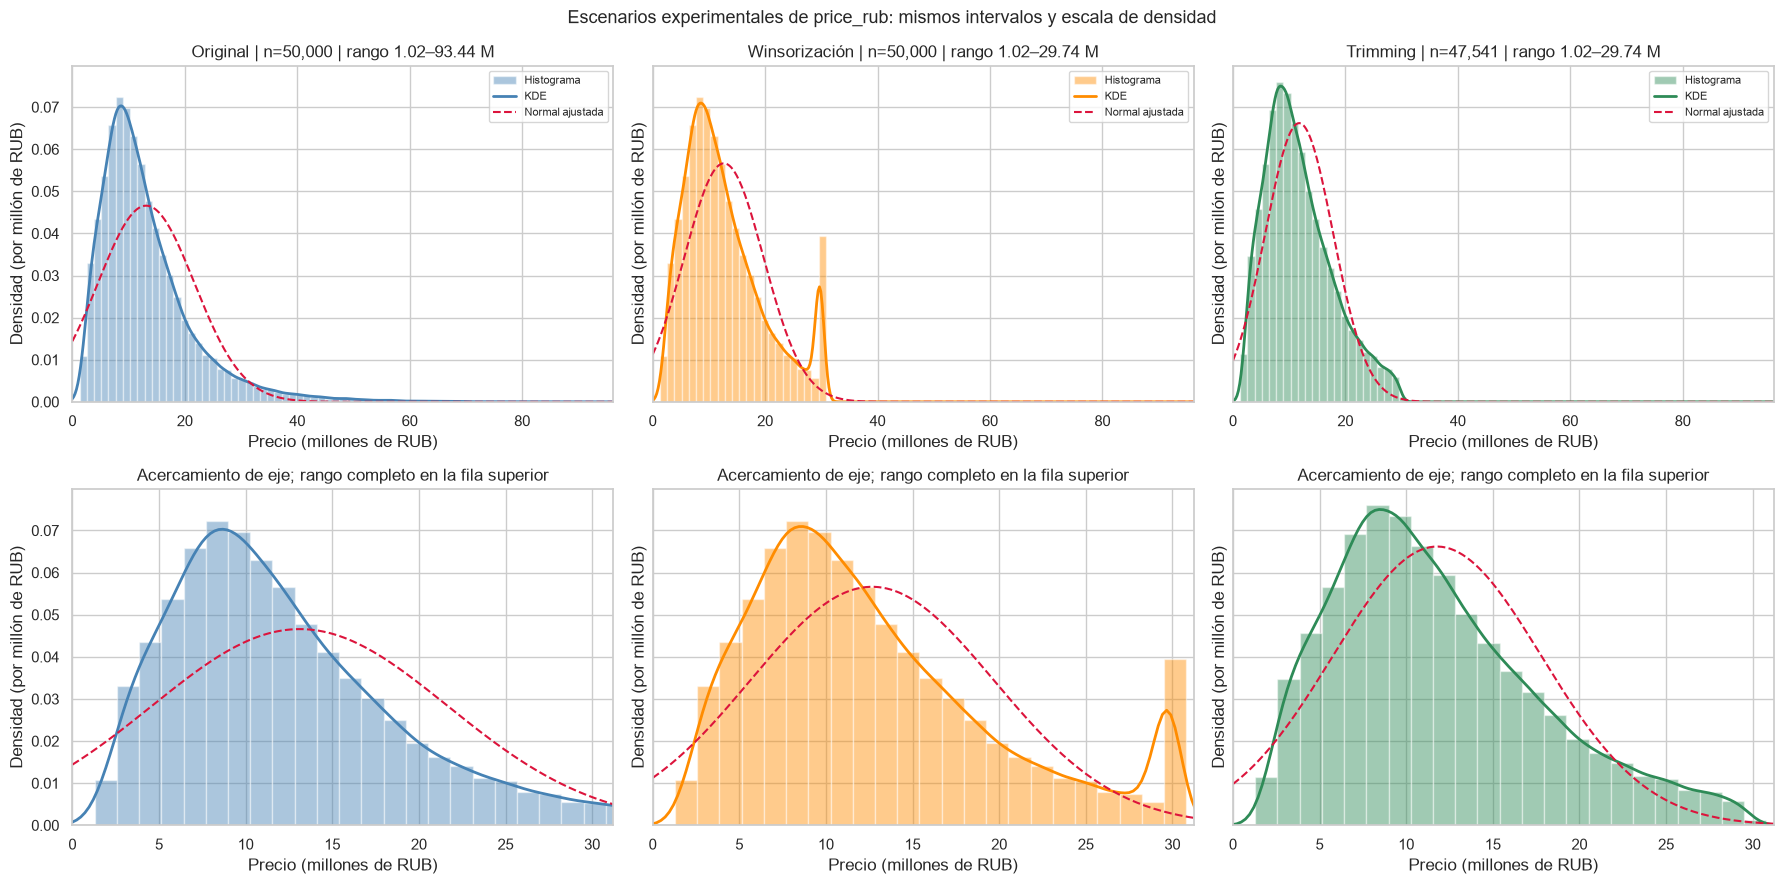

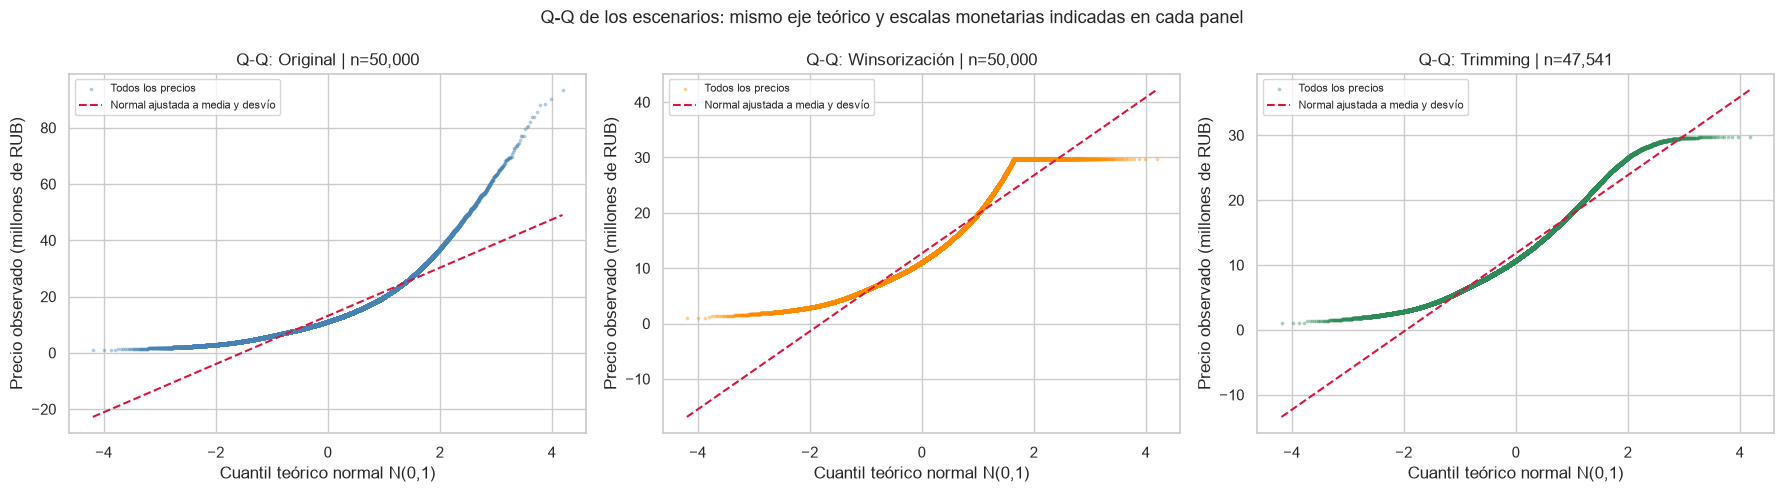

In [39]:
colores_exp7={"Original":"steelblue","Winsorización":"darkorange","Trimming":"seagreen"}
maximo_global_exp7=max(s.max() for s in precios_escenarios_exp7.values())/1e6
bordes_histograma_exp7=np.linspace(0,maximo_global_exp7*1.03,76)
grilla_densidad_exp7=np.linspace(0,maximo_global_exp7*1.03,400)
densidades_exp7={}
normales_referencia_exp7={}
for nombre,serie in precios_escenarios_exp7.items():
    valores=serie.to_numpy(dtype=float)/1e6
    if len(valores)<4 or np.std(valores,ddof=1)==0:
        raise ValueError(f"No hay variación suficiente para evaluar la distribución de {nombre}.")
    densidades_exp7[nombre]=gaussian_kde(valores,bw_method="scott")(grilla_densidad_exp7)
    normales_referencia_exp7[nombre]=norm.pdf(grilla_densidad_exp7,loc=valores.mean(),scale=valores.std(ddof=1))
fig,axes=plt.subplots(2,3,figsize=(18,9),sharey=True)
for columna,(nombre,serie) in enumerate(precios_escenarios_exp7.items()):
    for fila in range(2):
        ax=axes[fila,columna]
        ax.hist(serie/1e6,bins=bordes_histograma_exp7,density=True,alpha=.45,color=colores_exp7[nombre],label="Histograma")
        ax.plot(grilla_densidad_exp7,densidades_exp7[nombre],color=colores_exp7[nombre],linewidth=2,label="KDE")
        ax.plot(grilla_densidad_exp7,normales_referencia_exp7[nombre],color="crimson",linestyle="--",label="Normal ajustada")
        ax.set(xlabel="Precio (millones de RUB)",ylabel="Densidad (por millón de RUB)")
        if fila==0:
            ax.set_xlim(0,maximo_global_exp7*1.03)
            ax.set_title(f"{nombre} | n={len(escenarios_exp7[nombre]):,} | rango {serie.min()/1e6:.2f}–{serie.max()/1e6:.2f} M")
            ax.legend(fontsize=8)
        else:
            ax.set_xlim(0,maximo_observado_no_atipico_exp7/1e6*1.05)
            ax.set_title("Acercamiento de eje; rango completo en la fila superior")
fig.suptitle("Escenarios experimentales de price_rub: mismos intervalos y escala de densidad",fontsize=13)
fig.tight_layout();plt.show()

fig,axes=plt.subplots(1,3,figsize=(18,5),sharex=True)
for ax,(nombre,serie) in zip(axes,precios_escenarios_exp7.items()):
    cuantiles_normales,precios_ordenados=probplot(serie.to_numpy(dtype=float),dist="norm",fit=False)
    ax.scatter(cuantiles_normales,precios_ordenados/1e6,s=3,alpha=.3,color=colores_exp7[nombre],rasterized=True,label="Todos los precios")
    ax.plot(cuantiles_normales,(serie.mean()+serie.std(ddof=1)*cuantiles_normales)/1e6,
            color="crimson",linestyle="--",label="Normal ajustada a media y desvío")
    ax.set(title=f"Q-Q: {nombre} | n={len(serie):,}",xlabel="Cuantil teórico normal N(0,1)",ylabel="Precio observado (millones de RUB)")
    ax.legend(fontsize=8)
fig.suptitle("Q-Q de los escenarios: mismo eje teórico y escalas monetarias indicadas en cada panel",fontsize=13)
fig.tight_layout();plt.show()

### 7.4. Interpretación y conclusión experimental

La comparación describe la normalidad marginal del precio y los efectos de cada intervención. No elige automáticamente un tratamiento para Transform ni para los modelos posteriores.

In [40]:
estadisticas_original_exp7=tabla_comparativa_exp7["Original"]
estadisticas_wins_exp7=tabla_comparativa_exp7["Winsorización"]
estadisticas_trim_exp7=tabla_comparativa_exp7["Trimming"]
def cambio_estadistico_exp7(indicador,nombre):
    inicial=tabla_comparativa_exp7.loc[indicador,"Original"]
    final=tabla_comparativa_exp7.loc[indicador,nombre]
    return (final/inicial-1)*100 if inicial else np.nan
comparacion_momentos_exp7=pd.DataFrame({
    "asimetria_absoluta":tabla_comparativa_exp7.loc["Asimetría"].abs(),
    "exceso_curtosis_absoluto":tabla_comparativa_exp7.loc["Curtosis (exceso)"].abs(),
})
display(comparacion_momentos_exp7)
display(Markdown(
    f"**Winsorización:** modifica {n_modificados_wins_exp7:,} precios "
    f"({n_modificados_wins_exp7/n_original_exp7*100:.3f} %) y conserva los {n_original_exp7:,} anuncios. "
    f"La media cambia {cambio_estadistico_exp7('Media (RUB)','Winsorización'):.2f} %, "
    f"la mediana {cambio_estadistico_exp7('Mediana (RUB)','Winsorización'):.2f} % y la desviación estándar "
    f"{cambio_estadistico_exp7('Desviación estándar (RUB)','Winsorización'):.2f} %. "
    f"La asimetría pasa de {estadisticas_original_exp7['Asimetría']:.3f} a {estadisticas_wins_exp7['Asimetría']:.3f} "
    f"y el exceso de curtosis de {estadisticas_original_exp7['Curtosis (exceso)']:.3f} a {estadisticas_wins_exp7['Curtosis (exceso)']:.3f}. "
    f"El reemplazo superior es el precio observado {maximo_observado_no_atipico_exp7:,.0f} RUB, "
    f"no el límite teórico {limite_superior_precio:,.0f} RUB. En ese máximo quedan "
    f"{int(concentracion_extremos_exp7.loc['Winsorización','en_maximo_reemplazo']):,} precios "
    f"({concentracion_extremos_exp7.loc['Winsorización','en_maximo_reemplazo_pct']:.3f} %), frente a "
    f"{int(concentracion_extremos_exp7.loc['Original','en_maximo_reemplazo'])} inicialmente. "
    "La acumulación artificial produce una meseta en la cola superior del Q-Q; la KDE la suaviza y no debe ocultar ese efecto.\n\n"
    f"**Trimming:** excluye {n_eliminados_trim_exp7:,} registros ({n_eliminados_trim_exp7/n_original_exp7*100:.3f} %) "
    f"solo en su copia y conserva {len(df_trimming_exp7):,} ({len(df_trimming_exp7)/n_original_exp7*100:.3f} %). "
    f"La media cambia {cambio_estadistico_exp7('Media (RUB)','Trimming'):.2f} %, la mediana "
    f"{cambio_estadistico_exp7('Mediana (RUB)','Trimming'):.2f} % y la desviación estándar "
    f"{cambio_estadistico_exp7('Desviación estándar (RUB)','Trimming'):.2f} %. "
    f"La asimetría queda en {estadisticas_trim_exp7['Asimetría']:.3f} y el exceso de curtosis "
    f"en {estadisticas_trim_exp7['Curtosis (exceso)']:.3f}. No crea una masa puntual artificial en el máximo, "
    "pero trunca la cola y cambia la población representada al retirar los anuncios de mayor precio.\n\n"
    "**Comparación de forma y Q-Q:** el original presenta una cola derecha larga, asimetría positiva y exceso de curtosis. "
    "Ambos tratamientos reducen estas desviaciones, pero los Q-Q conservan curvatura y discrepancias en las colas: "
    "mejorar dos momentos no demuestra normalidad. En winsorización destaca el aplanamiento superior por el reemplazo; "
    "en trimming la cola superior también queda truncada. El soporte positivo de los precios tampoco coincide exactamente "
    "con una normal sin restricciones."
))
if (comparacion_momentos_exp7.loc['Trimming'] < comparacion_momentos_exp7.loc['Winsorización']).all():
    display(Markdown(
        "**Resultado de esta comparación:** trimming es la alternativa más cercana a la normal en los dos momentos "
        "evaluados (menor asimetría absoluta y menor exceso de curtosis absoluto) y evita la meseta puntual creada por "
        "winsorización en el Q-Q. Esto es una mejora descriptiva relativa, no una declaración de normalidad. "
        "Winsorizar conserva la cantidad de anuncios, pero sustituye precios reales; trimming mantiene los precios retenidos, "
        "pero pierde observaciones e información sobre el segmento de mayor valor. La mejora marginal **no justifica por sí sola** "
        "alterar precios ni retirar ese segmento: hacen falta el propósito del modelo, revisión de la calidad de esos anuncios "
        "y evaluación predictiva en precios originales, además de diagnósticos de residuos."
    ))
else:
    display(Markdown(
        "Los momentos no favorecen simultáneamente a trimming frente a winsorización; revisar ambas medidas y los Q-Q "
        "sin imponer una clasificación única. La forma marginal no basta para justificar modificaciones del objetivo."
    ))
display(Markdown(
    "**Implicación para OLS:** una distribución marginal normal de `price_rub` no es un requisito para estimar una regresión OLS. "
    "La normalidad relevante para la inferencia clásica se refiere a los errores del modelo, condicionados a las variables explicativas. "
    "No se puede inferir ese supuesto de un histograma del objetivo. No se adopta ningún tratamiento definitivo: "
    "si se evaluaran después estas alternativas, sus límites deberían estimarse dentro de entrenamiento y respetar la separación "
    "de validación/test. Los límites globales del EDA se usan aquí solo para este experimento descriptivo."
))
pd.testing.assert_frame_equal(df_venta_enriquecido,referencia_integrado_exp7)
pd.testing.assert_frame_equal(df_winsorizado_exp7[otras_columnas_exp7],referencia_integrado_exp7[otras_columnas_exp7])
pd.testing.assert_frame_equal(df_trimming_exp7,referencia_integrado_exp7.loc[~mascara_outliers_exp7])
assert df_winsorizado_exp7["date_posted_dt"].dropna().is_monotonic_increasing
assert df_trimming_exp7["date_posted_dt"].dropna().is_monotonic_increasing
if huella_csv_antes_exp7 is not None:
    assert hashlib.sha256(OUTPUT_PATH.read_bytes()).hexdigest()==huella_csv_antes_exp7
print("Experimento finalizado: integrado y CSV intactos; copias experimentales sin exportar ni aplicar al modelado.")

Experimento finalizado: integrado y CSV intactos; copias experimentales sin exportar ni aplicar al modelado.


,asimetria_absoluta,exceso_curtosis_absoluto
Original,2.00,6.56
Winsorización,0.88,0.09
Trimming,0.74,0.04


**Winsorización:** modifica 2,459 precios (4.918 %) y conserva los 50,000 anuncios. La media cambia -3.47 %, la mediana 0.00 % y la desviación estándar -17.74 %. La asimetría pasa de 1.997 a 0.878 y el exceso de curtosis de 6.558 a 0.093. El reemplazo superior es el precio observado 29,744,000 RUB, no el límite teórico 29,745,500 RUB. En ese máximo quedan 2,460 precios (4.920 %), frente a 1 inicialmente. La acumulación artificial produce una meseta en la cola superior del Q-Q; la KDE la suaviza y no debe ocultar ese efecto.

**Trimming:** excluye 2,459 registros (4.918 %) solo en su copia y conserva 47,541 (95.082 %). La media cambia -10.21 %, la mediana -3.58 % y la desviación estándar -29.62 %. La asimetría queda en 0.741 y el exceso de curtosis en 0.042. No crea una masa puntual artificial en el máximo, pero trunca la cola y cambia la población representada al retirar los anuncios de mayor precio.

**Comparación de forma y Q-Q:** el original presenta una cola derecha larga, asimetría positiva y exceso de curtosis. Ambos tratamientos reducen estas desviaciones, pero los Q-Q conservan curvatura y discrepancias en las colas: mejorar dos momentos no demuestra normalidad. En winsorización destaca el aplanamiento superior por el reemplazo; en trimming la cola superior también queda truncada. El soporte positivo de los precios tampoco coincide exactamente con una normal sin restricciones.

**Resultado de esta comparación:** trimming es la alternativa más cercana a la normal en los dos momentos evaluados (menor asimetría absoluta y menor exceso de curtosis absoluto) y evita la meseta puntual creada por winsorización en el Q-Q. Esto es una mejora descriptiva relativa, no una declaración de normalidad. Winsorizar conserva la cantidad de anuncios, pero sustituye precios reales; trimming mantiene los precios retenidos, pero pierde observaciones e información sobre el segmento de mayor valor. La mejora marginal **no justifica por sí sola** alterar precios ni retirar ese segmento: hacen falta el propósito del modelo, revisión de la calidad de esos anuncios y evaluación predictiva en precios originales, además de diagnósticos de residuos.

**Implicación para OLS:** una distribución marginal normal de `price_rub` no es un requisito para estimar una regresión OLS. La normalidad relevante para la inferencia clásica se refiere a los errores del modelo, condicionados a las variables explicativas. No se puede inferir ese supuesto de un histograma del objetivo. No se adopta ningún tratamiento definitivo: si se evaluaran después estas alternativas, sus límites deberían estimarse dentro de entrenamiento y respetar la separación de validación/test. Los límites globales del EDA se usan aquí solo para este experimento descriptivo.

<a id="experimento-80-normalidad"></a>

### 7.5. Outliers y normalidad en el 80% cronológico inicial

Este experimento utiliza exclusivamente las primeras filas del integrado sin tratamientos. El corte es posicional: `int(0.80 × n)` para el primer conjunto y el resto para la reserva final. No hay aleatorización ni ajuste del corte por fecha o mes. Se conservan todas las columnas y su orden; los datos originales y el CSV no se modifican.

Los cuartiles y límites de Tukey se estiman **una sola vez con el 80% inicial**. No se reutilizan los límites globales de los apartados 3.3 o 7.1-7.4 ni se usan los precios del 20% final para ajustar estadísticas, curvas normales o tratamientos. Los apartados globales del EDA describen el conjunto completo; esta reserva se refiere al uso de los registros dentro de este experimento.

#### 7.5.1. Separación cronológica y reserva del 20%

In [ ]:
import hashlib
from scipy.stats import norm, probplot
from IPython.display import Markdown

referencia_integrado_exp80 = df_venta_enriquecido.copy(deep=True)
huella_csv_antes_exp80 = hashlib.sha256(OUTPUT_PATH.read_bytes()).hexdigest() if OUTPUT_PATH.is_file() else None
if not df_venta_enriquecido["date_posted_dt"].dropna().is_monotonic_increasing:
    raise ValueError("El integrado debe estar ordenado cronológicamente antes del corte posicional.")
corte_posicional_exp80 = int(len(df_venta_enriquecido) * .80)
if corte_posicional_exp80 == 0 or corte_posicional_exp80 == len(df_venta_enriquecido):
    raise ValueError("La cantidad de registros no permite dos subconjuntos no vacíos.")
df_80_original_exp = df_venta_enriquecido.iloc[:corte_posicional_exp80].copy(deep=True)
df_20_reservado_exp = df_venta_enriquecido.iloc[corte_posicional_exp80:].copy(deep=True)
referencia_20_exp80 = df_20_reservado_exp.copy(deep=True)
resumen_separacion_exp80 = pd.DataFrame([
    {"conjunto":"80% inicial: experimento","registros":len(df_80_original_exp),
     "porcentaje_total":len(df_80_original_exp)/len(df_venta_enriquecido)*100,
     "primera_fecha":df_80_original_exp["date_posted_dt"].min(),"ultima_fecha":df_80_original_exp["date_posted_dt"].max()},
    {"conjunto":"20% final: reserva","registros":len(df_20_reservado_exp),
     "porcentaje_total":len(df_20_reservado_exp)/len(df_venta_enriquecido)*100,
     "primera_fecha":df_20_reservado_exp["date_posted_dt"].min(),"ultima_fecha":df_20_reservado_exp["date_posted_dt"].max()},
])
display(resumen_separacion_exp80)
fecha_fin_80_exp = df_80_original_exp["date_posted_dt"].dropna().iloc[-1]
fecha_inicio_20_exp = df_20_reservado_exp["date_posted_dt"].dropna().iloc[0]
assert fecha_fin_80_exp <= fecha_inicio_20_exp
if fecha_fin_80_exp == fecha_inicio_20_exp:
    print(f"La fecha del corte ({fecha_fin_80_exp.date()}) aparece en ambos conjuntos. Se conserva la separación posicional exacta solicitada.")
pd.testing.assert_frame_equal(pd.concat([df_80_original_exp,df_20_reservado_exp]),df_venta_enriquecido)
print("Los precios de la reserva no intervienen en los cálculos de distribución ni en los límites de este experimento.")

La fecha del corte (2025-01-17) aparece en ambos conjuntos. Se conserva la separación posicional exacta solicitada.
Los precios de la reserva no intervienen en los cálculos de distribución ni en los límites de este experimento.


,conjunto,registros,porcentaje_total,primera_fecha,ultima_fecha
0,80% inicial: experimento,40000,80.00,2020-01-01,2025-01-17
1,20% final: reserva,10000,20.00,2025-01-17,2026-04-29


#### 7.5.2. Distribución inicial y límites de Tukey del 80%

Los estadísticos se calculan con precios finitos del 80%. Se informan faltantes y no finitos por separado, sin imputarlos ni clasificarlos automáticamente como atípicos. La curtosis se expresa como **exceso de curtosis** (referencia normal: cero), y la asimetría utiliza el estimador ajustado de pandas.

Q1 y Q3 del 80% original alimentan una única regla de Tukey. Solo se clasifican precios estrictamente menores o mayores que los límites. Las cantidades y porcentajes de atípicos usan como denominador **todas las filas del 80%**, no solo los precios válidos. `outliers_80_exp` conserva las 40 columnas de todos los casos identificados.

In [ ]:
def estadisticas_precio_exp80(datos):
    precio = datos["price_rub"]
    finito = precio.notna() & np.isfinite(precio)
    validos = precio.loc[finito]
    if len(validos)<4 or validos.std(ddof=1)==0:
        raise ValueError("No hay suficientes precios finitos con variación para evaluar la distribución.")
    cuartiles = validos.quantile([.25,.75])
    return pd.Series({
        "Cantidad de registros":len(datos),"Precios válidos":len(validos),
        "Precios faltantes":int(precio.isna().sum()),
        "Precios no finitos no nulos":int((precio.notna() & ~finito).sum()),
        "Media (RUB)":validos.mean(),"Mediana (RUB)":validos.median(),
        "Desviación estándar (RUB)":validos.std(ddof=1),"Mínimo (RUB)":validos.min(),"Máximo (RUB)":validos.max(),
        "Q1 (RUB)":cuartiles.loc[.25],"Q3 (RUB)":cuartiles.loc[.75],
        "Asimetría":validos.skew(),"Curtosis (exceso)":validos.kurt(),
    }), validos

estadisticas_80_original_exp, precios_80_original_exp = estadisticas_precio_exp80(df_80_original_exp)
display(estadisticas_80_original_exp.to_frame("80% original"))
q1_exp80 = estadisticas_80_original_exp["Q1 (RUB)"]
q3_exp80 = estadisticas_80_original_exp["Q3 (RUB)"]
iqr_exp80 = q3_exp80-q1_exp80
limite_inferior_exp80 = q1_exp80-1.5*iqr_exp80
limite_superior_exp80 = q3_exp80+1.5*iqr_exp80
limites_tukey_exp80 = pd.Series({"Q1_RUB":q1_exp80,"Q3_RUB":q3_exp80,"IQR_RUB":iqr_exp80,
    "limite_inferior_RUB":limite_inferior_exp80,"limite_superior_RUB":limite_superior_exp80},name="valor")
display(limites_tukey_exp80.to_frame())
precio_finito_exp80 = df_80_original_exp["price_rub"].notna() & np.isfinite(df_80_original_exp["price_rub"])
outliers_inferiores_exp80 = (precio_finito_exp80 & df_80_original_exp["price_rub"].lt(limite_inferior_exp80)).fillna(False)
outliers_superiores_exp80 = (precio_finito_exp80 & df_80_original_exp["price_rub"].gt(limite_superior_exp80)).fillna(False)
mascara_outliers_exp80 = outliers_inferiores_exp80 | outliers_superiores_exp80
outliers_80_exp = df_80_original_exp.loc[mascara_outliers_exp80].copy(deep=True)
resumen_outliers_exp80 = pd.Series({
    "registros_80_original":len(df_80_original_exp),"precios_validos_80":int(precio_finito_exp80.sum()),
    "precios_faltantes_80":int(df_80_original_exp["price_rub"].isna().sum()),
    "outliers_inferiores":int(outliers_inferiores_exp80.sum()),"outliers_superiores":int(outliers_superiores_exp80.sum()),
    "outliers_totales":len(outliers_80_exp),"outliers_pct_total_80":len(outliers_80_exp)/len(df_80_original_exp)*100,
},name="valor")
display(resumen_outliers_exp80.to_frame())
assert not mascara_outliers_exp80.loc[~precio_finito_exp80].any()

,80% original
Cantidad de registros,"40,000.00"
Precios válidos,"40,000.00"
Precios faltantes,0.00
Precios no finitos no nulos,0.00
Media (RUB),"12,789,573.85"
Mediana (RUB),"10,770,500.00"
Desviación estándar (RUB),"8,381,880.33"
Mínimo (RUB),"1,019,000.00"
Máximo (RUB),"93,437,000.00"
Q1 (RUB),"7,282,000.00"


,valor
Q1_RUB,"7,282,000.00"
Q3_RUB,"15,942,250.00"
IQR_RUB,"8,660,250.00"
limite_inferior_RUB,"-5,708,375.00"
limite_superior_RUB,"28,932,625.00"


,valor
registros_80_original,"40,000.00"
precios_validos_80,"40,000.00"
precios_faltantes_80,0.00
outliers_inferiores,0.00
outliers_superiores,"2,013.00"
outliers_totales,"2,013.00"
outliers_pct_total_80,5.03


#### 7.5.3. Recorte experimental y estadísticas comparativas

`df_80_sin_outliers_exp` excluye únicamente la máscara calculada sobre el 80% original, en una sola pasada. Los registros restantes conservan sus valores y columnas; no se filtra por ninguna otra variable. Los precios faltantes, si los hubiera, permanecen en la copia y no alimentan las estadísticas. Se recalculan cuartiles **solo como descriptivos del resultado**, sin derivar nuevos límites ni aplicar eliminaciones sucesivas. `df_80_original_exp` y `df_20_reservado_exp` permanecen intactos.

In [ ]:
df_80_sin_outliers_exp = df_80_original_exp.loc[~mascara_outliers_exp80].copy(deep=True)
estadisticas_80_recortado_exp, precios_80_recortado_exp = estadisticas_precio_exp80(df_80_sin_outliers_exp)
n_eliminados_exp80 = len(df_80_original_exp)-len(df_80_sin_outliers_exp)
resumen_trimming_exp80 = pd.Series({"antes":len(df_80_original_exp),"eliminados":n_eliminados_exp80,
    "restantes":len(df_80_sin_outliers_exp),"conservados_pct":len(df_80_sin_outliers_exp)/len(df_80_original_exp)*100},name="valor")
display(resumen_trimming_exp80.to_frame())
comparacion_distribuciones_exp80 = pd.DataFrame({"80% original":estadisticas_80_original_exp,
                                             "80% sin outliers":estadisticas_80_recortado_exp})
comparacion_distribuciones_exp80.loc["Registros eliminados"] = [0,n_eliminados_exp80]
orden_indicadores_exp80 = ["Cantidad de registros","Registros eliminados","Precios válidos","Precios faltantes",
    "Precios no finitos no nulos","Media (RUB)","Mediana (RUB)","Desviación estándar (RUB)",
    "Mínimo (RUB)","Máximo (RUB)","Q1 (RUB)","Q3 (RUB)","Asimetría","Curtosis (exceso)"]
comparacion_distribuciones_exp80 = comparacion_distribuciones_exp80.loc[orden_indicadores_exp80]
display(comparacion_distribuciones_exp80.style.format("{:,.4f}").format("{:,.0f}",subset=pd.IndexSlice[
    ["Cantidad de registros","Registros eliminados","Precios válidos","Precios faltantes","Precios no finitos no nulos"],:]))
pd.testing.assert_frame_equal(df_80_sin_outliers_exp,df_80_original_exp.loc[~mascara_outliers_exp80])
assert n_eliminados_exp80 == len(outliers_80_exp)

,valor
antes,"40,000.00"
eliminados,"2,013.00"
restantes,"37,987.00"
conservados_pct,94.97


,80% original,80% sin outliers
Cantidad de registros,"40,000","37,987"
Registros eliminados,0,"2,013"
Precios válidos,"40,000","37,987"
Precios faltantes,0,0
Precios no finitos no nulos,0,0
Media (RUB),"12,789,573.8500","11,456,257.4038"
Mediana (RUB),"10,770,500.0000","10,389,000.0000"
Desviación estándar (RUB),"8,381,880.3319","5,854,558.0913"
Mínimo (RUB),"1,019,000.0000","1,019,000.0000"
Máximo (RUB),"93,437,000.0000","28,931,000.0000"


#### 7.5.4. Histogramas, boxplots y Q-Q antes y después

Los histogramas comparativos usan densidad, los mismos intervalos y escalas y una normal ajustada a la media y desviación estándar de **cada escenario del 80%**. Se señalan los tamaños y rangos. La fila inferior es un acercamiento de ejes; las referencias normales se ajustan a todos los precios válidos del escenario, no solo a la zona ampliada.

Los boxplots muestran cuartiles, mediana y bigotes mínimo-máximo (`whis=(0, 100)`), con un eje común. En el original se superponen únicamente los atípicos ya identificados mediante los límites fijos del 80%. Así se observa la dispersión sin introducir una segunda detección sobre los datos recortados. La línea discontinua marca el límite superior fijo del experimento.

Los Q-Q comparan todos los precios ordenados con cuantiles teóricos normales. Las rectas son `media + desviación × cuantil normal`; el eje teórico es común y las escalas monetarias se muestran en cada panel. La curvatura y las colas se interpretan junto con los momentos de forma; no se utiliza una prueba de normalidad como criterio único.

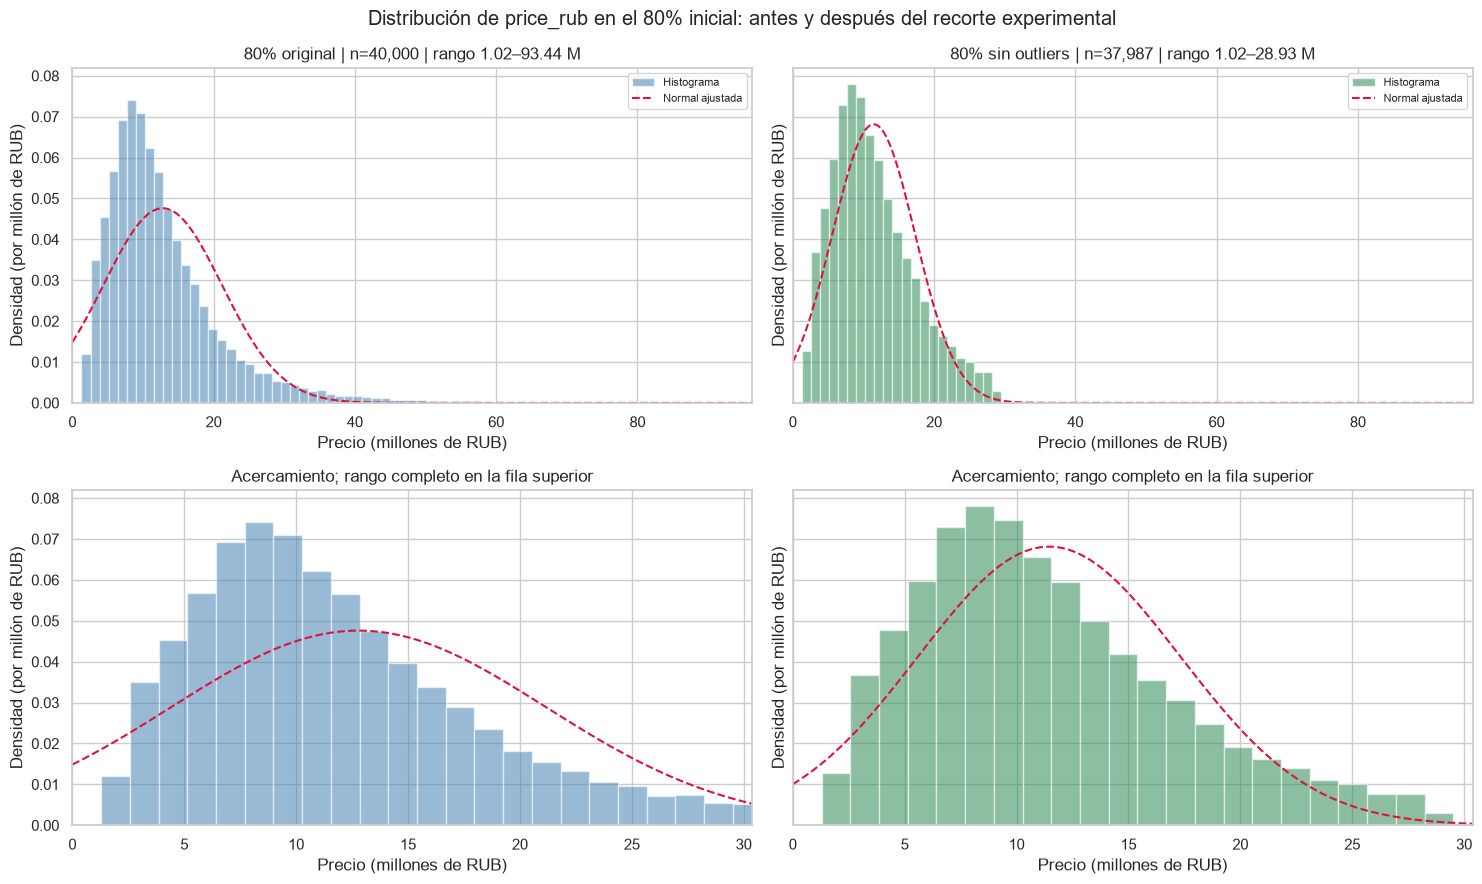

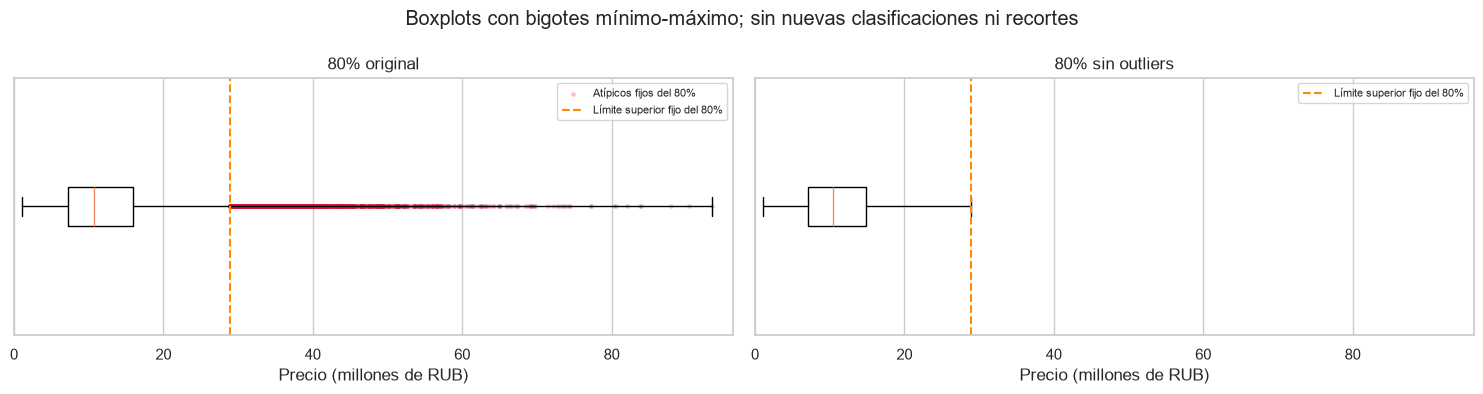

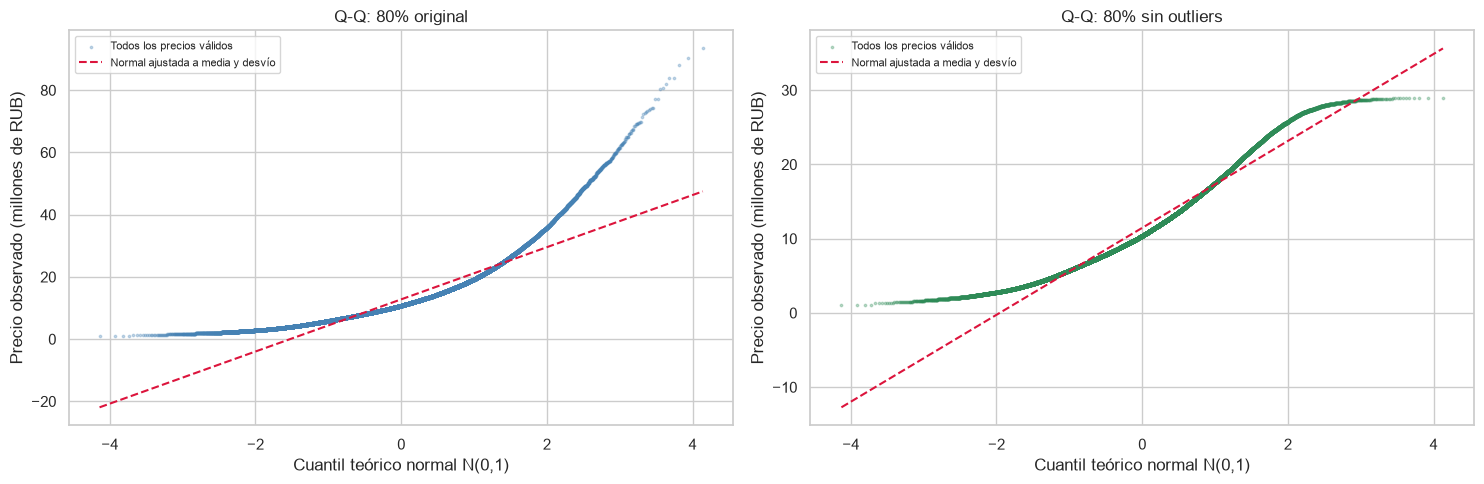

In [ ]:
escenarios_graficos_exp80 = {"80% original":precios_80_original_exp,"80% sin outliers":precios_80_recortado_exp}
colores_exp80 = {"80% original":"steelblue","80% sin outliers":"seagreen"}
maximo_histograma_exp80 = precios_80_original_exp.max()/1e6*1.03
bordes_histograma_exp80 = np.linspace(0,maximo_histograma_exp80,76)
grilla_normal_exp80 = np.linspace(0,maximo_histograma_exp80,400)
fig,axes=plt.subplots(2,2,figsize=(15,9),sharey=True)
for columna,(nombre,serie) in enumerate(escenarios_graficos_exp80.items()):
    referencia_normal = norm.pdf(grilla_normal_exp80,loc=serie.mean()/1e6,scale=serie.std(ddof=1)/1e6)
    for fila in range(2):
        ax=axes[fila,columna]
        ax.hist(serie/1e6,bins=bordes_histograma_exp80,density=True,alpha=.55,color=colores_exp80[nombre],label="Histograma")
        ax.plot(grilla_normal_exp80,referencia_normal,color="crimson",linestyle="--",label="Normal ajustada")
        ax.set(xlabel="Precio (millones de RUB)",ylabel="Densidad (por millón de RUB)")
        if fila==0:
            ax.set_xlim(0,maximo_histograma_exp80)
            ax.set_title(f"{nombre} | n={len(serie):,} | rango {serie.min()/1e6:.2f}–{serie.max()/1e6:.2f} M")
            ax.legend(fontsize=8)
        else:
            ax.set_xlim(0,precios_80_recortado_exp.max()/1e6*1.05)
            ax.set_title("Acercamiento; rango completo en la fila superior")
fig.suptitle("Distribución de price_rub en el 80% inicial: antes y después del recorte experimental")
fig.tight_layout();plt.show()

fig,axes=plt.subplots(1,2,figsize=(15,4),sharex=True)
for ax,(nombre,serie) in zip(axes,escenarios_graficos_exp80.items()):
    ax.boxplot(serie.to_numpy(dtype=float)/1e6,orientation="horizontal",whis=(0,100),showfliers=False)
    if nombre=="80% original":
        precios_atipicos_grafico = outliers_80_exp["price_rub"].to_numpy(dtype=float)/1e6
        ax.scatter(precios_atipicos_grafico,np.ones(len(precios_atipicos_grafico)),s=6,alpha=.18,color="crimson",label="Atípicos fijos del 80%")
    ax.axvline(limite_superior_exp80/1e6,color="darkorange",linestyle="--",label="Límite superior fijo del 80%")
    ax.set(title=nombre,xlabel="Precio (millones de RUB)",xlim=(0,maximo_histograma_exp80),yticks=[])
    ax.legend(fontsize=8)
fig.suptitle("Boxplots con bigotes mínimo-máximo; sin nuevas clasificaciones ni recortes")
fig.tight_layout();plt.show()

fig,axes=plt.subplots(1,2,figsize=(15,5),sharex=True)
for ax,(nombre,serie) in zip(axes,escenarios_graficos_exp80.items()):
    cuantiles_normales_exp80,ordenados_exp80 = probplot(serie.to_numpy(dtype=float),dist="norm",fit=False)
    ax.scatter(cuantiles_normales_exp80,ordenados_exp80/1e6,s=3,alpha=.3,color=colores_exp80[nombre],rasterized=True,label="Todos los precios válidos")
    ax.plot(cuantiles_normales_exp80,(serie.mean()+serie.std(ddof=1)*cuantiles_normales_exp80)/1e6,
            color="crimson",linestyle="--",label="Normal ajustada a media y desvío")
    ax.set(title=f"Q-Q: {nombre}",xlabel="Cuantil teórico normal N(0,1)",ylabel="Precio observado (millones de RUB)")
    ax.legend(fontsize=8)
fig.tight_layout();plt.show()

#### 7.5.5. Interpretación y conclusión del experimento

Los efectos sobre el 80% se valoran por sus estadísticas y gráficos, sin asumir que quitar extremos produzca normalidad y sin tomar una decisión definitiva para futuros modelos.

In [ ]:
def cambio_indicador_exp80(indicador):
    inicial=comparacion_distribuciones_exp80.loc[indicador,"80% original"]
    final=comparacion_distribuciones_exp80.loc[indicador,"80% sin outliers"]
    return (final/inicial-1)*100 if inicial else np.nan
display(Markdown(
    f"**Identificación:** dentro de {len(df_80_original_exp):,} anuncios iniciales, se identifican "
    f"{len(outliers_80_exp):,} atípicos ({resumen_outliers_exp80['outliers_pct_total_80']:.4f} %): "
    f"{int(outliers_inferiores_exp80.sum()):,} inferiores y {int(outliers_superiores_exp80.sum()):,} superiores. "
    f"Q1={q1_exp80:,.0f}, Q3={q3_exp80:,.0f} e IQR={iqr_exp80:,.0f} RUB; "
    f"los límites, calculados solo con el 80%, son {limite_inferior_exp80:,.0f} y {limite_superior_exp80:,.0f} RUB.\n\n"
    f"**Efecto del recorte:** quedan {len(df_80_sin_outliers_exp):,} anuncios "
    f"({resumen_trimming_exp80['conservados_pct']:.4f} % del 80% original). La media cambia "
    f"{cambio_indicador_exp80('Media (RUB)'):.2f} %, la mediana {cambio_indicador_exp80('Mediana (RUB)'):.2f} % "
    f"y la desviación estándar {cambio_indicador_exp80('Desviación estándar (RUB)'):.2f} %. "
    f"La asimetría pasa de {estadisticas_80_original_exp['Asimetría']:.3f} a {estadisticas_80_recortado_exp['Asimetría']:.3f}; "
    f"el exceso de curtosis, de {estadisticas_80_original_exp['Curtosis (exceso)']:.3f} "
    f"a {estadisticas_80_recortado_exp['Curtosis (exceso)']:.3f}.\n\n"
    "**Forma y Q-Q:** el original muestra cola derecha larga y marcada separación de la recta en los precios altos. "
    "El recorte reduce esa cola y mejora la proximidad relativa a la referencia, pero mantiene asimetría positiva, "
    "curvatura y desajustes en ambas colas; el extremo superior queda truncado. Un exceso de curtosis cercano a cero "
    "no compensa por sí solo esas diferencias ni demuestra normalidad. Los boxplots resumen el estrechamiento "
    "del rango y no se utilizan para una segunda eliminación.\n\n"
    "**¿La distribución resultante se aproxima razonablemente a una normal?** Mejora respecto del original, "
    "pero las desviaciones persistentes impiden considerarla una aproximación normal global satisfactoria "
    "solo por retirar estos casos. El objetivo de reducir la cola extrema se cumple; el de obtener normalidad "
    "no queda demostrado. La evidencia se basa en momentos y Q-Q, sin depender de un p-valor sensible al gran tamaño muestral.\n\n"
    "**Alcance:** retirar anuncios de mayor valor puede cambiar la representatividad del segmento inmobiliario. "
    "La normalidad marginal de price_rub no es un requisito de OLS: la normalidad relevante para la inferencia clásica "
    "se refiere a los errores del modelo y requerirá analizar sus residuos. No se adopta este recorte como tratamiento "
    "definitivo. El 20% final permanece separado e íntegro y no se ha usado para calcular distribuciones, límites "
    "ni curvas normales en esta subsección."
))
pd.testing.assert_frame_equal(df_venta_enriquecido,referencia_integrado_exp80)
pd.testing.assert_frame_equal(df_80_original_exp,referencia_integrado_exp80.iloc[:corte_posicional_exp80])
pd.testing.assert_frame_equal(df_20_reservado_exp,referencia_20_exp80)
pd.testing.assert_frame_equal(df_20_reservado_exp,referencia_integrado_exp80.iloc[corte_posicional_exp80:])
pd.testing.assert_frame_equal(df_80_sin_outliers_exp,df_80_original_exp.loc[~mascara_outliers_exp80])
assert df_80_sin_outliers_exp["date_posted_dt"].dropna().is_monotonic_increasing
if huella_csv_antes_exp80 is not None:
    assert hashlib.sha256(OUTPUT_PATH.read_bytes()).hexdigest()==huella_csv_antes_exp80
print("Experimento 80% finalizado: integrado, 80% original, reserva del 20% y CSV intactos; no se exportan tratamientos.")

Experimento 80% finalizado: integrado, 80% original, reserva del 20% y CSV intactos; no se exportan tratamientos.


**Identificación:** dentro de 40,000 anuncios iniciales, se identifican 2,013 atípicos (5.0325 %): 0 inferiores y 2,013 superiores. Q1=7,282,000, Q3=15,942,250 e IQR=8,660,250 RUB; los límites, calculados solo con el 80%, son -5,708,375 y 28,932,625 RUB.

**Efecto del recorte:** quedan 37,987 anuncios (94.9675 % del 80% original). La media cambia -10.43 %, la mediana -3.54 % y la desviación estándar -30.15 %. La asimetría pasa de 2.027 a 0.742; el exceso de curtosis, de 6.817 a 0.049.

**Forma y Q-Q:** el original muestra cola derecha larga y marcada separación de la recta en los precios altos. El recorte reduce esa cola y mejora la proximidad relativa a la referencia, pero mantiene asimetría positiva, curvatura y desajustes en ambas colas; el extremo superior queda truncado. Un exceso de curtosis cercano a cero no compensa por sí solo esas diferencias ni demuestra normalidad. Los boxplots resumen el estrechamiento del rango y no se utilizan para una segunda eliminación.

**¿La distribución resultante se aproxima razonablemente a una normal?** Mejora respecto del original, pero las desviaciones persistentes impiden considerarla una aproximación normal global satisfactoria solo por retirar estos casos. El objetivo de reducir la cola extrema se cumple; el de obtener normalidad no queda demostrado. La evidencia se basa en momentos y Q-Q, sin depender de un p-valor sensible al gran tamaño muestral.

**Alcance:** retirar anuncios de mayor valor puede cambiar la representatividad del segmento inmobiliario. La normalidad marginal de price_rub no es un requisito de OLS: la normalidad relevante para la inferencia clásica se refiere a los errores del modelo y requerirá analizar sus residuos. No se adopta este recorte como tratamiento definitivo. El 20% final permanece separado e íntegro y no se ha usado para calcular distribuciones, límites ni curvas normales en esta subsección.

## 8. Cobertura de estaciones de metro por distrito

Se comprueba si cada distrito tiene al menos una propiedad con un nombre de estación asociado no nulo ni vacío.

**Limitación:** una estación asociada a una propiedad no necesariamente está físicamente dentro del distrito.


In [ ]:
from IPython.display import Markdown

# La validación se realiza en una serie auxiliar; el integrado no se modifica.
estacion_valida_cobertura = (
    df_venta_enriquecido["metro_station"].astype("string").str.strip().ne("").fillna(False)
)
cobertura_metro_distrito = (
    estacion_valida_cobertura.groupby(df_venta_enriquecido["district"], observed=True, sort=True)
    .any().rename_axis("Distrito").reset_index(name="¿Tiene estación de metro?")
)
distritos_con_metro_cobertura = int(cobertura_metro_distrito["¿Tiene estación de metro?"].sum())
distritos_sin_metro_cobertura = len(cobertura_metro_distrito) - distritos_con_metro_cobertura
cobertura_metro_distrito["¿Tiene estación de metro?"] = (
    cobertura_metro_distrito["¿Tiene estación de metro?"].map({True: "Sí", False: "No"})
)
with pd.option_context("display.max_rows", None):
    display(cobertura_metro_distrito.style.hide(axis="index"))
display(Markdown(
    f"**Resumen:** {distritos_con_metro_cobertura} distritos tienen al menos una estación asociada "
    f"y {distritos_sin_metro_cobertura} no tienen ninguna."
))


Distrito,¿Tiene estación de metro?
Aeroport,Sí
Akademichesky,Sí
Alekseevsky,Sí
Altufyevsky,Sí
Arbat,Sí
Babushkinsky,Sí
Basmanny,Sí
Begovoy,Sí
Beskudnikovsky,Sí
Bibirevo,Sí


**Resumen:** 129 distritos tienen al menos una estación asociada y 0 no tienen ninguna.